# Milestone 1 — Formula 1 Podium Prediction Companion

**Task.** For every driver entering a race, predict whether they finish on the podium (`positionOrder <= 3`) using only information that is known **after qualifying and before the race starts**.

**Unit of analysis.** One row = one driver entering one race, so `(raceId, driverId)` must be unique in the modeling table.

**How this notebook is organised.** It follows the workflow taught in the course labs:
Lab 1 (inspect → missing values → clean → visualise), Lab 3 (Keras feed-forward network, early stopping, training curves), Lab 4 (SHAP / LIME, global vs local explanations). Every step follows the same pattern:

> **What** we check → **Why** it matters for podium prediction → **Evidence** (table / plot / statistic) → **Decision** → next step.

| § | Section | Milestone requirement |
|---|---|---|
| 0 | Setup | Run-all readiness |
| 1 | Raw data audit & EDA (before cleaning) | Initial EDA, sentinel discovery, PK/FK, duplicates |
| 2 | Cleaning + accuracy verification | Sentinels, semantic typing, PK/FK, grain, status taxonomy, data correctness |
| 3 | Post-cleaning EDA (before → after) | EDA after cleaning |
| 4 | Data-engineering questions Q1–Q3 | Multi-hop joins, answers + plots |
| 5 | Leakage-safe feature engineering + automated leakage tests | Form/standings/grid features |
| 6 | Train / validation / test split (needed *before* any data-driven selection) | Proper splitting |
| 7 | Feature selection evidence: grid vs qualifying, training window (1950), feature-set experiments | Feature justification, plots of feature effects |
| 8 | Preprocessing + preprocessing-order experiments | Effect of preprocessing, ≥2 order experiments |
| 9 | Modeling: baseline, statistical models, shallow NN, comparison table | ≥3 modeling attempts, metrics on train/val/test |
| 10 | Feature-group ablation | Ablation |
| 11 | XAI: permutation importance, SHAP, local SHAP, LIME | Global + local explanations |
| 12 | Inference function | Complete + partially-missing record |
| 13 | Selected features, limitations, requirement audit | Report material |

### Notes on the provided materials (stated up front, not assumed away)

1. **No F1 lab notebook was provided.** The materials contain the Lab 0, 1, 3 and 4 manuals, the milestone brief, the "F1 for Newcomers" guide and the raw Kaggle CSVs. The workflow and coding style below are therefore modelled on the lab *manuals*. The Lab 2 manual (statistical ML, metrics) was also not provided, so model-evaluation conventions come from the milestone brief itself.
2. **Metric count conflict in the brief.** Section 4 lists three metrics (ROC-AUC, PR-AUC, F1), but Deliverable 4 asks for "all five metrics from Section 4". The two extra metrics are not named anywhere. **Decision:** we report the three named metrics plus **precision and recall** (the two components F1 is built from). We also show accuracy to explain why it is not used. This is an interpretation, flagged here so it can be checked with the TAs.
3. **Split boundaries.** The "F1 for Newcomers" glossary gives the course split: *train ≤ 2019, validation 2020–2021, test ≥ 2022*. We adopt it and justify it in §6.

## 0. Setup

**What:** import libraries, fix random seeds, locate the data folder.

**Why each library is needed:**

| Library | Used for | Lab |
|---|---|---|
| `pandas`, `numpy` | loading the relational CSVs, joins, group-by features | Lab 1 |
| `matplotlib`, `seaborn` | every EDA / evaluation plot | Lab 1 |
| `scikit-learn` | imputation, scaling, logistic regression, random forest, gradient boosting, metrics, permutation importance | Labs 3–4 |
| `tensorflow.keras` | shallow feed-forward neural network with early stopping | Lab 3 |
| `shap`, `lime` | global and local explanations | Lab 4 |

**Run-all readiness:** the data path is detected automatically (Kaggle input folder or a local `data/` folder), and `shap`/`lime` are installed only if missing, exactly as Lab 4 does with `!pip install shap lime`.

In [1]:
import os, sys, glob, re, time, warnings, subprocess, importlib
warnings.filterwarnings('ignore')
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'   # hide TensorFlow C++ info/warning/error log spam

# Install XAI libraries only if they are not present (Lab 4 does `!pip install shap lime`)
for pkg in ['shap', 'lime']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', pkg])

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, accuracy_score, roc_curve, precision_recall_curve,
                             confusion_matrix)
from sklearn.inspection import permutation_importance

import tensorflow as tf
tf.get_logger().setLevel('ERROR')
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.callbacks import EarlyStopping

import shap
import lime, lime.lime_tabular
from IPython.display import display

SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
try:
    tf.config.experimental.enable_op_determinism()   # makes the NN results reproducible on CPU
except Exception:
    pass

pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
sns.set_theme(style='whitegrid', context='notebook')

# ---- locate the 14 CSVs (Kaggle input or a local folder) ----
candidates = glob.glob('/kaggle/input/**/results.csv', recursive=True) + \
             glob.glob('./data/results.csv') + glob.glob('./results.csv') + \
             glob.glob('../data/results.csv')
assert candidates, 'results.csv not found - attach the Kaggle F1 dataset or put the CSVs in ./data/'
DATA_DIR = os.path.dirname(candidates[0])
print('Data folder :', DATA_DIR)
print('Versions    : pandas', pd.__version__, '| sklearn', __import__('sklearn').__version__,
      '| tensorflow', tf.__version__, '| shap', shap.__version__)

Data folder : ./data
Versions    : pandas 3.0.2 | sklearn 1.8.0 | tensorflow 2.21.0 | shap 0.52.0


---
## 1. Raw data audit & EDA — *before* cleaning

Lab 1 starts every dataset with "check the structure → summary statistics → missing values → categorical features" *before* touching anything. We do the same, but for 14 linked tables, and **programmatically** (the brief explicitly forbids EDA by manual inspection).

### 1.1 Load the raw tables as untouched text

**What:** read every CSV with `dtype=str, keep_default_na=False`, so pandas does not convert or interpret anything.

**Why:** the brief says raw CSVs must stay immutable and cleaning must happen on copies. Reading as plain text lets us *see* the raw encoding, including placeholder strings such as `\N`, before deciding what they mean. The dictionary `raw` is never modified after this cell; every later step works on copies.

In [2]:
TABLES = ['circuits', 'constructors', 'constructor_results', 'constructor_standings', 'drivers',
          'driver_standings', 'races', 'results', 'qualifying', 'lap_times', 'pit_stops',
          'sprint_results', 'seasons', 'status']

raw = {t: pd.read_csv(os.path.join(DATA_DIR, f'{t}.csv'), dtype=str, keep_default_na=False)
       for t in TABLES}

overview = pd.DataFrame({
    'rows': {t: df.shape[0] for t, df in raw.items()},
    'columns': {t: df.shape[1] for t, df in raw.items()},
    'column names': {t: ', '.join(df.columns) for t, df in raw.items()},
})
overview

,rows,columns,column names
circuits,77,9,"circuitId, circuitRef, name, location, country..."
constructors,212,5,"constructorId, constructorRef, name, nationali..."
constructor_results,12625,5,"constructorResultsId, raceId, constructorId, p..."
constructor_standings,13391,7,"constructorStandingsId, raceId, constructorId,..."
drivers,861,9,"driverId, driverRef, number, code, forename, s..."
driver_standings,34863,7,"driverStandingsId, raceId, driverId, points, p..."
races,1125,18,"raceId, year, round, circuitId, name, date, ti..."
results,26759,18,"resultId, raceId, driverId, constructorId, num..."
qualifying,10494,9,"qualifyId, raceId, driverId, constructorId, nu..."
lap_times,589081,6,"raceId, driverId, lap, position, time, millise..."


**What the output shows:** all 14 tables named in the brief are present, with their row/column counts. `lap_times` is by far the largest table, and `results` is the table that holds our target (`positionOrder`).

**Decision:** `results` will be the backbone of the modeling table (one row per driver entry). The other tables are attached through keys, which is why §1.4–1.5 check those keys.

### 1.2 What does pandas do with the raw files by default?

**What:** read `results.csv` the "naïve" way, `pd.read_csv` with default settings, and look at the inferred dtypes.

**Why:** Lab 1 begins with `df.info()`. If numeric columns come back as `object`, something non-numeric is hiding inside them, and any model or join on those columns would silently misbehave.

In [3]:
naive_results = pd.read_csv(os.path.join(DATA_DIR, 'results.csv'))
dtype_check = pd.DataFrame({'naive dtype': naive_results.dtypes.astype(str),
                            'example values': naive_results.iloc[0].astype(str)})
dtype_check

,naive dtype,example values
resultId,int64,1
raceId,int64,18
driverId,int64,1
constructorId,int64,1
number,str,22
grid,int64,1
position,str,1
positionText,str,1
positionOrder,int64,1
points,float64,10.0



**What the output shows:** with default settings pandas reads `number`, `position`, `milliseconds`, `fastestLap`, `rank` and `fastestLapSpeed` as **text** (`str`/`object`), although they are numbers. The example row shows why: the value itself looks numeric, but somewhere further down the column a non-numeric token (`\N`) forces the whole column to text. `time` and `fastestLapTime` are text for a second reason: they are durations written as `m:ss.sss`.

**Why it matters:** sorting or averaging a text column gives wrong answers silently ("10" < "9"). `isna()` also reports **0 missing values** for these columns, because `\N` is a string, not NaN. Missingness is invisible until we find the sentinel.

**Decision:** read everything as text first (§1.1), find the sentinels (§1.3), then assign every column an explicit type in §2.1.


### 1.3 Sentinel audit — how much `\N` is in every table?

**What:** count the literal string `\N` (and empty strings) in every column of every table.

**Why:** `\N` is the Ergast export's placeholder for "no value". It is a **sentinel**, not a real value. We need to know where it lives, and how much of it there is, before deciding how to treat each case.

In [4]:
rows = []
for t, df in raw.items():
    for col in df.columns:
        n_sentinel = (df[col] == '\\N').sum()
        n_empty = (df[col].str.strip() == '').sum()
        if n_sentinel or n_empty:
            rows.append({'table': t, 'column': col, 'n_rows': len(df),
                         'n_\\N': n_sentinel, 'n_empty': n_empty,
                         'pct_\\N': round(100 * n_sentinel / len(df), 1)})
sentinel_audit = pd.DataFrame(rows).sort_values('pct_\\N', ascending=False)
print('Tables containing \\N:', sentinel_audit.table.nunique(), '| columns affected:', len(sentinel_audit),
      '| total \\N cells:', sentinel_audit['n_\\N'].sum(), '| empty strings:', sentinel_audit['n_empty'].sum())
sentinel_audit

Tables containing \N: 6 | columns affected: 30 | total \N cells: 160076 | empty strings: 68


,table,column,n_rows,n_\N,n_empty,pct_\N
0,constructor_results,status,12625,12608,0,99.9
13,races,sprint_time,1125,1110,0,98.7
12,races,sprint_date,1125,1107,0,98.4
9,races,fp3_time,1125,1072,0,95.3
7,races,fp2_time,1125,1057,0,94.0
5,races,fp1_time,1125,1057,0,94.0
11,races,quali_time,1125,1057,0,94.0
8,races,fp3_date,1125,1053,0,93.6
1,drivers,number,861,802,0,93.1
4,races,fp1_date,1125,1035,0,92.0


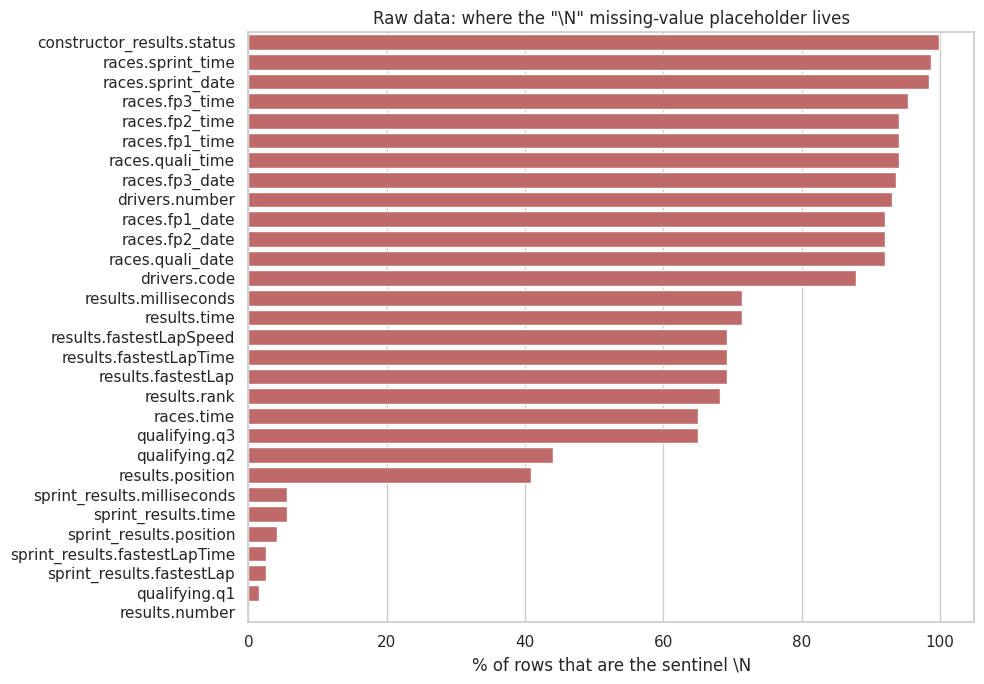

In [5]:
fig, ax = plt.subplots(figsize=(10, 7))
plot_df = sentinel_audit.assign(label=sentinel_audit.table + '.' + sentinel_audit.column)
sns.barplot(data=plot_df, y='label', x='pct_\\N', ax=ax, color='indianred')
ax.set_xlabel('% of rows that are the sentinel \\N'); ax.set_ylabel('')
ax.set_title('Raw data: where the "\\N" missing-value placeholder lives')
plt.tight_layout(); plt.show()


**What the output shows:** 160,076 `\N` cells in 30 columns of 6 tables, plus 68 empty strings (all in `qualifying.q2/q3`). They fall into three different meanings:

| Pattern | Columns | Meaning | Treatment |
|---|---|---|---|
| **Structurally not applicable** | `races.fp*/quali_*/sprint_*` (92–99%), `drivers.number/code` (88–93%), `constructor_results.status` (99.9%) | session dates/times were only recorded from ~2021; permanent numbers and 3-letter codes only exist for modern drivers | NaN; never used as features |
| **Outcome-dependent** | `results.position` (41%), `time`/`milliseconds` (71%), `fastestLap*`/`rank` (68–69%) | a driver who did not finish has no classified position or race time; fastest-lap data starts only in 2004 | NaN; these are **post-race** and never features (§5.1) |
| **Session not reached / not recorded** | `qualifying.q2` (44%), `q3` (65%), `q1` (1.5%) | a driver eliminated in Q1 has no Q2/Q3 time; q1 missing = no time set | NaN; qualifying times are only used descriptively (§1, Q1), never as model features (§5.2) |

**Decision:** in every case `\N` means "no value", so it becomes NaN. Because the reasons differ, we never blanket-impute: each feature handles its own missingness in §5/§8.


### 1.4 Primary-key audit (raw)

**What:** for every table, check that its primary key (the column(s) that should identify a row uniquely) has **no nulls/sentinels** and **no duplicates**. We also check the "natural" keys that our modeling grain depends on, e.g. `(raceId, driverId)` in `results`.

**Why:** if a key is not unique, every join on it multiplies rows. In our case that would create several "predictions" for the same driver in the same race.

**How:** `check_primary_keys()` is a reusable function. We run it now on the raw text and again after cleaning (§2.4), which gives the before/after evidence.

In [6]:
PRIMARY_KEYS = {
    'circuits': ['circuitId'], 'constructors': ['constructorId'], 'drivers': ['driverId'],
    'races': ['raceId'], 'seasons': ['year'], 'status': ['statusId'],
    'results': ['resultId'], 'qualifying': ['qualifyId'], 'sprint_results': ['resultId'],
    'constructor_results': ['constructorResultsId'], 'constructor_standings': ['constructorStandingsId'],
    'driver_standings': ['driverStandingsId'],
    'lap_times': ['raceId', 'driverId', 'lap'], 'pit_stops': ['raceId', 'driverId', 'stop'],
}
# Natural (business) keys that must also be unique for our joins to be one-to-one
NATURAL_KEYS = {
    'results': ['raceId', 'driverId'],             # <- the modeling grain
    'qualifying': ['raceId', 'driverId'],
    'driver_standings': ['raceId', 'driverId'],
    'constructor_standings': ['raceId', 'constructorId'],
    'races': ['year', 'round'],
}

def check_primary_keys(tables, keys, missing_token='\\N'):
    out = []
    for t, cols in keys.items():
        df = tables[t]
        null_mask = df[cols].isna().any(axis=1) | (df[cols].astype(str) == missing_token).any(axis=1)
        out.append({'table': t, 'key': '+'.join(cols), 'rows': len(df),
                    'null/sentinel keys': int(null_mask.sum()),
                    'duplicate keys': int(df.duplicated(cols).sum()),
                    'unique & non-null': bool(null_mask.sum() == 0 and df.duplicated(cols).sum() == 0)})
    return pd.DataFrame(out)

pk_raw = pd.concat([check_primary_keys(raw, PRIMARY_KEYS).assign(kind='primary'),
                    check_primary_keys(raw, NATURAL_KEYS).assign(kind='natural')], ignore_index=True)
pk_raw

,table,key,rows,null/sentinel keys,duplicate keys,unique & non-null,kind
0,circuits,circuitId,77,0,0,True,primary
1,constructors,constructorId,212,0,0,True,primary
2,drivers,driverId,861,0,0,True,primary
3,races,raceId,1125,0,0,True,primary
4,seasons,year,75,0,0,True,primary
5,status,statusId,139,0,0,True,primary
6,results,resultId,26759,0,0,True,primary
7,qualifying,qualifyId,10494,0,0,True,primary
8,sprint_results,resultId,360,0,0,True,primary
9,constructor_results,constructorResultsId,12625,0,0,True,primary



**What the output shows:** all 14 **primary keys** are unique and contain no sentinel. Among the **natural keys**, `qualifying`, `driver_standings`, `constructor_standings` and `races (year, round)` are unique, but **`results (raceId, driverId)` has 91 duplicate rows**.

**Why it matters:** `(raceId, driverId)` is exactly our modeling grain. Without a fix, those drivers would appear twice in the same race, with two different labels and two different grid slots. §1.7 investigates why, and §2.6 fixes it.


### 1.5 Foreign-key audit (raw)

**What:** for every column that references another table (e.g. `results.driverId → drivers.driverId`), count the values that do **not** exist in the referenced table ("orphans").

**Why:** the brief requires foreign keys to *reconcile*. An orphan would silently disappear in an inner join or produce NaNs in a left join. We also check two cross-table consistency rules that matter for features: every qualifying entry and every lap-time entry should belong to a driver who has a race result.

In [7]:
FOREIGN_KEYS = [  # (child table, child column, parent table, parent column)
    ('races', 'circuitId', 'circuits', 'circuitId'), ('races', 'year', 'seasons', 'year'),
    ('results', 'raceId', 'races', 'raceId'), ('results', 'driverId', 'drivers', 'driverId'),
    ('results', 'constructorId', 'constructors', 'constructorId'), ('results', 'statusId', 'status', 'statusId'),
    ('qualifying', 'raceId', 'races', 'raceId'), ('qualifying', 'driverId', 'drivers', 'driverId'),
    ('qualifying', 'constructorId', 'constructors', 'constructorId'),
    ('driver_standings', 'raceId', 'races', 'raceId'), ('driver_standings', 'driverId', 'drivers', 'driverId'),
    ('constructor_standings', 'raceId', 'races', 'raceId'),
    ('constructor_standings', 'constructorId', 'constructors', 'constructorId'),
    ('constructor_results', 'raceId', 'races', 'raceId'),
    ('constructor_results', 'constructorId', 'constructors', 'constructorId'),
    ('lap_times', 'raceId', 'races', 'raceId'), ('lap_times', 'driverId', 'drivers', 'driverId'),
    ('pit_stops', 'raceId', 'races', 'raceId'), ('pit_stops', 'driverId', 'drivers', 'driverId'),
    ('sprint_results', 'raceId', 'races', 'raceId'), ('sprint_results', 'driverId', 'drivers', 'driverId'),
    ('sprint_results', 'constructorId', 'constructors', 'constructorId'),
    ('sprint_results', 'statusId', 'status', 'statusId'),
]

def check_foreign_keys(tables, fks):
    out = []
    for child, ccol, parent, pcol in fks:
        child_vals = tables[child][ccol].astype(str)
        parent_vals = set(tables[parent][pcol].astype(str))
        orphans = ~child_vals.isin(parent_vals)
        out.append({'child': f'{child}.{ccol}', 'parent': f'{parent}.{pcol}',
                    'child rows': len(child_vals), 'orphan rows': int(orphans.sum()),
                    'reconciles': bool(orphans.sum() == 0)})
    return pd.DataFrame(out)

fk_raw = check_foreign_keys(raw, FOREIGN_KEYS)

# Cross-table consistency: entries that should also appear in results
res_pairs = set(zip(raw['results'].raceId, raw['results'].driverId))
cross = pd.DataFrame([
    {'check': 'qualifying (raceId, driverId) present in results',
     'violations': sum((r, d) not in res_pairs for r, d in zip(raw['qualifying'].raceId, raw['qualifying'].driverId))},
    {'check': 'lap_times (raceId, driverId) present in results',
     'violations': sum((r, d) not in res_pairs for r, d in set(zip(raw['lap_times'].raceId, raw['lap_times'].driverId)))},
    {'check': 'races without any result row',
     'violations': int((~raw['races'].raceId.isin(raw['results'].raceId)).sum())},
])
display(fk_raw)
cross

,child,parent,child rows,orphan rows,reconciles
0,races.circuitId,circuits.circuitId,1125,0,True
1,races.year,seasons.year,1125,0,True
2,results.raceId,races.raceId,26759,0,True
3,results.driverId,drivers.driverId,26759,0,True
4,results.constructorId,constructors.constructorId,26759,0,True
5,results.statusId,status.statusId,26759,0,True
6,qualifying.raceId,races.raceId,10494,0,True
7,qualifying.driverId,drivers.driverId,10494,0,True
8,qualifying.constructorId,constructors.constructorId,10494,0,True
9,driver_standings.raceId,races.raceId,34863,0,True


,check,violations
0,"qualifying (raceId, driverId) present in results",0
1,"lap_times (raceId, driverId) present in results",0
2,races without any result row,0



**What the output shows:** all 23 foreign-key relationships reconcile (0 orphans), every qualifying and lap-time entry belongs to a driver with a race result, and every race has at least one result row (the dataset contains no future, not-yet-run races).

**Decision:** joins can be done without losing or inventing rows. We re-run the same check after cleaning (§2.4) to prove typing did not break any key.


### 1.6 Distributions that matter for podium prediction

We now look at the raw numbers through the lens of the task. For this step only, we make a **temporary** typed view of a few raw columns (`pd.to_numeric(..., errors='coerce')`), which turns `\N` into NaN. The proper, documented typing is done in §2.

#### 1.6.1 Season length, field size and the podium base rate

**What:** races per season, average entries per race, and the share of entries that end on the podium.

**Why:** the "F1 for Newcomers" guide warns that 1950s–1990s fields were much larger and less uniform. Exactly 3 podium places per race means that **the base rate of the target depends on field size**. That matters for class imbalance and for whether old seasons resemble the seasons we want to predict.

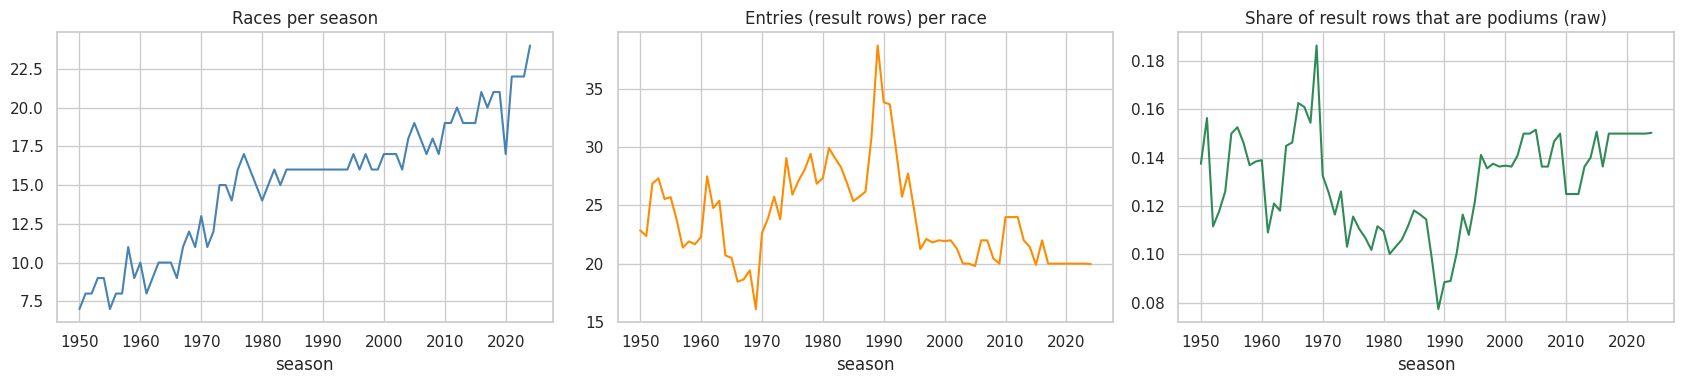

Overall raw podium rate: 0.1269
      races  entries  podium_rate  entries_per_race
year                                               
1950      7      160        0.138            22.857
1975     14      363        0.116            25.929
1989     16      620        0.077            38.750
2000     17      373        0.137            21.941
2010     19      456        0.125            24.000
2024     24      479        0.150            19.958


In [8]:
tmp = raw['results'][['raceId', 'driverId', 'grid', 'positionOrder', 'positionText', 'laps', 'statusId']].copy()
for col in ['raceId', 'driverId', 'grid', 'positionOrder', 'laps', 'statusId']:
    tmp[col] = pd.to_numeric(tmp[col], errors='coerce')
tmp = tmp.merge(raw['races'][['raceId', 'year', 'name']].astype({'raceId': int, 'year': int}), on='raceId')
tmp['podium'] = (tmp.positionOrder <= 3).astype(int)

per_season = tmp.groupby('year').agg(races=('raceId', 'nunique'), entries=('driverId', 'size'),
                                     podium_rate=('podium', 'mean'))
per_season['entries_per_race'] = per_season.entries / per_season.races

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
per_season.races.plot(ax=axes[0], color='steelblue'); axes[0].set_title('Races per season')
per_season.entries_per_race.plot(ax=axes[1], color='darkorange'); axes[1].set_title('Entries (result rows) per race')
per_season.podium_rate.plot(ax=axes[2], color='seagreen'); axes[2].set_title('Share of result rows that are podiums (raw)')
for a in axes: a.set_xlabel('season')
plt.tight_layout(); plt.show()
print('Overall raw podium rate:', round(tmp.podium.mean(), 4))
print(per_season.loc[[1950, 1975, 1989, 2000, 2010, 2024]].round(3))


**What the output shows:** the calendar grew from 7 races (1950) to 24 (2024). Entries per race peaked at ~39 in 1989 (the pre-qualifying era, when more cars entered than were allowed to start) and are ~20 today. The raw podium share therefore moves with field size: **7.7% in 1989 vs 15.0% in 2024** (overall 12.7%).

**Why it matters:** (1) Old seasons are a different problem: the same model would face a target base rate twice as low. (2) Part of the 1980s–90s rows are cars that **never started** (DNQ/DNPQ), which §1.6.2 confirms. Both points motivate the eligibility rule (§2.5). Because the model is trained from 1950 (§7.1), the field size is also given to the model as a feature (`field_size`, §5.2), and §7.1.2 checks whether the old seasons hurt performance on modern races.


#### 1.6.2 The `grid` column: what does `grid = 0` mean?

**What:** the distribution of the starting position, with a closer look at `grid = 0`.

**Why:** grid is the strongest pre-race signal, according to the guide's glossary: "pole position: strongest single predictor of a podium". The guide says `0` means a pit-lane start but explicitly asks us to **verify in EDA**. If `0` actually also means "did not start", treating it as a pit-lane start would put non-starters into the modeling table.

Rows with grid == 0: 1638 (6.1% of all result rows)
  of which laps == 0: 1566 | laps > 0: 72

positionText letter codes among grid==0 rows (F = failed to qualify, W = withdrawn, R = retired, ...):
positionText
F                   1348
W                    203
numeric position      60
R                     14
E                      7
D                      6

Most common status among grid==0 rows:
status
Did not qualify       1013
Did not prequalify     331
Withdrew               164
+1 Lap                  27
Finished                22
Accident                20
Injury                   8
+2 Laps                  7


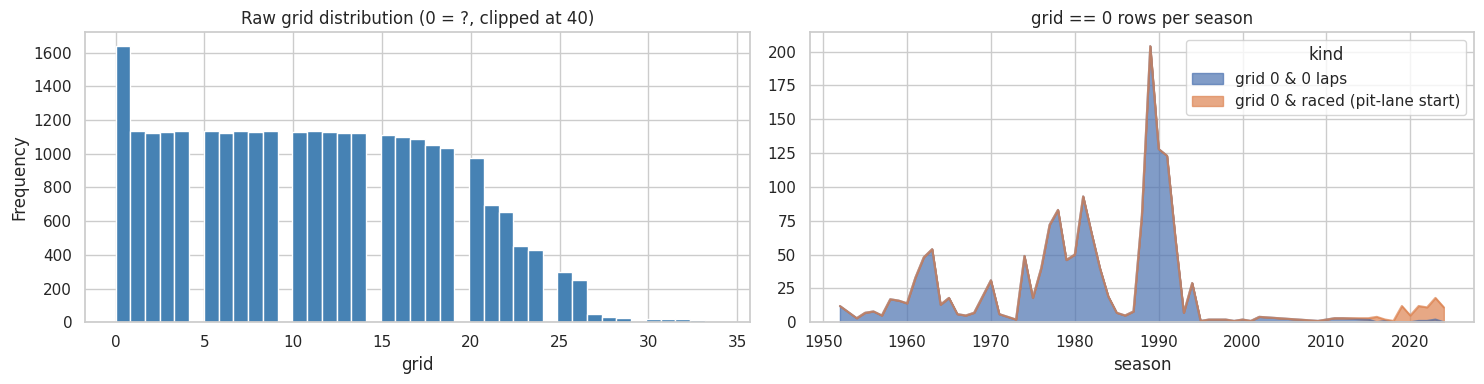

In [9]:
status_raw = raw['status'].astype({'statusId': int})
g0 = tmp[tmp.grid == 0].merge(status_raw, on='statusId')
print('Rows with grid == 0:', len(g0), f'({len(g0)/len(tmp):.1%} of all result rows)')
print('  of which laps == 0:', int((g0.laps == 0).sum()), '| laps > 0:', int((g0.laps > 0).sum()))
print('\npositionText letter codes among grid==0 rows (F = failed to qualify, W = withdrawn, R = retired, ...):')
print(g0.positionText.where(~g0.positionText.str.isdigit(), 'numeric position').value_counts().to_string())
print('\nMost common status among grid==0 rows:')
print(g0.status.value_counts().head(8).to_string())

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
tmp.grid.clip(upper=40).plot.hist(bins=41, ax=axes[0], color='steelblue')
axes[0].set_title('Raw grid distribution (0 = ?, clipped at 40)'); axes[0].set_xlabel('grid')
(g0.assign(kind=np.where(g0.laps > 0, 'grid 0 & raced (pit-lane start)', 'grid 0 & 0 laps'))
   .groupby(['year', 'kind']).size().unstack(fill_value=0).plot.area(ax=axes[1], alpha=.7))
axes[1].set_title('grid == 0 rows per season'); axes[1].set_xlabel('season')
plt.tight_layout(); plt.show()


**What the output shows:** 1,638 rows (6.1%) have `grid = 0`, but **only 72 of them completed any lap**. The rest are mainly `F` (failed to qualify, 1,348 rows) and `W` (withdrawn, 203); the top statuses are *Did not qualify* (1,013), *Did not prequalify* (331) and *Withdrew* (164).

**Conclusion (verifying the guide):** `grid = 0` is **overloaded**. It means a pit-lane start for only a small minority; for ~95% of rows it means *no grid slot at all*.

**Decision:** only the `F` rows (failed to qualify, known before the race) are removed (§2.5). All other `grid = 0` rows, real pit-lane starts and `W`/`E`/`D` entries, are kept. For the features, grid 0 becomes **field size + 1**, i.e. behind the last car on the grid, plus a `pitlane_start` flag (§5.3), instead of treating 0 as "better than pole".


#### 1.6.3 Qualifying coverage drift

**What:** for each season, the share of race entries that have a matching row in `qualifying.csv`.

**Why:** the brief names "historical qualifying-coverage drift" as a known limitation. The guide says *"we believe qualifying.csv begins in the mid-1990s, but that must be confirmed from our own copy."* If qualifying features are missing for whole eras, this plot decides whether we impute, fall back to grid, or restrict the training window.

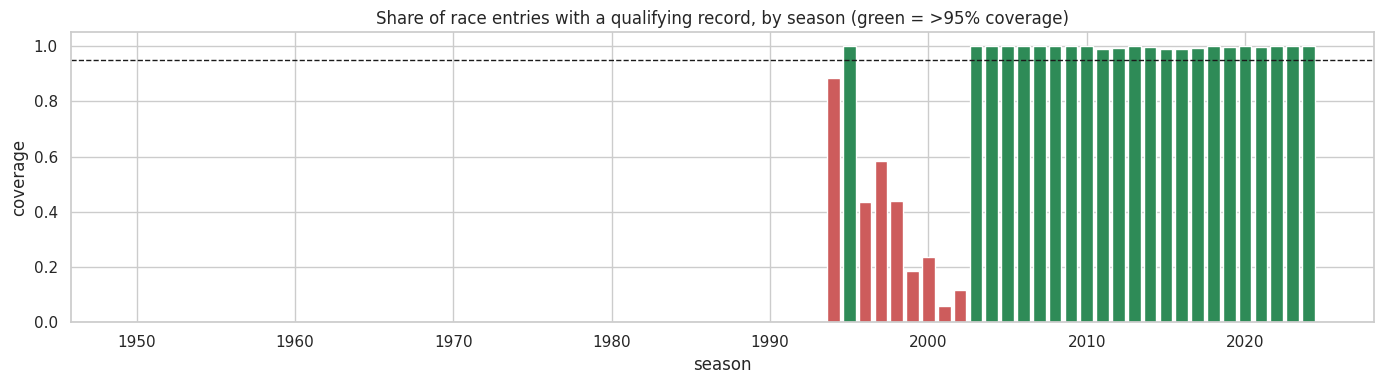

First season with any qualifying rows : 1994
Seasons with partial coverage (0<cov<95%): {1994: 0.88, 1996: 0.44, 1997: 0.59, 1998: 0.44, 1999: 0.18, 2000: 0.24, 2001: 0.06, 2002: 0.12}
First season from which coverage stays >95%: 2003


In [10]:
q_pairs = raw['qualifying'][['raceId', 'driverId']].astype(int).assign(has_quali=1)
cov = tmp.merge(q_pairs, on=['raceId', 'driverId'], how='left')
cov['has_quali'] = cov.has_quali.fillna(0)
q_cov = cov.groupby('year').has_quali.mean()

fig, ax = plt.subplots(figsize=(14, 4))
ax.bar(q_cov.index, q_cov.values, color=np.where(q_cov.values > .95, 'seagreen', 'indianred'))
ax.axhline(.95, ls='--', c='k', lw=1)
ax.set_title('Share of race entries with a qualifying record, by season (green = >95% coverage)')
ax.set_xlabel('season'); ax.set_ylabel('coverage')
plt.tight_layout(); plt.show()
print('First season with any qualifying rows :', int(q_cov[q_cov > 0].index.min()))
print('Seasons with partial coverage (0<cov<95%):', {int(k): round(v, 2) for k, v in q_cov[(q_cov > 0) & (q_cov < .95)].items()})
print('First season from which coverage stays >95%:',
      int(next(y for y in q_cov.index if (q_cov.loc[y:] > .95).all())))


**What the output shows (guide's belief confirmed):** qualifying data **begins in 1994** (88% coverage), drops to 6–59% in **1996–2002**, and is **>95% from 2003 onwards**.

**Why it matters:** any feature built from `qualifying.csv` would be missing for every season before 1994 and for much of 1996–2002, while every validation/test row has it.

**Decision:** the model does **not** use qualifying features; it uses the starting grid, which exists for every season. §7.1.1 shows that grid and qualifying position carry almost the same information (2003–2019), which is what makes training from 1950 possible.


#### 1.6.4 Qualifying position vs grid position

**What:** compare `qualifying.position` with `results.grid` for the same driver and race.

**Why:** Q1 asks us to distinguish the two, and the guide explains that grid penalties and pit-lane starts make them differ. If they differ often, they carry partly different information, which justifies keeping both as features and distinguishing them in Q1.

Entries with both values: 10494 | grid != qualifying position: 23.9%
Qualified on the front row (P1/P2) but did NOT start from grid 1-2: 36
Started from grid 1-2 without qualifying P1/P2: 36


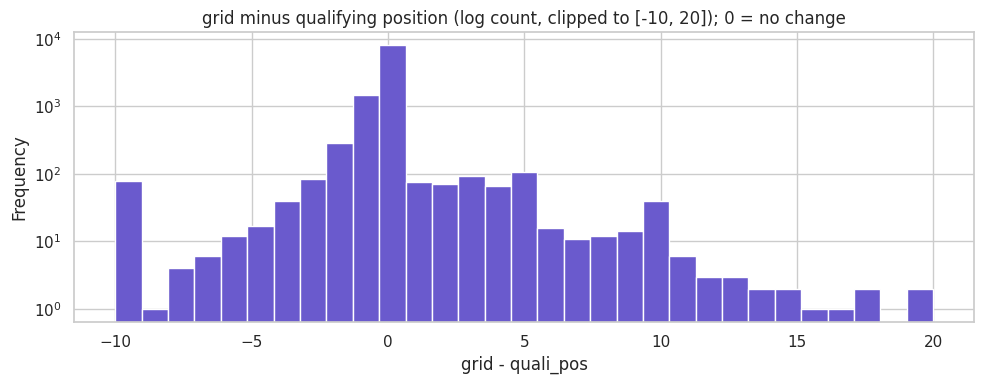

In [11]:
qg = raw['qualifying'][['raceId', 'driverId', 'position']].astype(int).rename(columns={'position': 'quali_pos'}) \
        .merge(tmp[['raceId', 'driverId', 'grid', 'year']], on=['raceId', 'driverId'])
qg['delta'] = qg.grid - qg.quali_pos
print(f"Entries with both values: {len(qg)} | grid != qualifying position: {(qg.delta != 0).mean():.1%}")
print(f"Qualified on the front row (P1/P2) but did NOT start from grid 1-2: {((qg.quali_pos <= 2) & (qg.grid > 2)).sum()}")
print(f"Started from grid 1-2 without qualifying P1/P2: {((qg.grid.between(1, 2)) & (qg.quali_pos > 2)).sum()}")
fig, ax = plt.subplots(figsize=(10, 4))
qg.delta.clip(-10, 20).plot.hist(bins=31, ax=ax, color='slateblue', log=True)
ax.set_title('grid minus qualifying position (log count, clipped to [-10, 20]); 0 = no change')
ax.set_xlabel('grid - quali_pos')
plt.tight_layout(); plt.show()


**What the output shows:** for **23.9%** of entries the grid slot differs from the qualifying position (penalties, pit-lane starts, disqualification from qualifying, grid reshuffles). 36 drivers qualified on the front row but started further back, and 36 started on the front row without qualifying there.

**Decision:** grid and qualifying position are related but not identical, so Q1 reports both definitions. For the model, §7.1.1 measures how much the difference matters for predicting a podium (it turns out to be very little), which justifies using the grid alone.


#### 1.6.5 Categorical consistency (nationalities and countries)

**What:** list the distinct values of `drivers.nationality` and `circuits.country`, and look programmatically for whitespace problems and for near-duplicate labels.

**Why:** Q2 (home race) has to match a driver nationality (e.g. "British") to a circuit country (e.g. "UK"). Lab 1 warns about inconsistent categories like "Male" / "male" / "M". Any inconsistency here would silently break that match.

In [12]:
def label_issues(series, name):
    vals = pd.Series(series.unique())
    ws = vals[vals != vals.str.strip()]
    print(f'{name}: {len(vals)} distinct values')
    print('  values with leading/trailing whitespace:', [repr(v) for v in ws])
    stripped = vals.str.strip().str.lower()
    # near-duplicates: share the first 6 letters (catches 'Argentine' / 'Argentinian')
    pref = stripped.str[:6]
    print('  possible near-duplicates (same 6-letter prefix):',
          [list(vals[pref == p]) for p in pref[pref.duplicated()].unique()])
    return vals

nat_vals = label_issues(raw['drivers'].nationality, 'drivers.nationality')
cty_vals = label_issues(raw['circuits'].country, 'circuits.country')
print('\nAll circuit countries:', sorted(cty_vals))

drivers.nationality: 43 distinct values
  values with leading/trailing whitespace: ["'Argentinian '"]
  possible near-duplicates (same 6-letter prefix): [['American', 'American-Italian'], ['Argentine', 'Argentine-Italian', 'Argentinian ']]
circuits.country: 35 distinct values
  values with leading/trailing whitespace: []
  possible near-duplicates (same 6-letter prefix): []

All circuit countries: ['Argentina', 'Australia', 'Austria', 'Azerbaijan', 'Bahrain', 'Belgium', 'Brazil', 'Canada', 'China', 'France', 'Germany', 'Hungary', 'India', 'Italy', 'Japan', 'Korea', 'Malaysia', 'Mexico', 'Monaco', 'Morocco', 'Netherlands', 'Portugal', 'Qatar', 'Russia', 'Saudi Arabia', 'Singapore', 'South Africa', 'Spain', 'Sweden', 'Switzerland', 'Turkey', 'UAE', 'UK', 'USA', 'United States']



**What the output shows:** two inconsistencies that would silently break the Q2 nationality ↔ country match:
1. `drivers.nationality` contains **`'Argentinian '`** (different spelling *and* a trailing space) next to `'Argentine'`;
2. `circuits.country` uses both **`USA`** and **`United States`** for the same country.

**Decision:** strip whitespace from every text column and harmonise these two labels in §2.1 (`Argentinian → Argentine`, `United States → USA`). The other near-duplicates (`American`/`American-Italian`, `Argentine-Italian`) are genuine dual nationalities and are kept; Q2 treats them explicitly.


#### 1.6.6 Status values

**What:** frequency of every finishing status.

**Why:** status is **post-race** and can never be a feature, but Q3 (mechanical retirements) and the reliability feature (built from *past* races only) need it grouped into meaningful classes. There are well over 100 status strings, so we look at their frequency first.

Distinct status strings: 139 | used in results: 137


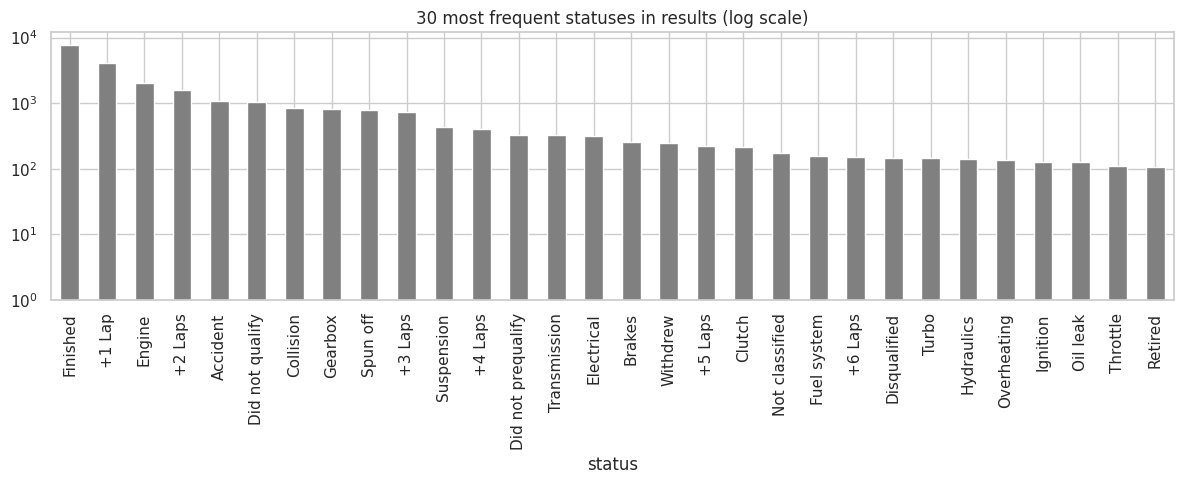

In [13]:
st_counts = tmp.merge(status_raw, on='statusId').status.value_counts()
print('Distinct status strings:', raw['status'].shape[0], '| used in results:', st_counts.shape[0])
fig, ax = plt.subplots(figsize=(12, 5))
st_counts.head(30).plot.bar(ax=ax, color='gray', log=True)
ax.set_title('30 most frequent statuses in results (log scale)')
plt.tight_layout(); plt.show()


**What the output shows:** 139 status strings, 137 of them used. Apart from *Finished* and the "+n Laps" family, the distribution has a long tail: a few big categories (Engine, Accident, Did not qualify, Collision, Gearbox…) and dozens of rare, very specific ones (Magneto, Oil pipe, Seat…).

**Decision:** 137 categories are unusable as they are, and the raw text mixes three very different causes (car failure, driver/crash, rule decision). §2.7 maps every string to five interpretable classes, with an assertion that no string is left unmapped.


### 1.7 Duplicate investigation: drivers with more than one row in the same race

**What:** find every `(raceId, driverId)` pair with more than one row in `results`, quantify it, and look at *why* it happens.

**Why:** the brief requires exactly one row per driver per race and says these duplicates come from **shared drives** in early F1. We must not drop rows arbitrarily: first understand them, then choose a rule (§2.6).

In [14]:
res_t = raw['results'].copy()
for col in ['raceId', 'driverId', 'constructorId', 'grid', 'positionOrder', 'laps', 'statusId', 'number']:
    res_t[col] = pd.to_numeric(res_t[col], errors='coerce')
res_t['points'] = pd.to_numeric(res_t.points, errors='coerce')
res_t = res_t.merge(raw['races'][['raceId', 'year', 'name']].astype({'raceId': int, 'year': int}), on='raceId') \
             .merge(status_raw, on='statusId')
dups = res_t[res_t.duplicated(['raceId', 'driverId'], keep=False)].sort_values(['raceId', 'driverId', 'positionOrder'])
pairs = dups.groupby(['raceId', 'driverId'])
print(f'Duplicate rows: {len(dups)} | affected (raceId, driverId) pairs: {pairs.ngroups}')
print('Rows per duplicated pair:', pairs.size().value_counts().to_dict())
print('Pairs by season:', {int(k): int(v) for k, v in dups.drop_duplicates(['raceId', 'driverId']).year.value_counts().sort_index().items()})
print('Pairs where the driver has >1 non-zero grid row (= drove two cars that both started):',
      int((pairs.grid.apply(lambda s: (s > 0).sum()) > 1).sum()))
print('Pairs where every row is grid 0 (two entries, neither started):',
      int((pairs.grid.apply(lambda s: (s > 0).sum()) == 0).sum()))
print('Pairs where at least one row is a podium:', int(pairs.positionOrder.apply(lambda s: (s <= 3).any()).sum()))
print('Pairs whose points are split (fractional points on some row):',
      int(pairs.points.apply(lambda s: (s % 1 != 0).any()).sum()))
dups[['year', 'name', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'positionText',
      'positionOrder', 'points', 'laps', 'status']].head(16)

Duplicate rows: 176 | affected (raceId, driverId) pairs: 85
Rows per duplicated pair: {2: 79, 3: 6}
Pairs by season: {1950: 4, 1951: 4, 1952: 3, 1953: 14, 1954: 16, 1955: 15, 1956: 12, 1957: 8, 1958: 3, 1960: 1, 1961: 2, 1962: 1, 1964: 1, 1978: 1}
Pairs where the driver has >1 non-zero grid row (= drove two cars that both started): 82
Pairs where every row is grid 0 (two entries, neither started): 3
Pairs where at least one row is a podium: 22
Pairs whose points are split (fractional points on some row): 9


,year,name,raceId,driverId,constructorId,number,grid,positionText,positionOrder,points,laps,status
13188,1978,Italian Grand Prix,540,229,54,10.0,0,F,26,0.0,0,Did not qualify
13191,1978,Italian Grand Prix,540,229,57,23.0,0,F,29,0.0,0,Did not prequalify
17362,1964,United States Grand Prix,717,373,172,1.0,1,7,7,0.0,102,Out of fuel
24298,1964,United States Grand Prix,717,373,172,2.0,1,R,12,0.0,54,Injection
17740,1962,British Grand Prix,733,465,172,48.0,0,W,22,0.0,0,Withdrew
17743,1962,British Grand Prix,733,465,97,50.0,0,W,25,0.0,0,Withdrew
17961,1961,British Grand Prix,742,475,102,26.0,20,D,19,0.0,56,Disqualified
17963,1961,British Grand Prix,742,475,172,28.0,5,R,21,0.0,44,Brakes
24297,1961,United States Grand Prix,745,418,172,21.0,15,11,11,0.0,92,+8 Laps
18062,1961,United States Grand Prix,745,418,172,22.0,11,R,17,0.0,23,Gearbox



**What the output shows:** 176 rows form **85 duplicated (raceId, driverId) pairs** (79 pairs of 2 rows, 6 of 3). Almost all are **1950–1964** (one 1978 case). In 82 pairs the driver has two or more rows with a real grid slot, i.e. he appears once per car (the **shared drives** described in the brief); 3 pairs are a driver entered in two cars that both failed to start. 22 pairs include a podium row, and 9 pairs have fractional (split) points.

**Why it matters:** dropping these rows arbitrarily could delete real podiums; keeping both would violate the grain. §2.6 compares explicit rules.


### 1.8 Indianapolis 500 rows (1950–1960)

**What:** count the Indianapolis 500 races and entries.

**Why:** the guide explains that the Indy 500 counted for the championship in 1950–1960, but almost no F1 regulars entered it. It has a different grid structure (3-wide rows) and distorts home-race analysis (Q2), because its entrants were almost all American. Note that the same circuit (`circuitId`) was later used for the 2000–2007 *United States Grand Prix*, so we must identify the Indy 500 by **race name**, not by circuit.

In [15]:
indy = res_t[res_t.name == 'Indianapolis 500']
print('Indy 500 races:', indy.raceId.nunique(), '| result rows:', len(indy), '| seasons:', sorted(int(y) for y in indy.year.unique()))
circ_of_indy = raw['races'].loc[raw['races'].name == 'Indianapolis 500', 'circuitId'].unique()
print('Other races held on the same circuitId:',
      raw['races'].loc[raw['races'].circuitId.isin(circ_of_indy) & (raw['races'].name != 'Indianapolis 500'),
                       ['year', 'name']].drop_duplicates('name').values.tolist())

Indy 500 races: 11 | result rows: 405 | seasons: [1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1959, 1960]
Other races held on the same circuitId: [['2007', 'United States Grand Prix']]


### 1.9 Summary of raw-data findings → decisions


| Finding (programmatic evidence) | Decision |
|---|---|
| `\N` sentinel: 160k cells, 30 columns, 3 different meanings (§1.3) | → NaN in typed copies; no blanket imputation |
| Numeric columns read as text (§1.2) | explicit semantic type map (§2.1) |
| All PKs unique, all FKs reconcile (§1.4–1.5) | joins are safe; re-check after cleaning |
| 85 duplicated driver–race pairs, shared drives 1950–64 (§1.7) | explicit dedup rule, compared with an alternative (§2.6) |
| `grid = 0` is mostly "never started" (§1.6.2) | failed-to-qualify rows (`F`) removed; all other grid-0 rows kept, grid 0 → field size + 1 (§2.5, §5.3) |
| Qualifying data from 1994, patchy until 2002 (§1.6.3) | model uses grid instead of qualifying; train from 1950 (§7.1) |
| Label inconsistencies (`Argentinian `, `United States`) (§1.6.5) | strip + harmonise (§2.1) |
| Indy 500 1950–60: different event, same circuit as later US GP (§1.8) | removed by race name from every table (§2.9) |
| 137 raw status strings (§1.6.6) | 5-class taxonomy with an explicit ambiguous class (§2.7) |


---
## 2. Data cleaning (on copies)

**Plan: clean every table first, then work only on the cleaned tables.** All 14 tables go through the same cleaning before any analysis. The raw CSVs and the `raw` dictionary are never modified, as the brief requires; every step writes to a new dictionary `clean`.

| Step | Applies to | What |
|---|---|---|
| 2.1–2.3 | **all 14 tables** | sentinels → NaN, whitespace, explicit types, durations in seconds, label harmonisation |
| 2.4 | **all 14 tables** | primary- and foreign-key checks |
| 2.5–2.6 | `results` | remove failed-to-qualify rows (`F`), one row per (raceId, driverId) |
| 2.7 | `status` | add the 5-class status taxonomy |
| 2.8 | all race tables | accuracy verification (tables cross-checked against each other) |
| 2.9 | **all tables with a `raceId`** | apply the row decisions everywhere (Indianapolis 500 removed from every table), re-check all keys, and produce the final cleaned dataset |

From §3 onwards the notebook only reads the final `clean` tables. The working table `starts` used for EDA, questions and features is a join of cleaned tables (`results` + `races` + `status`), built at the end of §2.9.

### 2.1 Sentinel handling + semantic typing

**What:** for every table:
1. replace the sentinel `\N` (and empty strings) with a real missing value (`NaN`);
2. strip leading/trailing whitespace from text;
3. give every column its **semantic type**, declared explicitly instead of guessed:
   * **IDs and counts** → integer (nullable `Int64` where a column can be missing);
   * **measurements** (points, lat/lng, speeds) → float;
   * **dates** (`races.date`, session dates, `drivers.dob`) → `datetime64`;
   * **clock times of day** (`races.time`, session times) → `timedelta` since midnight;
   * **durations written as `m:ss.sss`** (qualifying `q1/q2/q3`, `fastestLapTime`, lap `time`, pit-stop `duration`) → **numeric seconds**, in a new `*_s` column.

**Why explicit types instead of letting pandas guess?** §1.2 showed that pandas' guess turns numeric columns into text as soon as one `\N` appears. A declared type map also documents what each column *means*. For example, `number` is a car number, which is an identifier (not a quantity), and `results.time` mixes a total race time with `+gap` strings, so it cannot be a single numeric type and stays text. It is post-race anyway, and its numeric counterpart `milliseconds` exists.

**Why seconds for durations?** A lap time like `1:27.452` is a duration. As text it cannot be compared, subtracted or averaged. In seconds it becomes a number we can turn into a "gap to pole" feature.

In [16]:
SENTINELS = ['\\N', '']

def lap_str_to_seconds(s):
    # 'm:ss.sss' or 'ss.sss' (or 'h:mm:ss.sss') -> float seconds; NaN if missing; raises nothing.
    s = s.astype('string').str.strip()
    parts = s.str.extract(r'^(?:(\d+):)?(?:(\d+):)?(\d+(?:\.\d+)?)$')
    # if two colon groups matched -> h:m:s, if one -> m:s
    h = np.where(parts[1].notna(), pd.to_numeric(parts[0], errors='coerce'), 0).astype(float)
    m = np.where(parts[1].notna(), pd.to_numeric(parts[1], errors='coerce'), pd.to_numeric(parts[0], errors='coerce')).astype(float)
    sec = pd.to_numeric(parts[2], errors='coerce').astype(float)
    return pd.Series(np.nan_to_num(h) * 3600 + np.nan_to_num(m) * 60 + sec, index=s.index).where(sec.notna())

INT_COLS = {
    'circuits': ['circuitId', 'alt'], 'constructors': ['constructorId'], 'seasons': ['year'],
    'drivers': ['driverId', 'number'], 'status': ['statusId'],
    'races': ['raceId', 'year', 'round', 'circuitId'],
    'results': ['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'position',
                'positionOrder', 'laps', 'milliseconds', 'fastestLap', 'rank', 'statusId'],
    'sprint_results': ['resultId', 'raceId', 'driverId', 'constructorId', 'number', 'grid', 'position',
                       'positionOrder', 'laps', 'milliseconds', 'fastestLap', 'statusId'],
    'qualifying': ['qualifyId', 'raceId', 'driverId', 'constructorId', 'number', 'position'],
    'driver_standings': ['driverStandingsId', 'raceId', 'driverId', 'position', 'wins'],
    'constructor_standings': ['constructorStandingsId', 'raceId', 'constructorId', 'position', 'wins'],
    'constructor_results': ['constructorResultsId', 'raceId', 'constructorId'],
    'lap_times': ['raceId', 'driverId', 'lap', 'position', 'milliseconds'],
    'pit_stops': ['raceId', 'driverId', 'stop', 'lap', 'milliseconds'],
}
FLOAT_COLS = {'circuits': ['lat', 'lng'], 'results': ['points', 'fastestLapSpeed'], 'sprint_results': ['points'],
              'driver_standings': ['points'], 'constructor_standings': ['points'], 'constructor_results': ['points']}
DATE_COLS = {'races': ['date', 'fp1_date', 'fp2_date', 'fp3_date', 'quali_date', 'sprint_date'], 'drivers': ['dob']}
CLOCK_COLS = {'races': ['time', 'fp1_time', 'fp2_time', 'fp3_time', 'quali_time', 'sprint_time'], 'pit_stops': ['time']}
DURATION_COLS = {'qualifying': ['q1', 'q2', 'q3'], 'results': ['fastestLapTime'],
                 'sprint_results': ['fastestLapTime'], 'lap_times': ['time'], 'pit_stops': ['duration']}
LABEL_FIXES = {('drivers', 'nationality'): {'Argentinian': 'Argentine'},   # same nationality, two spellings
               ('circuits', 'country'): {'United States': 'USA'}}          # same country, two labels

def clean_table(name, df_raw):
    df = df_raw.copy()                                   # never touch the raw frame
    df = df.apply(lambda c: c.str.strip())               # 1) whitespace
    df = df.replace(SENTINELS, np.nan)                   # 2) sentinels -> NaN
    for c in INT_COLS.get(name, []):   df[c] = pd.to_numeric(df[c], errors='raise').astype('Int64')
    for c in FLOAT_COLS.get(name, []): df[c] = pd.to_numeric(df[c], errors='raise').astype(float)
    for c in DATE_COLS.get(name, []):  df[c] = pd.to_datetime(df[c], format='%Y-%m-%d', errors='raise')
    for c in CLOCK_COLS.get(name, []): df[c] = pd.to_timedelta(df[c], errors='raise')
    for c in DURATION_COLS.get(name, []): df[c + '_s'] = lap_str_to_seconds(df[c])
    for (t, c), mapping in LABEL_FIXES.items():
        if t == name: df[c] = df[c].replace(mapping)
    return df

clean = {t: clean_table(t, df) for t, df in raw.items()}
print('Cleaned', len(clean), 'tables. Example dtypes (results):')
clean['results'].dtypes.astype(str).to_frame('clean dtype').T

Cleaned 14 tables. Example dtypes (results):


,resultId,raceId,driverId,constructorId,number,grid,position,positionText,positionOrder,points,laps,time,milliseconds,fastestLap,rank,fastestLapTime,fastestLapSpeed,statusId,fastestLapTime_s
clean dtype,Int64,Int64,Int64,Int64,Int64,Int64,Int64,str,Int64,float64,Int64,str,Int64,Int64,Int64,str,float64,Int64,float64


**Note on `errors='raise'`:** the integer, float, date and clock conversions are told to *fail loudly*. Because the cell ran, every non-missing value in those columns was a valid number/date/time, and no value was silently turned into NaN. The duration parser cannot raise (it uses a regex), so the next cell verifies it separately.

### 2.2 Verifying the cleaning worked

**What:** three automated checks:
1. **No sentinel left:** `\N` no longer appears anywhere.
2. **No information lost by typing:** for every typed column, the number of missing values after cleaning equals the number of `\N`/empty cells before cleaning. If a parse had failed silently, the "after" count would be larger.
3. **Duration parsing is correct:** `lap_times` and `pit_stops` contain both a text duration *and* an independent `milliseconds` column. If the parser is right, `time_s × 1000` must equal `milliseconds`.

In [17]:
# 1) no sentinel left
left = sum(int((clean[t].astype(str) == '\\N').sum().sum()) for t in TABLES)
print('Remaining "\\N" cells after cleaning:', left)

# 2) missing-after == sentinel-before for every column, and new *_s duration columns
rows = []
for t in TABLES:
    for c in raw[t].columns:
        before = int(raw[t][c].str.strip().isin(SENTINELS).sum())
        after = int(clean[t][c].isna().sum())
        rows.append((t, c, before, after))
    for c in DURATION_COLS.get(t, []):
        rows.append((t, c + '_s', int(raw[t][c].str.strip().isin(SENTINELS).sum()), int(clean[t][c + '_s'].isna().sum())))
miss_check = pd.DataFrame(rows, columns=['table', 'column', 'missing before (sentinel)', 'missing after (NaN)'])
bad = miss_check[miss_check['missing before (sentinel)'] != miss_check['missing after (NaN)']]
print('Columns where typing created extra missing values:', len(bad))

# 3) duration parser vs the independent milliseconds column
for t, col in [('lap_times', 'time_s'), ('pit_stops', 'duration_s')]:
    diff = (clean[t][col] * 1000 - clean[t].milliseconds.astype(float)).abs()
    print(f'{t}: max |{col}*1000 - milliseconds| = {diff.max():.3f} ms over {diff.notna().sum()} rows')
display(bad)
assert left == 0

Remaining "\N" cells after cleaning: 0


Columns where typing created extra missing values: 0
lap_times: max |time_s*1000 - milliseconds| = 0.000 ms over 589081 rows
pit_stops: max |duration_s*1000 - milliseconds| = 0.000 ms over 11371 rows


,table,column,missing before (sentinel),missing after (NaN)



**What the output shows:** 0 sentinel cells remain; for **every** column the number of NaN after typing equals the number of `\N`/empty cells before (0 columns lost information); and the duration parser reproduces the independent `milliseconds` column **exactly** (max difference 0.000 ms over 589,081 lap times and 11,371 pit stops).

**Conclusion:** cleaning changed the representation only, not the information content.


### 2.3 Label harmonisation check

**What:** confirm that the two inconsistent labels found in §1.6.5 are gone.

**Why:** the home-country match in Q2 depends on exact string equality.

In [18]:
print('Nationalities containing "Argentin":', sorted(clean['drivers'].nationality[clean['drivers'].nationality.str.contains('Argentin')].unique()))
print('Countries "USA"/"United States":', clean['circuits'].country.isin(['USA', 'United States']).groupby(clean['circuits'].country).sum()
      .loc[lambda s: s > 0].to_dict())
print('Drivers whose nationality label changed:', int((raw['drivers'].nationality != clean['drivers'].nationality).sum()),
      '| circuits whose country label changed:', int((raw['circuits'].country != clean['circuits'].country).sum()))

Nationalities containing "Argentin": ['Argentine', 'Argentine-Italian']
Countries "USA"/"United States": {'USA': 12}
Drivers whose nationality label changed: 1 | circuits whose country label changed: 1


### 2.4 Primary- and foreign-key checks on the cleaned tables

**What:** re-run the same `check_primary_keys` / `check_foreign_keys` functions on the typed tables and turn them into assertions.

**Why:** cleaning must not break referential integrity (for example, by turning an ID into NaN). The `results (raceId, driverId)` natural key is *expected* to still fail here, because we have not fixed the grain yet. That is handled in §2.6 and asserted on the final tables in §2.9.

In [19]:
pk_clean = pd.concat([check_primary_keys(clean, PRIMARY_KEYS).assign(kind='primary'),
                      check_primary_keys(clean, NATURAL_KEYS).assign(kind='natural')], ignore_index=True)
fk_clean = check_foreign_keys(clean, FOREIGN_KEYS)
assert pk_clean[pk_clean.kind == 'primary']['unique & non-null'].all(), 'a primary key is broken'
assert fk_clean.reconciles.all(), 'a foreign key has orphans'
print('All', (pk_clean.kind == 'primary').sum(), 'primary keys unique & non-null;',
      len(fk_clean), 'foreign keys reconcile.')
pk_clean[pk_clean.kind == 'natural']

All 14 primary keys unique & non-null; 23 foreign keys reconcile.


,table,key,rows,null/sentinel keys,duplicate keys,unique & non-null,kind
14,results,raceId+driverId,26759,0,91,False,natural
15,qualifying,raceId+driverId,10494,0,0,True,natural
16,driver_standings,raceId+driverId,34863,0,0,True,natural
17,constructor_standings,raceId+constructorId,13391,0,0,True,natural
18,races,year+round,1125,0,0,True,natural


### 2.5 Which result rows are real race *starts*? (eligibility rule)

**What:** flag the rows of drivers who **failed to qualify**: `positionText == 'F'`.

**Why (from §1.6.2):** `grid = 0` is overloaded in this dataset. For most rows it means **the car was not on the grid at all**, and the letter code in `positionText` says why: `F` failed to qualify, `W` withdrawn, `E` excluded, `D` disqualified.

**Why only `F`:** of these codes, only `F` is certainly known before the race: at our prediction cutoff (grid fixed, lights not yet out) qualifying is over, so a driver who failed to qualify is *known* not to race, and predicting "no podium" for him is trivial. A withdrawal, exclusion or disqualification can be decided later (for example after the formation lap, or by the stewards after the race), so it is not reliably known at the cutoff. Following the course staff's guidance, only `F` rows are removed. The `W`/`E`/`D` rows stay in the data like any other entry; their grid value is usually 0, which §5.3 encodes as "behind the last grid slot".

**Is this leakage?** `positionText` is used only to decide *which rows exist* (row eligibility), never as a feature value, and the information it is used for here (failed to qualify) is known before the lights go out.

We also flag the **Indianapolis 500** (decision from §1.8).

In [20]:
res = clean['results'].merge(clean['races'][['raceId', 'year', 'round', 'date', 'name', 'circuitId']], on='raceId') \
                      .merge(clean['status'], on='statusId')
res['non_starter'] = res.positionText.eq('F')                    # failed to qualify (the only code known pre-race)
res['is_indy500'] = res.name.eq('Indianapolis 500')
print('All result rows                :', len(res))
print('Failed-to-qualify rows (F)     :', int(res.non_starter.sum()))
print('   their status                :', res.loc[res.non_starter, 'status'].value_counts().head(6).to_dict())
print('Indianapolis 500 rows flagged  :', int(res.is_indy500.sum()))
print('grid==0 rows kept (pit-lane starts and W/E/D entries):', int(((res.grid == 0) & ~res.non_starter).sum()),
      '| of which W/E/D:', int(((res.grid == 0) & res.positionText.isin(['W', 'E', 'D'])).sum()))

All result rows                : 26759
Failed-to-qualify rows (F)     : 1368
   their status                : {'Did not qualify': 1025, 'Did not prequalify': 331, '107% Rule': 9, 'Injury': 3}
Indianapolis 500 rows flagged  : 405
grid==0 rows kept (pit-lane starts and W/E/D entries): 290 | of which W/E/D: 216



**What the output shows:** 1,368 rows have `positionText = F` and are removed: 1,025 *Did not qualify*, 331 *Did not prequalify*, 9 *107% Rule* and 3 *Injury* (injured during the weekend, did not qualify). 290 `grid = 0` rows stay in the data: 74 real pit-lane starts plus 216 `W`/`E`/`D` entries (mostly *Withdrew*). 405 Indianapolis 500 rows are flagged.


### 2.6 Fixing the grain: one row per `(raceId, driverId)`

**What:** resolve the duplicated driver–race pairs found in §1.7.

**Evidence from §1.7:** almost all duplicates are 1950s–early-1960s **shared drives**: the same driver appears once per car he drove, and each row carries *that car's* grid slot, finishing order, laps and (split) points. The rest are a driver entered in two cars where neither started (DNQ/DNPQ/withdrawn).

**Candidate rules** (the guide suggests the first two):

| Rule | Pros | Cons |
|---|---|---|
| A. Keep the row of the car the driver **started in**, proxied by the **lowest non-zero grid** | Uses only pre-race information (grid), so the kept row's features describe the driver's own starting slot; no outcome-based selection | The data does not record which car a driver started in; lowest grid is a *proxy* and can be wrong when a driver's own car started further back |
| B. Keep the row with the **best `positionOrder`** | Matches the driver's best credited classification | **Selects rows using the race outcome**: the kept grid value would be the grid of whichever car finished best. That is outcome-based selection, a form of leakage into the grid feature and into Q1's front-row counts |
| C. Drop all duplicated pairs | Simple | Throws away real starts, including several podiums |

**Decision: Rule A.** Step 1: drop the failed-to-qualify rows (§2.5). Step 2: among the remaining rows of a pair, keep the lowest non-zero grid; break ties with the better `positionOrder`.
**Why A:** our whole project is defined by the pre-race cutoff, and rule A is the only rule that never uses the race result to choose a row. We quantify how much the choice matters by comparing A with B below.

In [21]:
def dedup_driver_race(df):
    # Rule A: drop failed-to-qualify rows, then keep lowest non-zero grid per (raceId, driverId); tie -> better positionOrder
    d = df[~df.non_starter].copy()
    d['_grid_sort'] = d.grid.replace(0, 999)                     # pit-lane (0) sorts after real grid slots
    d = d.sort_values(['raceId', 'driverId', '_grid_sort', 'positionOrder'])
    return d.drop_duplicates(['raceId', 'driverId'], keep='first').drop(columns='_grid_sort')

starts_all = dedup_driver_race(res)                 # includes Indy 500 (flagged), used for the history audit
starts = starts_all[~starts_all.is_indy500].copy()  # provisional; rebuilt from the final cleaned tables in §2.9
starts['podium'] = (starts.positionOrder <= 3).astype(int)

# Sensitivity: rule B (best positionOrder) on the same pairs
eligible = res[~res.non_starter]
dup_pairs = eligible[eligible.duplicated(['raceId', 'driverId'], keep=False)]
rule_b = dup_pairs.sort_values('positionOrder').drop_duplicates(['raceId', 'driverId'])
rule_a = starts_all.merge(dup_pairs[['raceId', 'driverId']].drop_duplicates(), on=['raceId', 'driverId'])
cmp = rule_a.merge(rule_b, on=['raceId', 'driverId'], suffixes=('_A', '_B'))
print('Duplicated starter pairs resolved           :', len(cmp))
print('Pairs where rule A and B keep a different row:', int((cmp.resultId_A != cmp.resultId_B).sum()))
print('Pairs where the podium label differs (A vs B):', int(((cmp.positionOrder_A <= 3) != (cmp.positionOrder_B <= 3)).sum()))
print('Seasons of resolved pairs:', sorted(int(y) for y in cmp.year_A.unique()))

# Verification of the grain
assert not starts.duplicated(['raceId', 'driverId']).any()
print('\n(raceId, driverId) unique in cleaned starts table:', not starts.duplicated(['raceId', 'driverId']).any(),
      '| rows:', len(starts))

Duplicated starter pairs resolved           : 83
Pairs where rule A and B keep a different row: 56
Pairs where the podium label differs (A vs B): 17
Seasons of resolved pairs: [1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1960, 1961, 1962, 1964]

(raceId, driverId) unique in cleaned starts table: True | rows: 24921



**What the output shows:** 83 duplicated pairs remain after removing the failed-to-qualify rows. Rules A and B keep a different row in 56 of them, and the **podium label differs in 17 pairs**, all in 1950–1964. The cleaned table has exactly one row per `(raceId, driverId)`: 24,921 rows.

**How much the choice matters for the model:** these seasons are inside the 1950–2019 training window, so the rule does affect training rows. The effect is small: 17 labels out of 22,782 training rows (< 0.1%), and none in the validation or test seasons.


### 2.7 Status taxonomy (needed for Q3 and for the reliability feature)

**What:** map each of the status strings to one class:

| Class | Meaning | Examples |
|---|---|---|
| `finished` | took the chequered flag (incl. lapped) | Finished, +1 Lap, +2 Laps … |
| `mechanical` | **a component of the car failed** | Engine, Gearbox, Hydraulics, Brakes, Power Unit, ERS, Suspension, Oil leak, Chassis … |
| `accident_driver` | crash, contact, driver error, or the driver's physical condition | Accident, Collision, Collision damage, Spun off, Stalled, Illness, Injury … |
| `regulation_admin` | ended by a rule / official decision | Disqualified, Excluded, 107% Rule, Did not qualify, Underweight … |
| `ambiguous` | cannot be attributed to a component failure without more information | Tyre, Puncture, Wheel, Wheel nut, Front/Rear wing, Undertray, Retired, Out of fuel, Withdrew, Not classified … |

**Why an explicit `ambiguous` class?** The brief defines a mechanical retirement as one where *a component of the car failed*, explicitly **excluding** crashes, driver-caused failures and regulation decisions. Some status strings cannot be attributed without race reports:
* a *puncture* or *tyre* failure is often caused by debris or contact;
* *wheel / wheel nut* is often a pit-stop error, not a component failure;
* a *front/rear wing* or *undertray* retirement is often contact damage;
* *Retired* and *Not classified* give no reason at all;
* *Out of fuel* can be a fuel-system fault or a strategy/fuel-load decision;
* *Withdrew* (during the race) does not say why the team withdrew the car.

**Decision:** the main answer to Q3 counts only the unambiguous `mechanical` class (a conservative, documented choice). Q3 also reports a **sensitivity** version that adds the ambiguous class, so the reader can see whether the ranking depends on this choice. A coverage assertion makes sure no status string is left unmapped.

In [22]:
MECHANICAL = {'Engine', 'Gearbox', 'Transmission', 'Clutch', 'Hydraulics', 'Electrical', 'Radiator', 'Suspension',
    'Brakes', 'Differential', 'Overheating', 'Mechanical', 'Driveshaft', 'Fuel pressure', 'Water pressure',
    'Throttle', 'Steering', 'Technical', 'Electronics', 'Exhaust', 'Oil leak', 'Water leak', 'Fuel pump',
    'Oil pressure', 'Engine fire', 'Engine misfire', 'Pneumatics', 'Fuel system', 'Oil line', 'Power loss',
    'Vibrations', 'Drivetrain', 'Ignition', 'Battery', 'Halfshaft', 'Crankshaft', 'Alternator', 'Oil pump',
    'Fuel leak', 'Injection', 'Distributor', 'Turbo', 'CV joint', 'Water pump', 'Spark plugs', 'Fuel pipe',
    'Oil pipe', 'Axle', 'Water pipe', 'Magneto', 'Supercharger', 'Power Unit', 'ERS', 'Cooling system',
    'Wheel bearing', 'Launch control', 'Heat shield fire', 'Fire', 'Track rod', 'Chassis'}
ACCIDENT_DRIVER = {'Accident', 'Collision', 'Spun off', 'Collision damage', 'Damage', 'Debris', 'Fatal accident',
    'Stalled', 'Physical', 'Illness', 'Injury', 'Injured', 'Eye injury', 'Driver unwell'}
REGULATION_ADMIN = {'Disqualified', 'Excluded', '107% Rule', 'Underweight', 'Did not qualify',
    'Did not prequalify', 'Safety concerns', 'Not restarted', 'Safety'}
AMBIGUOUS = {'Tyre', 'Puncture', 'Tyre puncture', 'Wheel', 'Wheel nut', 'Wheel rim', 'Front wing', 'Rear wing',
    'Broken wing', 'Undertray', 'Brake duct', 'Retired', 'Not classified', 'Out of fuel', 'Fuel', 'Refuelling',
    'Fuel rig', 'Handling', 'Driver Seat', 'Seat', 'Safety belt', 'Withdrew'}

def status_class(s):
    if s == 'Finished' or re.fullmatch(r'\+\d+ Laps?', s): return 'finished'
    for cls, names in [('mechanical', MECHANICAL), ('accident_driver', ACCIDENT_DRIVER),
                       ('regulation_admin', REGULATION_ADMIN), ('ambiguous', AMBIGUOUS)]:
        if s in names: return cls
    return 'UNMAPPED'

status_map = clean['status'].assign(status_class=clean['status'].status.map(status_class))
assert (status_map.status_class != 'UNMAPPED').all(), status_map[status_map.status_class == 'UNMAPPED']
starts = starts.merge(status_map[['statusId', 'status_class']], on='statusId', how='left')
print('Every one of the', len(status_map), 'statuses is mapped. Classes over all race starts:')
print(starts.status_class.value_counts().to_string())
print('\nAmbiguous statuses actually used 2014-2024:',
      starts[(starts.year >= 2014) & (starts.status_class == 'ambiguous')].status.value_counts().to_dict())

Every one of the 139 statuses is mapped. Classes over all race starts:
status_class
finished            14928
mechanical           6152
accident_driver      2775
ambiguous             907
regulation_admin      159

Ambiguous statuses actually used 2014-2024: {'Retired': 50, 'Withdrew': 14, 'Wheel': 11, 'Puncture': 7, 'Tyre': 4, 'Undertray': 4, 'Rear wing': 3, 'Front wing': 3, 'Wheel nut': 3, 'Brake duct': 1, 'Seat': 1, 'Out of fuel': 1}



**What the output shows:** every one of the 139 statuses is mapped (the assertion would have stopped the notebook otherwise: during development it caught the unmapped string *Chassis*, now classed as mechanical). Over all rows kept: 14,928 finished, 6,152 mechanical, 2,775 accident/driver, 907 ambiguous, 159 regulation.

In the modern era (2014–2024) the ambiguous class is small: mostly *Retired* (50), *Withdrew* (14), *Wheel* (11) and *Puncture* (7), so the choice of how to treat it can only move Q3 marginally, which Q3's sensitivity check confirms.


### 2.8 Is the data *correct*? Accuracy verification

§1–§2.7 checked that the data is **well-formed**: correct types, unique keys, keys that match between tables. That does not prove the numbers are **true**: a race result could be wrong and still pass every key check. We verify accuracy with an **internal consistency check**: several tables record the *same facts twice*, so they can be checked against each other:
* the points in the final standings of a season should equal the sum of that driver's race (+ sprint) points in `results`;
* the wins in the final standings should equal the number of races the driver won in `results`;
* the same two checks for constructors;
* the finishing order of each race should be 1, 2, 3, … with no gaps or repeats.

If two independent tables agree, an error would have to appear identically in both, which is unlikely.

**Why this check:** it covers *every* row of the dataset, needs no internet, and uses no source that could itself contain errors.

**Why mismatches are expected in early seasons:** before 1991 not every result counted towards the drivers' championship (only a driver's best results counted, "dropped scores"), and until 1978 only the best-placed car of a team scored constructors' points. Standings points can therefore legitimately be lower than the sum of all race points. The check reports mismatches **by season** so we can see whether they fall only in those eras.

In [23]:
races_y = clean['races'][['raceId', 'year']]
last_round = clean['races'].loc[clean['races'].groupby('year')['round'].idxmax(), ['raceId', 'year']]
sprints = clean['sprint_results'].merge(races_y, on='raceId')

def season_totals(key):
    # sum of race + sprint points and number of race wins, per season and driver/constructor (all result rows)
    pts = res.groupby(['year', key]).points.sum().add(sprints.groupby(['year', key]).points.sum(), fill_value=0)
    wins = res[res.positionOrder == 1].groupby(['year', key]).size()
    return pd.DataFrame({'sum_points': pts, 'n_wins': wins}).fillna(0).reset_index()

checks, mismatch_seasons = [], {}
for name, table, key in [('driver', 'driver_standings', 'driverId'), ('constructor', 'constructor_standings', 'constructorId')]:
    final = clean[table].merge(last_round, on='raceId')                    # standings after the last round of each season
    comp = final.merge(season_totals(key), on=['year', key], how='left').fillna({'sum_points': 0, 'n_wins': 0})
    for what, a, b in [('points', 'points', 'sum_points'), ('wins', 'wins', 'n_wins')]:
        bad = comp[~np.isclose(comp[a].astype(float), comp[b].astype(float))]
        mismatch_seasons[f'{name} {what}'] = sorted(int(y) for y in bad.year.unique())
        checks.append({'check': f'final {name} standings {what} = {what} counted from results',
                       'rows checked': len(comp), 'mismatching rows': len(bad),
                       'mismatches from 1991 on': int((bad.year >= 1991).sum())})

# finishing order of every race must be 1..n; a repeated position is only allowed for a shared car
no_indy = res[~res.is_indy500]
order_ok = no_indy.groupby('raceId').positionOrder.apply(lambda s: sorted(s) == list(range(1, len(s) + 1)))
shared = no_indy[no_indy.duplicated(['raceId', 'positionOrder'], keep=False)] \
            .groupby(['raceId', 'positionOrder']).agg(teams=('constructorId', 'nunique'), cars=('number', 'nunique'))
checks.append({'check': 'race finishing order is exactly 1..n', 'rows checked': len(order_ok),
               'mismatching rows': int((~order_ok).sum()),
               'mismatches from 1991 on': int(no_indy[no_indy.raceId.isin(order_ok[~order_ok].index)].query('year >= 1991').raceId.nunique())})
consistency = pd.DataFrame(checks)

print('Seasons with a mismatch:')
for k, v in mismatch_seasons.items(): print(f'  {k:<18}: {v}')
print('Races with a repeated finishing position: seasons',
      sorted(int(y) for y in no_indy[no_indy.raceId.isin(order_ok[~order_ok].index)].year.unique()))
print('  every repeated position belongs to ONE car (same team and car number, different drivers):',
      bool((shared.teams == 1).all() and (shared.cars == 1).all()))
consistency

Seasons with a mismatch:
  driver points     : [1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1959, 1960, 1961, 1962, 1963, 1964, 1965, 1966, 1967, 1979, 1980, 1985, 1986, 1987, 1988, 1989, 1990]
  driver wins       : []
  constructor points: [1958, 1959, 1960, 1961, 1962, 1963, 1964, 1965, 1966, 1967, 1968, 1969, 1970, 1971, 1972, 1973, 1974, 1975, 1976, 1977, 1978, 2018, 2020]
  constructor wins  : []
Races with a repeated finishing position: seasons [1950, 1951, 1952, 1953, 1954, 1955, 1956, 1957, 1958, 1960, 1961, 1964]
  every repeated position belongs to ONE car (same team and car number, different drivers): True


,check,rows checked,mismatching rows,mismatches from 1991 on
0,final driver standings points = points counted...,3192,50,0
1,final driver standings wins = wins counted fro...,3192,0,0
2,final constructor standings points = points co...,920,102,2
3,final constructor standings wins = wins counte...,920,0,0
4,race finishing order is exactly 1..n,1114,40,0



**What the output shows:**
* **Wins agree everywhere.** For all 3,192 driver-seasons and 920 constructor-seasons, the wins in the final standings equal the wins counted from `results`.
* **Driver points agree for every season from 1991.** The 50 mismatching rows all lie in 1950–1990, the dropped-scores era, where standings points can be lower than the sum of all race points.
* **Constructor points:** mismatches in 1958–1978 (only the best car of a team scored), plus two modern cases that the data itself explains:
  * **2018, Force India:** the standings drop from 59 to 18 points at round 13 (Belgian GP), so the points scored before that race were not carried over; this is when the team was re-entered under new ownership.
  * **2020, Racing Point:** standings show 195 points against 210 from results, a 15-point difference, consistent with the points deduction the team received that season.
* **Finishing order:** 40 races (all 1950–1964) contain a repeated position, and every repeated position belongs to a single car (same team and car number, different drivers): these are the shared drives already found in §1.7, not errors.

**Conclusion:** every disagreement between the tables has a rule-based explanation (scoring rules of the time, one team re-entry, one points deduction). Our standings features are read directly from the standings tables, i.e. the official counted points that were known before each race, so these differences are the correct values to use, not errors.


### 2.9 Final cleaned dataset: apply the row decisions to every table

**What:** §2.5–2.7 decided which rows and labels are correct. This step writes those decisions into the tables themselves, so that **every** table is clean, not just the one we model from:
* `results` → only real starts, one row per `(raceId, driverId)` (§2.5–2.6);
* `status` → gains the `status_class` column (§2.7);
* **every table with a `raceId`** (`races`, `results`, `qualifying`, `driver_standings`, `constructor_standings`, `constructor_results`, `sprint_results`, `lap_times`, `pit_stops`) → Indianapolis 500 rows removed (§1.8), so no table refers to a race that no longer exists;
* `circuits`, `constructors`, `drivers`, `seasons` → no rows removed (their cleaning was typing + labels in §2.1–2.3).

**Then:** the primary-key, natural-key and foreign-key checks of §1.4/§2.4 are re-run on the final tables, now including the `results (raceId, driverId)` grain, and turned into assertions.

**Note on standings:** standings are cumulative. Rows *at* an Indianapolis 500 are removed, but standings after later 1950–1960 races still contain any points scored at Indianapolis, because they are the official totals; recomputing them would mean inventing standings that never existed.

In [24]:
INDY_RACES = set(clean['races'].loc[clean['races'].name.eq('Indianapolis 500'), 'raceId'])
rows_before = {t: len(clean[t]) for t in TABLES}

clean['status'] = status_map                                                          # + status_class (§2.7)
clean['results'] = starts_all.loc[:, clean['results'].columns].reset_index(drop=True)  # starts only, 1 row per driver-race (§2.5-2.6)
for t in TABLES:
    if 'raceId' in clean[t].columns:
        clean[t] = clean[t][~clean[t].raceId.isin(INDY_RACES)].reset_index(drop=True)  # Indianapolis 500 removed everywhere (§1.8)

final_rows = pd.DataFrame({'rows before row cleaning': rows_before, 'rows in final clean table': {t: len(clean[t]) for t in TABLES}})
final_rows['removed'] = final_rows.iloc[:, 0] - final_rows.iloc[:, 1]

# keys on the FINAL tables (primary keys, natural keys incl. the modeling grain, foreign keys)
pk_final = pd.concat([check_primary_keys(clean, PRIMARY_KEYS).assign(kind='primary'),
                      check_primary_keys(clean, NATURAL_KEYS).assign(kind='natural')], ignore_index=True)
fk_final = check_foreign_keys(clean, FOREIGN_KEYS)
assert pk_final['unique & non-null'].all(), pk_final[~pk_final['unique & non-null']]
assert fk_final.reconciles.all(), fk_final[~fk_final.reconciles]
print(f'All {len(pk_final)} primary/natural keys unique & non-null and all {len(fk_final)} foreign keys reconcile on the final tables.')

# working table for the rest of the notebook: a join of cleaned tables only
provisional = starts
starts = clean['results'].merge(clean['races'][['raceId', 'year', 'round', 'date', 'name', 'circuitId']], on='raceId') \
                         .merge(clean['status'], on='statusId')
starts['podium'] = (starts.positionOrder <= 3).astype(int)
assert len(starts) == len(provisional) and set(zip(starts.raceId, starts.driverId)) == set(zip(provisional.raceId, provisional.driverId))
print('Working table `starts` (cleaned results + races + status):', starts.shape)
final_rows

All 19 primary/natural keys unique & non-null and all 23 foreign keys reconcile on the final tables.
Working table `starts` (cleaned results + races + status): (24921, 27)


,rows before row cleaning,rows in final clean table,removed
circuits,77,77,0
constructors,212,212,0
constructor_results,12625,12604,21
constructor_standings,13391,13365,26
drivers,861,861,0
driver_standings,34863,34194,669
races,1125,1114,11
results,26759,24921,1838
qualifying,10494,10494,0
lap_times,589081,589081,0



**What the output shows:** every table now exists in a final cleaned version, and all checks pass on the final tables: 19 primary/natural keys are unique and non-null (including the modeling grain `results (raceId, driverId)`), and all 23 foreign keys reconcile, so no table refers to a removed race.

* `results`: 26,759 → **24,921** rows (1,368 failed-to-qualify rows, 89 duplicate shared-drive rows, 381 Indianapolis 500 entries removed).
* `races`: 11 Indianapolis 500 races removed, and with them their rows in `driver_standings` (669), `constructor_standings` (26) and `constructor_results` (21).
* `qualifying`, `lap_times`, `pit_stops` and `sprint_results` lose no rows: they start after 1960, so they contain no Indianapolis 500 races.
* `circuits`, `constructors`, `drivers`, `seasons`, `status` keep all rows; their cleaning was typing and label fixes (§2.1–2.3), and `status` gained the `status_class` column.

The working table `starts` (24,921 rows) is rebuilt from these final tables and contains exactly the same driver–race pairs as the provisional table of §2.6 (asserted).


---
## 3. Post-cleaning EDA — before → after

The brief asks us to explore *the impact of cleaning on the data*. We compare the raw view (§1) with the cleaned `starts` table on the same quantities.

### 3.1 Row flow: what did cleaning remove, and why?

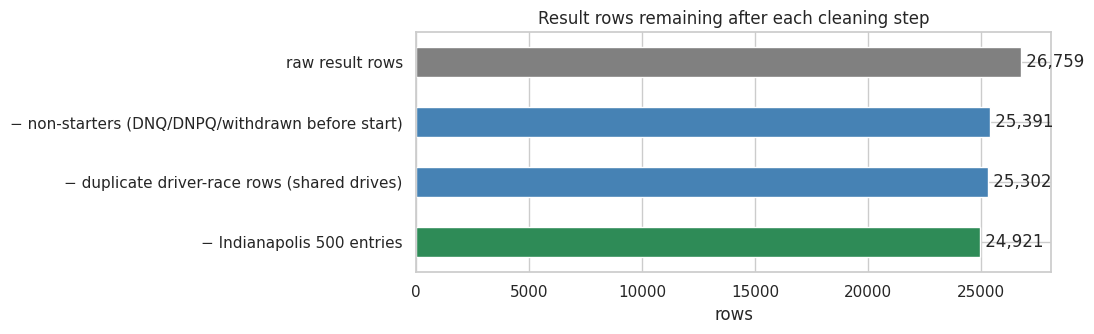

raw result rows                                     26759
− failed to qualify (positionText F)    25391
− duplicate driver-race rows (shared drives)        25302
− Indianapolis 500 entries                          24921
Rows removed in total: 1838 (6.9%)


In [25]:
flow = pd.Series({
    'raw result rows': len(raw['results']),
    '− failed to qualify (positionText F)': len(res) - int(res.non_starter.sum()),
    '− duplicate driver-race rows (shared drives)': len(starts_all),
    '− Indianapolis 500 entries': len(starts),
})
fig, ax = plt.subplots(figsize=(11, 3.5))
flow.plot.barh(ax=ax, color=['gray', 'steelblue', 'steelblue', 'seagreen'])
for i, v in enumerate(flow.values): ax.text(v, i, f' {v:,}', va='center')
ax.invert_yaxis(); ax.set_title('Result rows remaining after each cleaning step'); ax.set_xlabel('rows')
plt.tight_layout(); plt.show()
print(flow.to_string())
print('Rows removed in total:', flow.iloc[0] - flow.iloc[-1], f'({1 - flow.iloc[-1] / flow.iloc[0]:.1%})')


**What the output shows:** cleaning removed 1,838 of 26,759 result rows (**6.9%**): 1,368 failed-to-qualify rows, 89 duplicate driver–race rows (shared drives), and 381 Indianapolis 500 entries (405 minus the Indy rows already removed as duplicates). No row was removed for having a missing value.


### 3.2 Types and missing values: before vs after

**What:** compare (a) how many columns pandas could treat as numeric/date before vs after, and (b) the missing-value picture in `results`.

**Why:** typing should *change representation* without changing information. Before cleaning, missingness is hidden inside `\N` strings (invisible to `isna()`); after cleaning it is explicit NaN.

Column kinds across all 14 tables (original columns only):
             before (naive read)  after (clean)
date                           0              7
numeric                       64             73
text                          56             33
time of day                    0              7 



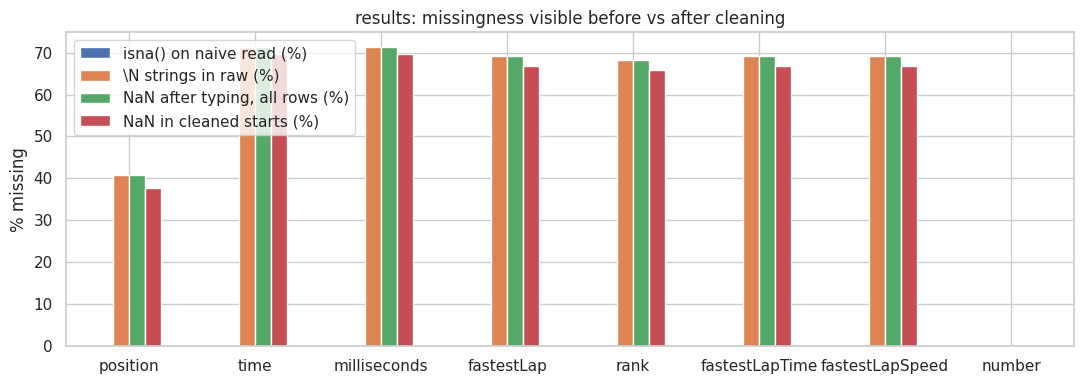

,isna() on naive read (%),\N strings in raw (%),"NaN after typing, all rows (%)",NaN in cleaned starts (%)
position,0.0,40.9,40.9,37.6
time,0.0,71.3,71.3,69.7
milliseconds,0.0,71.3,71.3,69.7
fastestLap,0.0,69.2,69.2,66.9
rank,0.0,68.2,68.2,65.9
fastestLapTime,0.0,69.2,69.2,66.9
fastestLapSpeed,0.0,69.2,69.2,66.9
number,0.0,0.0,0.0,0.0


In [26]:
def kind(dt):
    s = str(dt)
    if 'datetime' in s: return 'date'
    if 'timedelta' in s: return 'time of day'
    if s in ('Int64', 'int64', 'float64'): return 'numeric'
    return 'text'
kinds = pd.DataFrame({
    'before (naive read)': pd.concat([pd.read_csv(os.path.join(DATA_DIR, f'{t}.csv'), nrows=5000).dtypes for t in TABLES]).map(kind).value_counts(),
    'after (clean)': pd.concat([clean[t][raw[t].columns].dtypes for t in TABLES]).map(kind).value_counts()}).fillna(0).astype(int)
print('Column kinds across all 14 tables (original columns only):'); print(kinds, '\n')

cols = ['position', 'time', 'milliseconds', 'fastestLap', 'rank', 'fastestLapTime', 'fastestLapSpeed', 'number']
miss = pd.DataFrame({'isna() on naive read (%)': naive_results[cols].isna().mean() * 100,
                     '\\N strings in raw (%)': (raw['results'][cols] == '\\N').mean() * 100,
                     'NaN after typing, all rows (%)': res[cols].isna().mean() * 100,
                     'NaN in cleaned starts (%)': starts[cols].isna().mean() * 100}).round(1)
fig, ax = plt.subplots(figsize=(11, 4))
miss.plot.bar(ax=ax); ax.set_ylabel('% missing'); ax.set_title('results: missingness visible before vs after cleaning')
plt.xticks(rotation=0); plt.tight_layout(); plt.show()
miss


**What the output shows:** before cleaning, 56 of 120 original columns were text and no column was a date; after cleaning, only 33 genuine text columns remain (names, references, URLs, status codes), 73 are numeric, 7 are dates and 7 are clock times.

The bar chart shows the key point: on a naïve read, `isna()` reports **0%** missing for every column, while 41–71% of those values are actually `\N`. After cleaning, the NaN share equals the sentinel share exactly. In the cleaned starts table missingness is slightly lower (e.g. `position` 37.6% vs 40.9%), because the failed-to-qualify rows, which never have a position or time, were removed.


### 3.3 Grid, base rate and qualifying coverage: before vs after

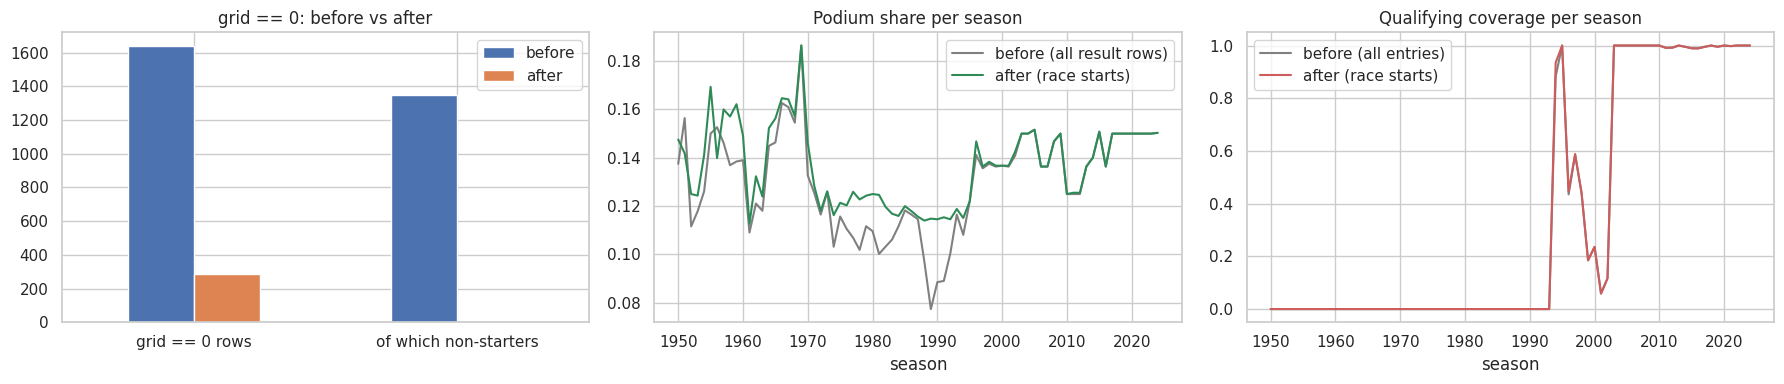

Seasons where cleaning raised the podium share the most: {1989: 0.037, 1991: 0.026, 1990: 0.026, 1981: 0.024, 1959: 0.024}
Overall podium share: before 0.1269 -> after 0.1341
Duplicated (raceId, driverId) pairs: before 91 -> after 0
Podiums per race after cleaning (should be 3; ties/shared drives can change it): {3: 1109, 2: 3, 5: 1, 4: 1}


In [27]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4))
# grid == 0 composition before vs after
gz = pd.DataFrame({'before': [int((res.grid == 0).sum()), int(((res.grid == 0) & res.non_starter).sum())],
                   'after':  [int((starts.grid == 0).sum()), 0]},
                  index=['grid == 0 rows', 'of which non-starters'])
gz.plot.bar(ax=axes[0], rot=0); axes[0].set_title('grid == 0: before vs after')
# podium base rate per season
before_rate = tmp.groupby('year').podium.mean()
after_rate = starts.groupby('year').podium.mean()
axes[1].plot(before_rate, label='before (all result rows)', color='gray')
axes[1].plot(after_rate, label='after (race starts)', color='seagreen')
axes[1].set_title('Podium share per season'); axes[1].legend(); axes[1].set_xlabel('season')
# qualifying coverage among starts
q_pairs_c = clean['qualifying'][['raceId', 'driverId']].assign(has_q=1)
cov_after = starts.merge(q_pairs_c, on=['raceId', 'driverId'], how='left').fillna({'has_q': 0}).groupby('year').has_q.mean()
axes[2].plot(q_cov, label='before (all entries)', color='gray')
axes[2].plot(cov_after, label='after (race starts)', color='indianred')
axes[2].set_title('Qualifying coverage per season'); axes[2].legend(); axes[2].set_xlabel('season')
plt.tight_layout(); plt.show()
diff = (after_rate - before_rate)
print('Seasons where cleaning raised the podium share the most:', {int(k): round(v, 3) for k, v in diff.sort_values(ascending=False).head(5).items()})
print('Overall podium share: before', round(tmp.podium.mean(), 4), '-> after', round(starts.podium.mean(), 4))
print('Duplicated (raceId, driverId) pairs: before', int(res.duplicated(['raceId', 'driverId']).sum()),
      '-> after', int(starts.duplicated(['raceId', 'driverId']).sum()))
print('Podiums per race after cleaning (should be 3; ties/shared drives can change it):',
      starts.groupby('raceId').podium.sum().value_counts().to_dict())


**What the output shows:**
* **grid = 0:** the failed-to-qualify zeros are gone; 290 remain (74 real pit-lane starts and 216 withdrawn/excluded/disqualified entries).
* **Base rate:** the overall podium share rises from **12.7% → 13.4%**, most in the seasons with many non-qualifiers (1989 +3.7 pp, 1990–91 +2.6 pp). The target base rate is now more stable across eras.
* **Qualifying coverage:** unchanged in shape (starts in 1994, complete from 2003).
* **Grain:** 91 → 0 duplicated pairs.
* **Podiums per race:** 1,109 races have exactly 3 podium rows. The 5 exceptions are early races with a tied/shared position or a shared-drive podium whose second car row was removed; this is a property of the historical records, not an error of cleaning.


---
## 4. Data-engineering questions

Each answer follows the same template: **tables & joins → grain → missingness → pre-race cutoff → answer → plot → interpretation**. All three use the cleaned `starts` table (one row per driver per race start, Indy 500 excluded, shared drives resolved).

**How we measure:** every answer is a simple **rate** = (number of times something happened) ÷ (number of chances), computed with `groupby`. A rate based on a handful of races is unreliable (one race more or less changes it a lot), so we always show the **sample size n** next to it and only rank groups that have a minimum number of cases.

In [28]:
circuits = clean['circuits'][['circuitId', 'name', 'country']].rename(columns={'name': 'circuit'})
quali_pos = clean['qualifying'][['raceId', 'driverId', 'position']].rename(columns={'position': 'quali_pos'})

### Q1. Which circuits convert a front-row start into a podium most often, and does the ranking change after the 2014 hybrid era?

**Tables & joins (multi-hop):** `results` (grid, positionOrder) → `races` (year, circuitId) → `circuits` (circuit name). For the qualifying-based definition, also `qualifying` (position), joined on `(raceId, driverId)`.

**Two definitions of "front-row start"** (the brief asks us to distinguish them):
* **Grid-based:** `results.grid ∈ {1, 2}`, the slot the car actually started from (after penalties).
* **Qualifying-based:** `qualifying.position ∈ {1, 2}`, where the driver qualified, before penalties.

**Grain:** one row per front-row *driver-race start*. The conversion rate of a circuit = podiums ÷ front-row starts.

**Window and missingness:** qualifying data only starts in 1994 (§1.6.3). To compare the two definitions on the **same races**, both are measured over **1994–2013 (pre-hybrid)** vs **2014–2024 (hybrid era and after)**. Qualifying coverage is partial in 1996–2002 (§1.6.3), so the qualifying-based pre-2014 sample is smaller. We show the sample size `n` instead of hiding it.

**Interpretation of "after the 2014 hybrid era":** we read it as *from 2014 onwards* (2014–2024, which includes the 2022+ ground-effect era). This is our reading of the question; a strict 2014–2021 window would be the alternative.

**Small-sample rule:** a circuit is ranked only if it has **≥ 10 front-row starts in each period** (≈ 5 races). With fewer, one race changes the rate by 10+ percentage points.

**How we answer "does the ranking change?":** rank the circuits by conversion rate in each period, then look at (a) how many places each circuit moved and (b) how many of the top-5 circuits before 2014 are still in the top 5 after.

**Cutoff:** grid and qualifying positions are both known before the race; the podium is the outcome. This is a descriptive question, so using the outcome is legitimate here.

In [29]:
q1 = starts[starts.year >= 1994].merge(quali_pos, on=['raceId', 'driverId'], how='left') \
                                 .merge(circuits, on='circuitId')
q1['period'] = np.where(q1.year >= 2014, '2014-2024', '1994-2013')
q1['front_grid'] = q1.grid.between(1, 2).fillna(False).astype(bool)
q1['front_quali'] = q1.quali_pos.between(1, 2).fillna(False).astype(bool)

def conversion(df, flag):
    # podium conversion rate per circuit and period = podiums / front-row starts
    t = df[df[flag]].groupby(['circuit', 'period']).agg(n=('podium', 'size'), podiums=('podium', 'sum')).reset_index()
    t['rate'] = t.podiums / t.n
    return t

MIN_N = 10
def wide(t):
    w = t.pivot(index='circuit', columns='period', values=['rate', 'n'])
    w.columns = [f'{a}_{b}' for a, b in w.columns]
    w = w[(w['n_1994-2013'] >= MIN_N) & (w['n_2014-2024'] >= MIN_N)].copy()
    w['rank_1994-2013'] = w['rate_1994-2013'].rank(ascending=False, method='min')
    w['rank_2014-2024'] = w['rate_2014-2024'].rank(ascending=False, method='min')
    w['places_moved'] = w['rank_1994-2013'] - w['rank_2014-2024']        # positive = moved up
    return w

wg, wq = wide(conversion(q1, 'front_grid')), wide(conversion(q1, 'front_quali'))

print('Overall front-row -> podium conversion (all circuits):')
for name, flag in [('grid-based', 'front_grid'), ('qualifying-based', 'front_quali')]:
    print(' ', name, q1[q1[flag]].groupby('period').podium.agg(['size', 'mean']).round(3).to_dict('index'))
print('\nFront-row starters by grid who did NOT qualify front row:', int((q1.front_grid & ~q1.front_quali & q1.quali_pos.notna()).sum()),
      '| front-row qualifiers who did NOT start front row:', int((q1.front_quali & ~q1.front_grid).sum()))
print(f'\nCircuits with >= {MIN_N} front-row starts in both periods: grid-based {len(wg)}, qualifying-based {len(wq)}')
for name, w in [('grid-based', wg), ('qualifying-based', wq)]:
    top_before = set(w.nsmallest(5, 'rank_1994-2013').index); top_after = set(w.nsmallest(5, 'rank_2014-2024').index)
    print(f'{name}: top-5 circuits still top-5 after 2014: {len(top_before & top_after)} of 5 {sorted(top_before & top_after)}'
          f' | average places moved: {w.places_moved.abs().mean():.1f}')
wg.sort_values('rate_2014-2024', ascending=False).round(3)

Overall front-row -> podium conversion (all circuits):
  grid-based {'1994-2013': {'size': 698, 'mean': 0.642}, '2014-2024': {'size': 454, 'mean': 0.76}}
  qualifying-based {'1994-2013': {'size': 532, 'mean': 0.647}, '2014-2024': {'size': 456, 'mean': 0.737}}

Front-row starters by grid who did NOT qualify front row: 36 | front-row qualifiers who did NOT start front row: 38

Circuits with >= 10 front-row starts in both periods: grid-based 15, qualifying-based 14
grid-based: top-5 circuits still top-5 after 2014: 2 of 5 ['Circuit de Barcelona-Catalunya', 'Suzuka Circuit'] | average places moved: 4.7
qualifying-based: top-5 circuits still top-5 after 2014: 1 of 5 ['Suzuka Circuit'] | average places moved: 4.8


,rate_1994-2013,rate_2014-2024,n_1994-2013,n_2014-2024,rank_1994-2013,rank_2014-2024,places_moved
circuit,,,,,,,
Suzuka Circuit,0.750,0.889,36.0,18.0,1.0,1.0,0.0
Yas Marina Circuit,0.600,0.864,10.0,22.0,10.0,2.0,8.0
Circuit de Monaco,0.650,0.850,40.0,20.0,4.0,3.0,1.0
Circuit de Barcelona-Catalunya,0.650,0.818,40.0,22.0,4.0,4.0,0.0
Circuit de Spa-Francorchamps,0.500,0.818,36.0,22.0,15.0,4.0,11.0
Autódromo José Carlos Pace,0.550,0.789,40.0,19.0,14.0,6.0,8.0
Shanghai International Circuit,0.650,0.786,20.0,14.0,4.0,7.0,-3.0
Circuit Gilles Villeneuve,0.579,0.778,38.0,18.0,12.0,8.0,4.0
Silverstone Circuit,0.625,0.750,40.0,24.0,9.0,9.0,0.0


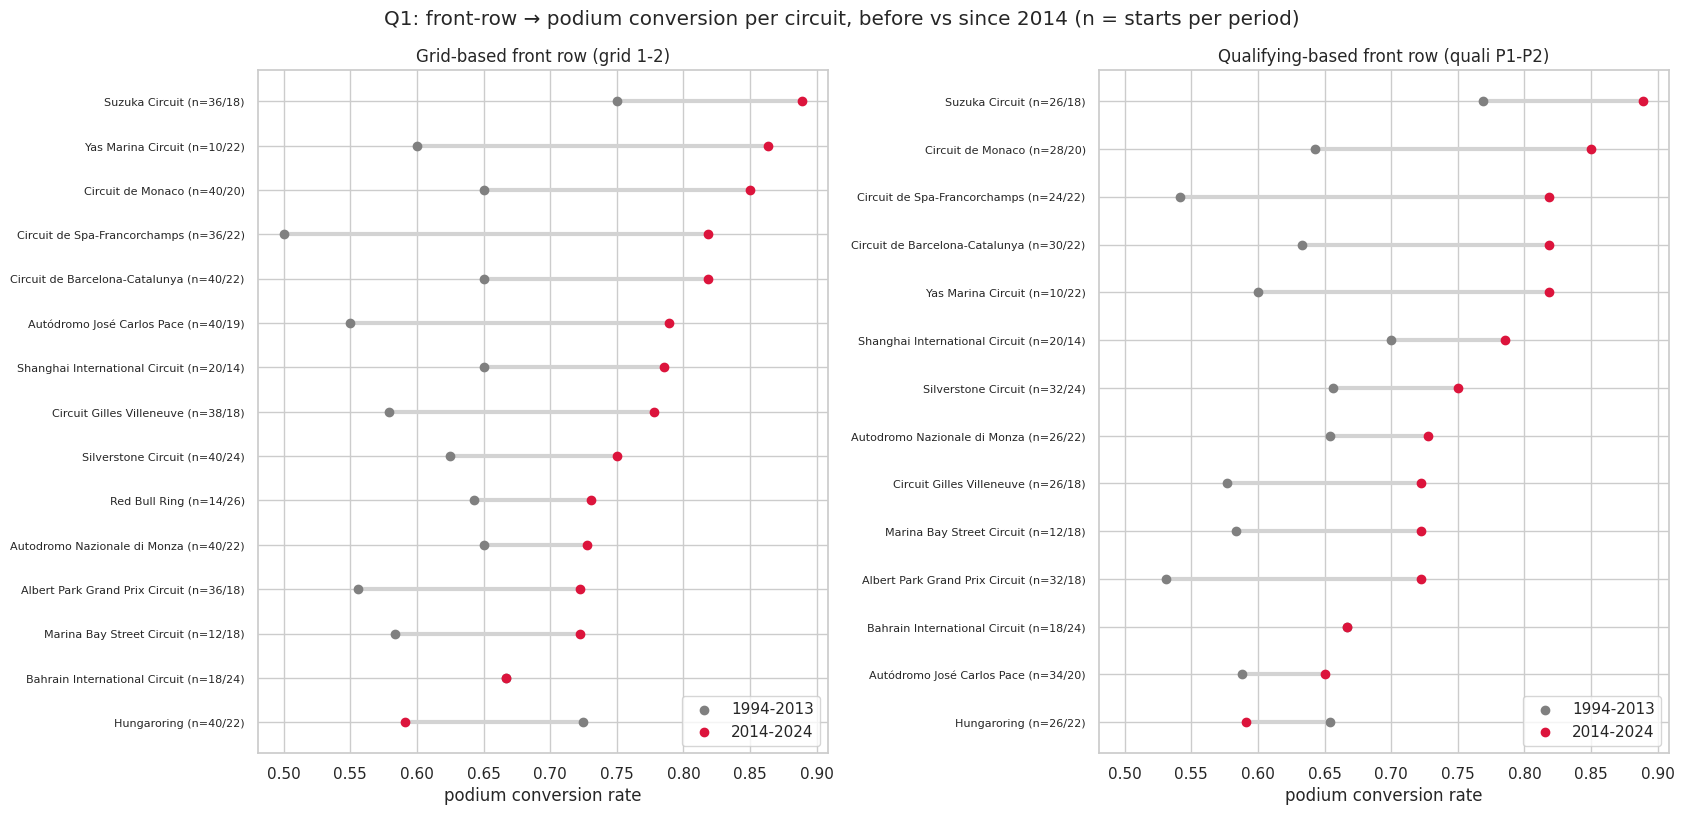

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(17, 0.42 * len(wg) + 2), sharex=True)
for ax, w, title in [(axes[0], wg, 'Grid-based front row (grid 1-2)'), (axes[1], wq, 'Qualifying-based front row (quali P1-P2)')]:
    w = w.sort_values('rate_2014-2024')
    y = np.arange(len(w))
    ax.hlines(y, w['rate_1994-2013'], w['rate_2014-2024'], color='lightgray', lw=3)
    ax.scatter(w['rate_1994-2013'], y, color='gray', label='1994-2013', zorder=3)
    ax.scatter(w['rate_2014-2024'], y, color='crimson', label='2014-2024', zorder=3)
    ax.set_yticks(y); ax.set_yticklabels([f'{c} (n={int(a)}/{int(b)})' for c, a, b in
                                          zip(w.index, w['n_1994-2013'], w['n_2014-2024'])], fontsize=8)
    ax.set_title(title); ax.set_xlabel('podium conversion rate'); ax.legend(loc='lower right')
plt.suptitle('Q1: front-row → podium conversion per circuit, before vs since 2014 (n = starts per period)')
plt.tight_layout(); plt.show()


**Answer.**
* **Overall,** a front-row start became a podium **64% of the time in 1994–2013 and 76% from 2014** (grid-based; 65% → 74% qualifying-based). Front-row starters converted more reliably in the hybrid era, consistent with fewer mechanical failures (Q3) and long periods of single-team dominance.
* **Top circuits since 2014 (grid-based, ≥ 10 front-row starts in each period):** Suzuka (89%), Yas Marina (86%), Monaco (85%), Barcelona and Spa (82%).
* **Does the ranking change? Yes, a lot.** Only 2 of the 5 best circuits before 2014 are still in the top 5 afterwards (Suzuka and Barcelona; only Suzuka with the qualifying-based definition), and circuits move 4.7 places on average. Examples: Hungaroring fell from 2nd to 15th (73% → 59%) and Bahrain from 3rd to 14th, while Spa rose from 15th to 4th (50% → 82%) and Yas Marina from 10th to 2nd.
* **Grid vs qualifying definition:** 36 grid-based front-row starters did not qualify there and 38 front-row qualifiers did not start there, so the two rankings are close but not identical.

**Caveat:** each circuit has only 10–40 front-row starts per period, so one race can move a rate by several percentage points. The robust findings are the overall rise in conversion and the large reshuffle of the ranking, not the exact position of any single circuit.


### Q2. Do drivers podium more often at a circuit in their home country, after controlling for starting position?

**Tables & joins (multi-hop):** `results` → `drivers` (nationality) and `results` → `races` → `circuits` (country).

**Matching nationality to country:** the two columns use different vocabularies ("British" vs "UK"), so we need an explicit, documented mapping (below). Design choices:
* dual nationalities in the data ("American-Italian", "Argentine-Italian") count as home in **either** country;
* *home* is decided by the **circuit's country**, not the race title. For example, the San Marino GP at Imola is a home race for Italians, and the European GP at the Nürburgring is a home race for Germans;
* "East German" is mapped to Germany (all German races in the data are in the same modern country label "Germany"). This is a judgement call, and it affects very few rows (printed below);
* nationalities with no circuit in their country (e.g. Finnish, Danish) simply never have a home race.

**Controlling for starting position:** the brief warns that home drivers might simply qualify better (or worse). So we do **not** compare all home starts with all away starts. Instead we split starts into **grid groups** (P1, P2, P3, P4–6, P7–10, P11–15, P16+/pit lane) and compare home vs away **inside each group**: a home driver starting P3 is compared only with away drivers starting P3. To summarise in one number we average the per-group differences, giving each group a weight equal to its number of home starts (groups with more home starts count more).

**Grain:** one row per driver race start. **Missingness:** nationality and circuit country have no missing values (checked below). **Cutoff:** home status and grid are known before the race.

In [31]:
NAT2COUNTRY = {
    'American': ['USA'], 'American-Italian': ['USA', 'Italy'], 'Argentine': ['Argentina'],
    'Argentine-Italian': ['Argentina', 'Italy'], 'Australian': ['Australia'], 'Austrian': ['Austria'],
    'Belgian': ['Belgium'], 'Brazilian': ['Brazil'], 'British': ['UK'], 'Canadian': ['Canada'],
    'Chinese': ['China'], 'Dutch': ['Netherlands'], 'East German': ['Germany'], 'French': ['France'],
    'German': ['Germany'], 'Hungarian': ['Hungary'], 'Indian': ['India'], 'Italian': ['Italy'],
    'Japanese': ['Japan'], 'Malaysian': ['Malaysia'], 'Mexican': ['Mexico'], 'Monegasque': ['Monaco'],
    'Portuguese': ['Portugal'], 'Russian': ['Russia'], 'South African': ['South Africa'],
    'Spanish': ['Spain'], 'Swedish': ['Sweden'], 'Swiss': ['Switzerland'],
}
nats = set(clean['drivers'].nationality); countries = set(clean['circuits'].country)
assert all(c in countries for v in NAT2COUNTRY.values() for c in v), 'mapping points to an unknown country'
print('Nationalities without any circuit in their country:', sorted(nats - set(NAT2COUNTRY)))
print('Circuit countries with no matching nationality   :', sorted(countries - {c for v in NAT2COUNTRY.values() for c in v}))

drivers = clean['drivers'][['driverId', 'nationality', 'forename', 'surname']]
def add_home(df):
    d = df.merge(drivers[['driverId', 'nationality']], on='driverId', how='left') \
          .merge(circuits[['circuitId', 'country']], on='circuitId', how='left')
    d['is_home'] = [int(c in NAT2COUNTRY.get(n, [])) for n, c in zip(d.nationality, d.country)]
    return d

q2 = add_home(starts)
print('Missing nationality:', int(q2.nationality.isna().sum()), '| missing country:', int(q2.country.isna().sum()))
print('Rows affected by the "East German" judgement call:', int((q2.nationality == 'East German').sum()))
bins = [-1, 1, 2, 3, 6, 10, 15, 99]; labels = ['P1', 'P2', 'P3', 'P4-6', 'P7-10', 'P11-15', 'P16+/pit']
q2['grid_bucket'] = pd.cut(q2.grid.replace(0, 99).astype(float), bins=bins, labels=labels)
print('Home starts:', int(q2.is_home.sum()), f'({q2.is_home.mean():.1%} of starts)')
print('Raw podium rate  home:', round(q2[q2.is_home == 1].podium.mean(), 4), '| away:', round(q2[q2.is_home == 0].podium.mean(), 4))
print('Mean grid slot   home:', round(q2[q2.is_home == 1].grid.replace(0, np.nan).astype(float).mean(), 2),
      '| away:', round(q2[q2.is_home == 0].grid.replace(0, np.nan).astype(float).mean(), 2))

Nationalities without any circuit in their country: ['Chilean', 'Colombian', 'Czech', 'Danish', 'Finnish', 'Indonesian', 'Irish', 'Liechtensteiner', 'New Zealander', 'Polish', 'Rhodesian', 'Thai', 'Uruguayan', 'Venezuelan']
Circuit countries with no matching nationality   : ['Azerbaijan', 'Bahrain', 'Korea', 'Morocco', 'Qatar', 'Saudi Arabia', 'Singapore', 'Turkey', 'UAE']
Missing nationality: 0 | missing country: 0
Rows affected by the "East German" judgement call: 5
Home starts: 1975 (7.9% of starts)
Raw podium rate  home: 0.1134 | away: 0.1359
Mean grid slot   home: 12.68 | away: 11.7


In [32]:
def home_vs_away_by_grid(d):
    # podium rate of home and away starts inside each grid group
    t = d.groupby(['grid_bucket', 'is_home'], observed=True).podium.agg(['size', 'mean']).unstack()
    t.columns = ['n_away', 'n_home', 'rate_away', 'rate_home']
    t['diff_pp'] = 100 * (t.rate_home - t.rate_away)          # percentage points, home minus away
    return t

def grid_adjusted_diff(t):
    # average of the per-group differences, weighted by the number of home starts in each group
    return (t.diff_pp * t.n_home).sum() / t.n_home.sum()

strata = home_vs_away_by_grid(q2)
summary_q2 = []
for label, d in [('1950-2024 (all starts)', q2), ('2003-2024 (modern era)', q2[q2.year >= 2003])]:
    t = home_vs_away_by_grid(d)
    summary_q2.append({'window': label, 'home starts': int(d.is_home.sum()),
                       'raw difference (pp)': round(100 * (d[d.is_home == 1].podium.mean() - d[d.is_home == 0].podium.mean()), 2),
                       'grid-adjusted difference (pp)': round(grid_adjusted_diff(t), 2),
                       'grid groups where home is higher': f"{int((t.diff_pp > 0).sum())} of {len(t)}"})
display(pd.DataFrame(summary_q2))
strata.round(3)

,window,home starts,raw difference (pp),grid-adjusted difference (pp),grid groups where home is higher
0,1950-2024 (all starts),1975,-2.25,-0.65,2 of 7
1,2003-2024 (modern era),365,-0.08,-2.14,2 of 7


,n_away,n_home,rate_away,rate_home,diff_pp
grid_bucket,,,,,
P1,1040,84,0.642,0.583,-5.897
P2,1034,77,0.561,0.545,-1.547
P3,1044,70,0.457,0.529,7.167
P4-6,3114,227,0.260,0.264,0.420
P7-10,4116,337,0.092,0.071,-2.086
P11-15,5124,415,0.029,0.024,-0.537
P16+/pit,7474,765,0.007,0.003,-0.448


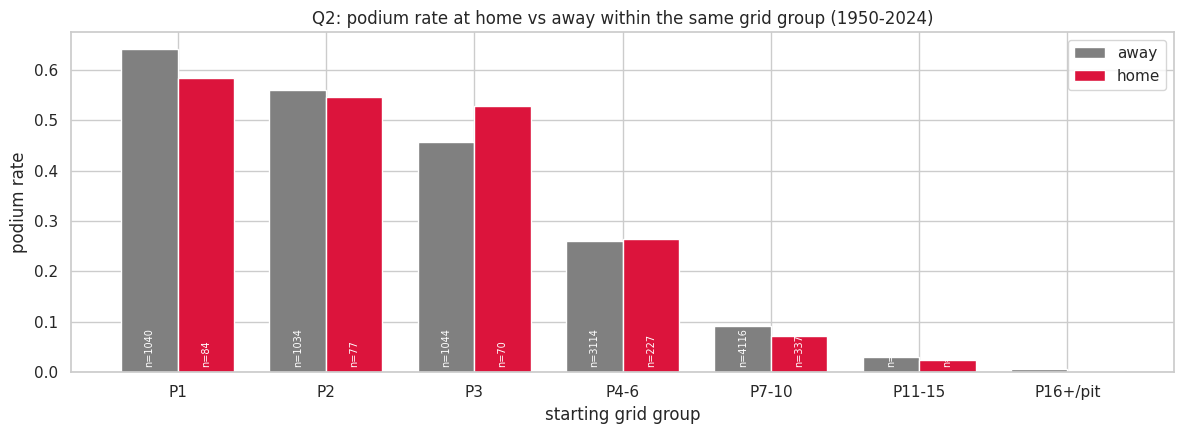

In [33]:
fig, ax = plt.subplots(figsize=(12, 4.5))
x = np.arange(len(strata)); w = 0.38
for off, side, col in [(-w/2, 'away', 'gray'), (w/2, 'home', 'crimson')]:
    ax.bar(x + off, strata[f'rate_{side}'], w, color=col, label=side)
    for xi, ni in zip(x + off, strata[f'n_{side}']): ax.text(xi, 0.01, f'n={int(ni)}', rotation=90, ha='center', va='bottom', fontsize=7, color='white')
ax.set_xticks(x); ax.set_xticklabels(strata.index); ax.set_xlabel('starting grid group')
ax.set_ylabel('podium rate'); ax.legend()
ax.set_title('Q2: podium rate at home vs away within the same grid group (1950-2024)')
plt.tight_layout(); plt.show()


**Answer: no sign of a home advantage once starting position is taken into account.**
* **Raw comparison:** home drivers podium *less* often (11.5% vs 13.7%), but they also start further back on average (grid 12.7 vs 11.7): many home entries are local drivers in uncompetitive cars. This is exactly the confounding the brief warns about.
* **Compared inside the same grid group:** the weighted difference is **−0.7 percentage points** for 1950–2024 and −2.1 pp for 2003–2024. Home drivers do better in only **2 of 7 grid groups**, and the per-group differences are small and switch direction (−5.9 pp for P1, +7.2 pp for P3, under ±2.1 pp elsewhere), which is what we expect from random variation with 70–735 home starts per group.

**Consequence for modeling:** home race is **not** used as a model feature (§5.2).


### Q3. Which constructors have the highest mechanical-retirement rate in 2014–2021 vs 2022–2024?

**Tables & joins (multi-hop):** `results` → `status` (status text → our taxonomy from §2.7), `results` → `constructors` (team name), `results` → `races` (year).

**Definition (from the brief):** a mechanical retirement is *a race start that ended early because a component of the car failed*, excluding crashes, driver-caused failures and regulation decisions.
* **Numerator:** starts whose status class is `mechanical`.
* **Denominator:** **race starts** of that constructor in the period. Non-starters are already removed (§2.5), because a car that never started cannot retire.
* **Sensitivity version:** numerator = `mechanical` + `ambiguous` (§2.7), to check that the ranking is not an artefact of the ambiguous statuses. We compare the top-3 constructors of both versions.

**Grain:** one row per car start (driver–race). Each constructor normally has 2 per race.

**Missingness:** every status is mapped (§2.7 asserts it). **Cutoff:** this is a descriptive, post-race question, so status can be used here. It is never a feature for the current race.

**Constructor identity:** names come from `constructorId`. Re-branded teams (e.g. Racing Point → Aston Martin, Toro Rosso → AlphaTauri → RB, Renault → Alpine) are *different IDs* in the data, so they appear as separate rows. We report them as the data records them and do not merge them, which would be an extra assumption.

In [34]:
cons = clean['constructors'][['constructorId', 'name']].rename(columns={'name': 'constructor'})
q3 = starts[starts.year.between(2014, 2024)].merge(cons, on='constructorId')
q3['period'] = np.where(q3.year <= 2021, '2014-2021', '2022-2024')
q3['mech'] = (q3.status_class == 'mechanical').astype(int)
q3['mech_or_amb'] = q3.status_class.isin(['mechanical', 'ambiguous']).astype(int)

t3 = q3.groupby(['period', 'constructor']).agg(starts=('mech', 'size'), mech_dnf=('mech', 'sum'),
                                               mech_or_amb=('mech_or_amb', 'sum')).reset_index()
t3['mech_rate'] = t3.mech_dnf / t3.starts
t3['sens_rate'] = t3.mech_or_amb / t3.starts
MIN_STARTS = 20
t3 = t3[t3.starts >= MIN_STARTS].copy()
t3['rank'] = t3.groupby('period').mech_rate.rank(ascending=False, method='min')
t3['rank_sensitivity'] = t3.groupby('period').sens_rate.rank(ascending=False, method='min')
print('Field mechanical-retirement rate per period:', q3.groupby('period').mech.mean().round(4).to_dict())
for p in ['2014-2021', '2022-2024']:
    d = t3[t3.period == p]
    print(f"{p}: top-3 (mechanical only): {list(d.nsmallest(3, 'rank').constructor)} | "
          f"top-3 (incl. ambiguous): {list(d.nsmallest(3, 'rank_sensitivity').constructor)}")
t3.sort_values(['period', 'mech_rate'], ascending=[True, False]).round(3)

Field mechanical-retirement rate per period: {'2014-2021': 0.0915, '2022-2024': 0.0567}
2014-2021: top-3 (mechanical only): ['Caterham', 'Lotus F1', 'Toro Rosso'] | top-3 (incl. ambiguous): ['Caterham', 'Lotus F1', 'Toro Rosso']
2022-2024: top-3 (mechanical only): ['Alfa Romeo', 'Alpine F1 Team', 'AlphaTauri'] | top-3 (incl. ambiguous): ['Alfa Romeo', 'Alpine F1 Team', 'RB F1 Team']


,period,constructor,starts,mech_dnf,mech_or_amb,mech_rate,sens_rate,rank,rank_sensitivity
4,2014-2021,Caterham,34,8,11,0.235,0.324,1.0,1.0
8,2014-2021,Lotus F1,76,13,19,0.171,0.250,2.0,2.0
17,2014-2021,Toro Rosso,242,39,44,0.161,0.182,3.0,3.0
11,2014-2021,McLaren,320,44,53,0.138,0.166,4.0,4.0
15,2014-2021,Renault,200,27,32,0.135,0.160,5.0,5.0
16,2014-2021,Sauber,200,22,27,0.110,0.135,6.0,6.0
14,2014-2021,Red Bull,320,34,39,0.106,0.122,7.0,8.0
1,2014-2021,AlphaTauri,78,8,9,0.103,0.115,8.0,9.0
10,2014-2021,Marussia,31,3,3,0.097,0.097,9.0,12.0
13,2014-2021,Racing Point,76,7,8,0.092,0.105,10.0,10.0


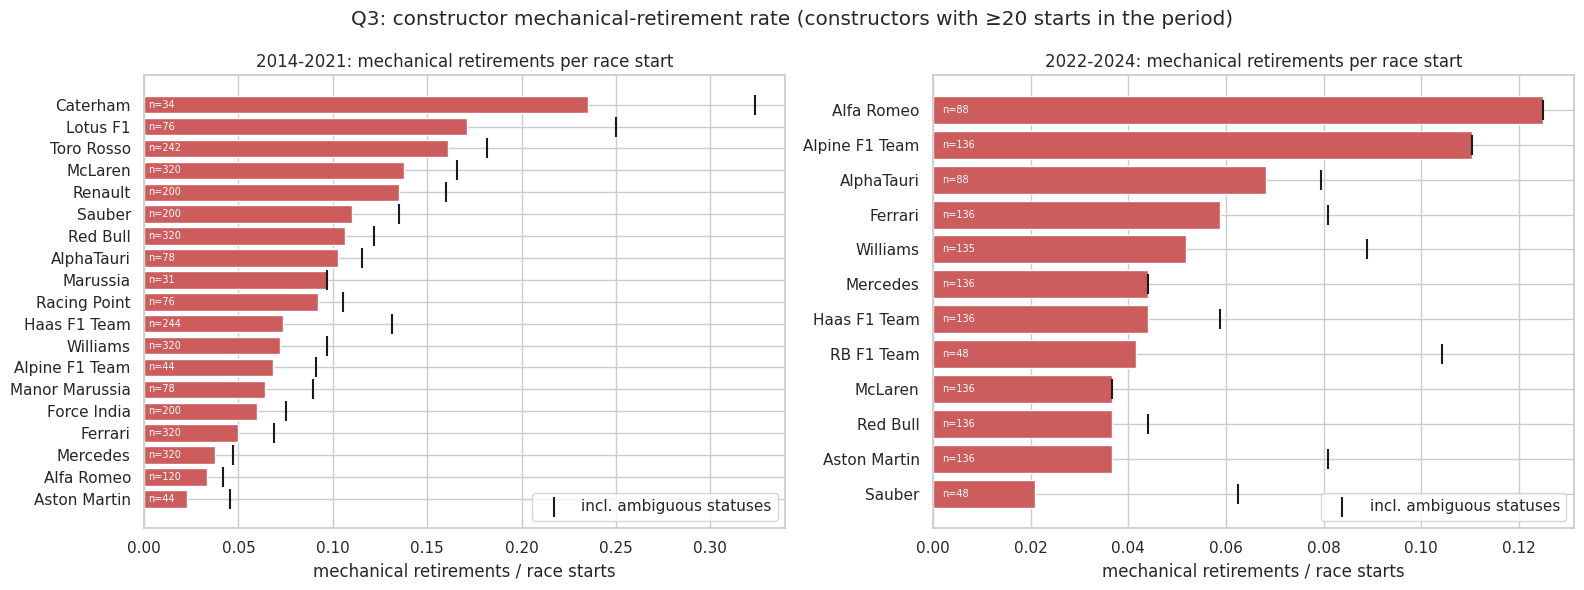

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, p in zip(axes, ['2014-2021', '2022-2024']):
    d = t3[t3.period == p].sort_values('mech_rate')
    ax.barh(d.constructor, d.mech_rate, color='indianred')
    ax.scatter(d.sens_rate, d.constructor, marker='|', s=200, color='k', label='incl. ambiguous statuses', zorder=3)
    for yi, (r, n) in enumerate(zip(d.mech_rate, d.starts)): ax.text(0.002, yi, f'n={n}', va='center', fontsize=7, color='white')
    ax.set_title(f'{p}: mechanical retirements per race start'); ax.set_xlabel('mechanical retirements / race starts'); ax.legend(loc='lower right')
plt.suptitle(f'Q3: constructor mechanical-retirement rate (constructors with ≥{MIN_STARTS} starts in the period)')
plt.tight_layout(); plt.show()


**Answer (strict `mechanical` definition, constructors with ≥ 20 starts).**
* **2014–2021:** highest rates for **Caterham (23.5%)**, **Lotus F1 (17.1%)** and **Toro Rosso (16.1%)**, then McLaren (13.8%) and Renault (13.5%). Lowest: Aston Martin, Alfa Romeo and Mercedes (2–4%).
* **2022–2024:** highest for **Alfa Romeo (12.5%)** and **Alpine (11.0%)**, then AlphaTauri (6.8%). Red Bull, McLaren and Aston Martin are around 3.7%.
* **Change:** the field-wide rate fell from **9.1% to 5.6%**. Several leaders of the first period no longer exist (Caterham, Lotus F1) or were renamed, so the ranking cannot be compared team by team.

**Sensitivity (adding the ambiguous statuses):** the top 3 of 2014–2021 is identical. In 2022–2024 the top 2 stay the same, but third place changes from AlphaTauri to RB F1 Team, whose rate jumps from 4.2% to 10.4% because of 3 ambiguous retirements in only 48 starts. Teams with few starts move easily, which is why the minimum of 20 starts is applied and why only the clear leaders should be read as robust.


---
## 5. Leakage-safe feature engineering

### 5.1 Which columns are allowed at the prediction cutoff?

The guide's timeline: *practice → qualifying → **starting grid** ┆ prediction cutoff ┆ race → results*. For **every** candidate column we ask: *"Would this be known after qualifying but before the race?"* The table below is the audit. Anything marked ✗ is never used as a feature **for the same race**. Some ✗ columns are still used **from past races** to build history features, which is legitimate because past races are finished before the current one starts.

In [36]:
cutoff_audit = pd.DataFrame([
    ('results', 'grid', '✓', 'starting slot after penalties; fixed before lights out'),
    ('qualifying', 'position, q1/q2/q3', '✓ (not used, see below)', 'qualifying finishes before the race'),
    ('races', 'year, round, circuitId, date', '✓', 'calendar known in advance'),
    ('drivers / circuits', 'nationality, country', '✓', 'static attributes'),
    ('driver/constructor_standings', 'points, position, wins of the CURRENT race', '✗', 'standings rows are written AFTER the race they belong to'),
    ('driver/constructor_standings', '... of the PREVIOUS round', '✓', '"standings before this race"'),
    ('results', 'positionOrder, position, positionText, points', '✗ (target source)', 'race outcome'),
    ('results', 'laps, time, milliseconds, statusId', '✗', 'only known when the race ends'),
    ('results', 'fastestLap, rank, fastestLapTime, fastestLapSpeed', '✗', 'measured during the race'),
    ('lap_times, pit_stops', 'all columns', '✗', 'produced during the race'),
    ('constructor_results', 'points, status', '✗', 'race outcome per team'),
    ('results/status of PAST races', 'podium, finish, DNF, mechanical DNF', '✓ (history only)', 'shifted so the current race is excluded'),
    ('sprint_results', 'same-weekend sprint result', '✓ in principle / not used', 'see decision below'),
], columns=['table', 'column(s)', 'allowed at cutoff?', 'reason'])
cutoff_audit

,table,column(s),allowed at cutoff?,reason
0,results,grid,✓,starting slot after penalties; fixed before li...
1,qualifying,"position, q1/q2/q3","✓ (not used, see below)",qualifying finishes before the race
2,races,"year, round, circuitId, date",✓,calendar known in advance
3,drivers / circuits,"nationality, country",✓,static attributes
4,driver/constructor_standings,"points, position, wins of the CURRENT race",✗,standings rows are written AFTER the race they...
5,driver/constructor_standings,... of the PREVIOUS round,✓,"""standings before this race"""
6,results,"positionOrder, position, positionText, points",✗ (target source),race outcome
7,results,"laps, time, milliseconds, statusId",✗,only known when the race ends
8,results,"fastestLap, rank, fastestLapTime, fastestLapSpeed",✗,measured during the race
9,"lap_times, pit_stops",all columns,✗,produced during the race


**Decision on sprints.** A sprint runs before the Sunday race, so its result is technically pre-race information (the guide calls it "a leakage judgement call"). We **do not** use it. (1) Sprints exist only from 2021, so there are none in the training years (≤ 2019, §6): the model could never learn a weight for them. (2) In 2021–2022 the sprint *result* set the Sunday grid, so that information already reaches the model through `grid`.

### 5.2 Feature groups and why each might predict a podium

| Group | Features | Hypothesis (why it should help) | Source |
|---|---|---|---|
| **grid** | `grid_pos`, `pitlane_start` | the guide: grid / pole is the strongest single predictor; starting at the front means fewer cars to pass. `grid = 0` (pit-lane start, or no grid slot for a withdrawn/excluded entry) becomes **field size + 1**, i.e. behind the last car on the grid, and `pitlane_start = 1` marks these rows | results (current race, pre-race) |
| **standings** | `drv_pts_share_before`, `drv_rank_before`, `drv_wins_before`, and the same three for the constructor | season-to-date strength; points share is used instead of raw points because the points system changed many times since 1950 | standings of the previous round |
| **driver_form** | `drv_podium_rate_last5`, `drv_finish_pct_last5`, `drv_dnf_rate_last5`, `drv_career_starts`, `drv_career_podium_rate` | recent and long-run driver performance / experience | past races only |
| **constructor_form** | `con_podiums_per_race_last5`, `con_best_finish_pct_last5`, `con_mech_dnf_rate_last10` | the guide: *car performance is the dominant factor*; reliability (from the Q3 taxonomy) limits conversion | past races only |
| **context** | `field_size` | more starters → harder to podium | race entry list |

**Why there is no home-race feature.** Q2 (§4) found no home advantage once the starting position is taken into account, so `is_home` is not used.

**Why there is no qualifying group.** Qualifying is allowed at the cutoff (table above), but `qualifying.csv` only starts in 1994 and is incomplete until 2003 (§1.6.3), while the model is trained from **1950** (§7.1). Qualifying features would be missing for most training rows. The starting grid exists for every season and §7.1 shows that it carries almost the same information as the qualifying position, so `grid` represents "how fast was the car this weekend".

**Constructor standings before 1958.** The constructors' championship only started in 1958 (`constructor_standings` has no earlier rows). For 1950–1957 the three constructor-standings features are therefore set to **missing**, not 0: 0 would wrongly claim "this team had scored nothing". The imputer and its missing-indicator handle them (§8).

**`finish_pct`** = positionOrder ÷ field size. A normalised finishing position makes a 10th place in a 20-car field comparable with a 10th place in a 35-car field.

### 5.3 The feature builder

**How leakage is prevented in the code:**
* **History features** use `groupby(driverId or constructorId)` on races **sorted by date**, then `.shift(1)` **before** `.rolling()`/`.expanding()`. `shift(1)` moves every value one race later, so the window that ends at race *t* only contains races *< t*.
* **Standings before the race** use `merge_asof(..., allow_exact_matches=False)` on the round number within each season. It picks the latest standings row from a **strictly earlier** round. The first race of a season has no earlier round, so points/wins = 0 (factually true) and the rank is left missing.
* **Constructor form** first aggregates to one row per (constructor, race), so both cars' results count once per race, then shifts at that level. This way a teammate's result *in the current race* can never leak into the other car's feature.

In [37]:
FEATURE_GROUPS = {
    'grid': ['grid_pos', 'pitlane_start'],
    'standings': ['drv_pts_share_before', 'drv_rank_before', 'drv_wins_before',
                  'con_pts_share_before', 'con_rank_before', 'con_wins_before'],
    'driver_form': ['drv_podium_rate_last5', 'drv_finish_pct_last5', 'drv_dnf_rate_last5',
                    'drv_career_starts', 'drv_career_podium_rate'],
    'constructor_form': ['con_podiums_per_race_last5', 'con_best_finish_pct_last5', 'con_mech_dnf_rate_last10'],
    'context': ['field_size'],
}
FEATURES = [f for g in FEATURE_GROUPS.values() for f in g]

def build_features(starts_df, races_df, dstand, cstand):
    # Return one row per (raceId, driverId) with pre-race features + target. Inputs are cleaned tables.
    df = starts_df[['raceId', 'driverId', 'constructorId', 'circuitId', 'year', 'round', 'date',
                    'grid', 'positionOrder', 'status_class', 'podium']].copy()
    # --- grid / context (current race, known after the grid is set) ---
    df['field_size'] = df.groupby('raceId').driverId.transform('size')
    df['pitlane_start'] = (df.grid == 0).astype(int)
    df['grid_pos'] = np.where(df.grid == 0, df.field_size + 1, df.grid).astype(float)   # grid 0 -> behind the last grid slot
    # --- standings BEFORE this race: latest strictly-earlier round of the same season ---
    rr = races_df[['raceId', 'year', 'round']]
    for tab, key, p in [(dstand, 'driverId', 'drv'), (cstand, 'constructorId', 'con')]:
        s = tab.merge(rr, on='raceId')[['year', 'round', key, 'points', 'position', 'wins']].copy()
        s['pts_share'] = s.points / s.groupby(['year', 'round']).points.transform('max').replace(0, np.nan)
        s = s.rename(columns={'position': f'{p}_rank_before', 'wins': f'{p}_wins_before',
                              'pts_share': f'{p}_pts_share_before'}).drop(columns='points')
        s[['year', 'round', key]] = s[['year', 'round', key]].astype('int64')
        df[['year', 'round', key]] = df[['year', 'round', key]].astype('int64')
        df = pd.merge_asof(df.sort_values('round'), s.sort_values('round'), on='round', by=['year', key],
                           allow_exact_matches=False, direction='backward')
        # no earlier standings row this season -> nothing scored yet (0), rank unknown (NaN)
        df[[f'{p}_pts_share_before', f'{p}_wins_before']] = df[[f'{p}_pts_share_before', f'{p}_wins_before']].fillna(0)
    # no constructors' championship before its first season (1958) -> constructor standings are unknown, not 0
    first_con_year = cstand.merge(rr, on='raceId').year.min()
    df.loc[df.year < first_con_year, ['con_pts_share_before', 'con_rank_before', 'con_wins_before']] = np.nan
    df = df.sort_values(['date', 'raceId', 'driverId']).reset_index(drop=True)
    # --- driver form: past races only (shift(1) BEFORE rolling) ---
    df['_finish_pct'] = df.positionOrder.astype(float) / df.field_size
    df['_dnf'] = (df.status_class != 'finished').astype(int)
    g = df.groupby('driverId')
    past_mean = lambda col, w: g[col].transform(lambda s: s.shift(1).rolling(w, min_periods=1).mean())
    df['drv_podium_rate_last5'] = past_mean('podium', 5)
    df['drv_finish_pct_last5'] = past_mean('_finish_pct', 5)
    df['drv_dnf_rate_last5'] = past_mean('_dnf', 5)
    df['drv_career_starts'] = g.cumcount()                       # number of EARLIER starts
    df['drv_career_podium_rate'] = g.podium.transform(lambda s: s.shift(1).expanding().mean())
    # --- constructor form: aggregate per (constructor, race) first, then shift ---
    df['_mech'] = (df.status_class == 'mechanical').astype(int)
    cr = df.groupby(['constructorId', 'raceId', 'date'], as_index=False).agg(
        pod=('podium', 'sum'), best=('_finish_pct', 'min'), mech=('_mech', 'sum'), cars=('driverId', 'size'))
    cr = cr.sort_values(['date', 'raceId'])
    gc = cr.groupby('constructorId')
    cr['con_podiums_per_race_last5'] = gc.pod.transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
    cr['con_best_finish_pct_last5'] = gc.best.transform(lambda s: s.shift(1).rolling(5, min_periods=1).mean())
    cr['con_mech_dnf_rate_last10'] = gc.mech.transform(lambda s: s.shift(1).rolling(10, min_periods=1).sum()) / \
                                     gc.cars.transform(lambda s: s.shift(1).rolling(10, min_periods=1).sum())
    df = df.merge(cr[['constructorId', 'raceId', 'con_podiums_per_race_last5', 'con_best_finish_pct_last5',
                      'con_mech_dnf_rate_last10']], on=['constructorId', 'raceId'], how='left')
    keep = ['raceId', 'driverId', 'constructorId', 'year', 'round', 'date'] + FEATURES + ['podium']
    return df[keep].sort_values(['date', 'raceId', 'driverId']).reset_index(drop=True)

races_c = clean['races']
feat_all = build_features(starts, races_c, clean['driver_standings'], clean['constructor_standings'])
assert not feat_all.duplicated(['raceId', 'driverId']).any() and len(feat_all) == len(starts)
print('Feature table (all seasons):', feat_all.shape, '| unique (raceId, driverId):', not feat_all.duplicated(['raceId', 'driverId']).any())
feat_all[feat_all.year == 2024].head(3).T

Feature table (all seasons): (24921, 24) | unique (raceId, driverId): True


,24442,24443,24444
raceId,1121,1121,1121
driverId,1,4,807
constructorId,131,117,210
year,2024,2024,2024
round,1,1,1
date,2024-03-02 00:00:00,2024-03-02 00:00:00,2024-03-02 00:00:00
grid_pos,9.0,6.0,10.0
pitlane_start,0,0,0
drv_pts_share_before,0.0,0.0,0.0
drv_rank_before,<NA>,<NA>,<NA>



**What the output shows:** 24,921 rows × 24 columns (all seasons 1950–2024), still one row per `(raceId, driverId)`; 17 of the columns are features. The example rows are the first race of 2024: points share and wins before the race are 0 and the ranks are missing (no earlier round that season), while driver and constructor form already carry information from 2023 because form features cross season boundaries. The career podium rate of 0.59 for driverId 1 shows history accumulating across his whole career.


### 5.4 Automated leakage tests

"The code *looks* leakage-safe" is not evidence. We run tests that **fail if leakage exists**.

**Test 1: perturbation (the main test).** Pick a race *R*. Make a copy of the data in which **everything that happens at race R or later** is scrambled: finishing orders shuffled, statuses randomised, standings points randomised. Qualifying for *R* is kept, because it is legitimately known. Rebuild all features. If any feature of race *R* changes, that feature was using information from *R* or the future. We run this on races in the validation and test seasons.

**Test 2: negative control.** A test that never fails proves nothing. So we add a **deliberately leaky** feature (the driver's podium rate *including* the current race, i.e. without `shift(1)`) and check that Test 1 **catches it**.

**Test 3: standings are from the previous round.** For random rows, `drv_pts_share_before` must equal the share computed from the standings of the **previous** round, not from the current race's standings row.

**Test 4: driver form = manual recomputation.** For random rows, recompute `drv_podium_rate_last5` and `drv_career_starts` by hand from strictly earlier races and compare.

In [38]:
def scramble_from(race_id, seed=0):
    # Copies of the inputs where all post-race information of race_id and every later race is randomised.
    rng = np.random.default_rng(seed)
    cut = races_c.loc[races_c.raceId == race_id, 'date'].iloc[0]
    later = set(races_c.loc[races_c.date >= cut, 'raceId'])
    s2 = starts.copy(); m = s2.raceId.isin(later)
    s2.loc[m, 'positionOrder'] = s2.loc[m].groupby('raceId').positionOrder.transform(lambda x: rng.permutation(x.values))
    s2['podium'] = (s2.positionOrder <= 3).astype(int)
    s2.loc[m, 'status_class'] = rng.choice(['finished', 'mechanical', 'accident_driver'], m.sum())
    ds2 = clean['driver_standings'].copy(); md = ds2.raceId.isin(later)
    ds2.loc[md, 'points'] = rng.integers(0, 500, md.sum()).astype(float)
    ds2.loc[md, 'position'] = rng.integers(1, 30, md.sum()); ds2.loc[md, 'wins'] = rng.integers(0, 20, md.sum())
    cs2 = clean['constructor_standings'].copy(); mc = cs2.raceId.isin(later)
    cs2.loc[mc, 'points'] = rng.integers(0, 900, mc.sum()).astype(float)
    cs2.loc[mc, 'position'] = rng.integers(1, 12, mc.sum()); cs2.loc[mc, 'wins'] = rng.integers(0, 20, mc.sum())
    return s2, ds2, cs2

def leaky_extra(df):
    # NEGATIVE CONTROL: podium rate over the last 5 races INCLUDING the current one (no shift) - deliberately wrong
    df = df.sort_values(['date', 'raceId', 'driverId']).copy()
    df['LEAKY_podium_rate_incl_current'] = df.groupby('driverId').podium.transform(lambda s: s.rolling(5, min_periods=1).mean())
    return df

test_races = [int(r) for r in feat_all.loc[feat_all.year.isin([2021, 2023, 2024]), 'raceId'].drop_duplicates().sample(3, random_state=SEED)]
report = []
for rid in test_races:
    s2, ds2, cs2 = scramble_from(rid, seed=rid)
    f2 = build_features(s2, races_c, ds2, cs2)
    a = feat_all[feat_all.raceId == rid].set_index('driverId').sort_index()
    b = f2[f2.raceId == rid].set_index('driverId').sort_index()
    changed = [c for c in FEATURES if not np.allclose(a[c].astype(float), b[c].astype(float), equal_nan=True)]
    leak_a, leak_b = leaky_extra(feat_all), leaky_extra(f2)
    la = leak_a[leak_a.raceId == rid].set_index('driverId').sort_index()['LEAKY_podium_rate_incl_current']
    lb = leak_b[leak_b.raceId == rid].set_index('driverId').sort_index()['LEAKY_podium_rate_incl_current']
    report.append({'raceId': rid, 'season': int(a.year.iloc[0]),
                   'target rows changed by scrambling': int((a.podium != b.podium).sum()),
                   'real features changed': len(changed), 'changed list': changed,
                   'negative control caught?': bool(not np.allclose(la, lb))})
leak_report = pd.DataFrame(report)
assert (leak_report['real features changed'] == 0).all(), 'LEAKAGE: a feature depends on the current/future race'
assert leak_report['negative control caught?'].all(), 'the test failed to detect a known leak'
leak_report

,raceId,season,target rows changed by scrambling,real features changed,changed list,negative control caught?
0,1123,2024,4,0,[],True
1,1069,2021,6,0,[],True
2,1056,2021,6,0,[],True


In [39]:
# Test 3: standings come from the previous round, not the current race
rr = races_c[['raceId', 'year', 'round']]
ds = clean['driver_standings'].merge(rr, on='raceId')
ds['share'] = ds.points / ds.groupby(['year', 'round']).points.transform('max')
ds[['year', 'round', 'driverId', 'raceId']] = ds[['year', 'round', 'driverId', 'raceId']].astype('int64')
sample = feat_all[(feat_all.year >= 2003) & (feat_all['round'] > 1)].sample(300, random_state=SEED)
prev = sample[['year', 'round', 'driverId']].assign(round=sample['round'] - 1) \
         .merge(ds[['year', 'round', 'driverId', 'share']], on=['year', 'round', 'driverId'], how='left')
cur = sample[['raceId', 'driverId']].astype('int64').merge(ds[['raceId', 'driverId', 'share']], on=['raceId', 'driverId'], how='left')
has_prev = prev.share.notna().values
match_prev = np.isclose(sample.drv_pts_share_before.values[has_prev].astype(float), prev.share.values[has_prev].astype(float))
match_cur = np.isclose(sample.drv_pts_share_before.values.astype(float), cur.share.values.astype(float))
print(f'Test 3: rows whose previous round exists: {has_prev.sum()} | equal to PREVIOUS-round share: {match_prev.mean():.1%}'
      f' | equal to CURRENT-race share: {np.nanmean(match_cur):.1%}')
assert match_prev.all()
print('        first round of each season -> pts share before =',
      feat_all.loc[feat_all['round'] == 1, 'drv_pts_share_before'].unique())

# Test 4: manual recomputation of driver form for random rows
def manual_form(row):
    past = feat_all[(feat_all.driverId == row.driverId) & (feat_all.date < row.date)].sort_values('date')
    return len(past), (past.podium.tail(5).mean() if len(past) else np.nan)
rows = feat_all[feat_all.year >= 2003].sample(200, random_state=SEED)
manual = np.array([manual_form(r) for r in rows.itertuples()], dtype=float)
ok_starts = (manual[:, 0] == rows.drv_career_starts.values).all()
ok_rate = np.allclose(manual[:, 1], rows.drv_podium_rate_last5.values.astype(float), equal_nan=True)
print(f'Test 4: career starts match: {ok_starts} | podium rate last 5 matches: {ok_rate} (200 random rows)')
assert ok_starts and ok_rate
print('\nAll leakage tests passed.')

Test 3: rows whose previous round exists: 293 | equal to PREVIOUS-round share: 100.0% | equal to CURRENT-race share: 26.7%
        first round of each season -> pts share before = [0.]


Test 4: career starts match: True | podium rate last 5 matches: True (200 random rows)

All leakage tests passed.



**What the output shows:**
* **Test 1 (perturbation):** for three races (2024, 2021, 2021), scrambling everything from that race onwards changed 4–6 target labels, but **0 of the 17 features** of that race changed.
* **Test 2 (negative control):** the deliberately leaky feature **was caught** in all three races, so the test is able to detect leakage.
* **Test 3:** `drv_pts_share_before` equals the **previous** round's share in 100% of 293 testable rows, and the current race's share in only 27% (the coincidental cases where a driver scored no points in that race). Round-1 rows are 0.
* **Test 4:** hand-recomputed career starts and last-5 podium rate match for all 200 random rows.

**Conclusion:** the features use only information available before the race.


---
## 6. Train / validation / test split

### 6.1 Why a temporal split, not a random one

The lab manuals use `train_test_split(..., random_state=42)`, a **random** split, and Lab 3 uses `validation_split=0.3`. That is fine for diamonds or Titanic passengers, which are independent rows. It is **not** appropriate here:

1. **The task is forecasting.** We will always predict a *future* race from the past. A random split would train on 2023 and test on 2010, which flatters the model with knowledge of later eras.
2. **Rows inside a race are dependent.** Exactly three of them are podiums. A random split would put some drivers of a race in training and the rest in testing, so the model would partly "see" a race it is tested on.
3. **Era drift.** Rules, reliability and team dominance change by era (guide §Eras; Q1 and Q3 above). A temporal test set measures exactly what we care about: does the model still work in an era it has not seen?

**Decision:** whole seasons, as recommended in the course guide: **train ≤ 2019 · validation 2020–2021 · test 2022–2024**. The test set (2022–2024) is also a new technical era (ground-effect cars), so it is a demanding, honest test. It is touched **once**, at the end of §9.

**Where is the test set used?** Never for choosing the training window, features, preprocessing order, hyperparameters, thresholds or models. All of those use **train → validation** only. Lab 3's `validation_split` is replaced by our explicit 2020–2021 validation seasons for the same reason (a random 30% slice would mix years).

**Training start year:** 1950, the first season. §7.1 explains why this is possible (grid instead of qualifying) and tests whether it hurts.

In [40]:
TRAIN_END, VAL_YEARS, TEST_START = 2019, (2020, 2021), 2022
feat_all[FEATURES] = feat_all[FEATURES].astype(float)          # nullable Int64 -> float (NaN) for sklearn / keras

def split(df, train_start):
    tr = df[(df.year >= train_start) & (df.year <= TRAIN_END)]
    va = df[df.year.between(*VAL_YEARS)]
    te = df[df.year >= TEST_START]
    return tr, va, te

_, val_df, test_df = split(feat_all, 1950)
assert set(val_df.raceId).isdisjoint(test_df.raceId)
print('Validation:', len(val_df), 'rows /', val_df.raceId.nunique(), 'races | podium rate', round(val_df.podium.mean(), 4))
print('Test      :', len(test_df), 'rows /', test_df.raceId.nunique(), 'races | podium rate', round(test_df.podium.mean(), 4))

Validation: 780 rows / 39 races | podium rate 0.15
Test      : 1359 rows / 68 races | podium rate 0.1501


---
## 7. Feature selection — evidence

### 7.1 Grid instead of qualifying, and training from 1950

Two linked design decisions, each tested before it is used:
1. **Use the starting grid, not qualifying, as the "weekend pace" feature.** The grid exists for every race since 1950; qualifying data only from 1994 and complete only from 2003 (§1.6.3).
2. **Train on 1950–2019** instead of a shorter modern window, because with grid instead of qualifying every training season has complete inputs.

Two helper functions first (they are also used later in §7–§10): the preprocessing pipeline (explained in §8) and `race_bootstrap_diff`. The validation set is only 2 seasons, so a difference between two scores can be luck. The helper re-draws the validation races many times (whole races, because the 3 podiums of a race belong together) and reports the 95% range of the difference. If that range contains 0, the two options cannot be told apart on this data.

In [41]:
def make_preprocessor():
    return Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)), ('scale', StandardScaler())])

def race_bootstrap_diff(y, p_a, p_b, race_ids, metric=average_precision_score, n_boot=500, seed=SEED):
    # 95% range of metric(p_a) - metric(p_b), resampling whole races
    rng = np.random.default_rng(seed)
    y, p_a, p_b, race_ids = map(np.asarray, (y, p_a, p_b, race_ids))
    idx_by_race = [np.where(race_ids == r)[0] for r in np.unique(race_ids)]
    diffs = []
    for _ in range(n_boot):
        idx = np.concatenate([idx_by_race[i] for i in rng.integers(0, len(idx_by_race), len(idx_by_race))])
        if y[idx].sum() == 0: continue
        diffs.append(metric(y[idx], p_a[idx]) - metric(y[idx], p_b[idx]))
    return np.percentile(diffs, [2.5, 97.5])

#### 7.1.1 Experiment: how much do grid and qualifying position agree (2003–2019)?

**Hypothesis:** the grid slot is the qualifying position plus a few changes (penalties, pit-lane starts), so the two carry almost the same information about a podium.

**Data:** the seasons **2003–2019**: from 2003 qualifying coverage is complete (§1.6.3), and stopping at 2019 keeps the validation and test seasons unseen. Each start is joined with its qualifying position from the cleaned `qualifying` table.

**What we measure:**
* **Correlation** between grid and qualifying position: Pearson (straight-line agreement) and Spearman (agreement of the *order*), overall and per season;
* **how often they are identical** or differ by at most 1 or 3 places;
* **predictive power on its own:** use each one as a simple score (1 / position, so P1 scores highest) and compute the podium PR-AUC and ROC-AUC, without training any model, plus the podium rate for each position P1–P10 under both definitions.

Starts 2003-2019: 6827 | with a qualifying position: 6804
Pearson correlation  grid vs qualifying: 0.968
Spearman correlation grid vs qualifying: 0.969
Grid identical to qualifying position: 72.8% | within 1 place: 90.9% | within 3 places: 96.2%


PR-AUC difference grid minus qualifying: +0.007, 95% range [-0.000, +0.015]


,PR-AUC,ROC-AUC
grid position,0.6258,0.9082
qualifying position,0.6184,0.9100


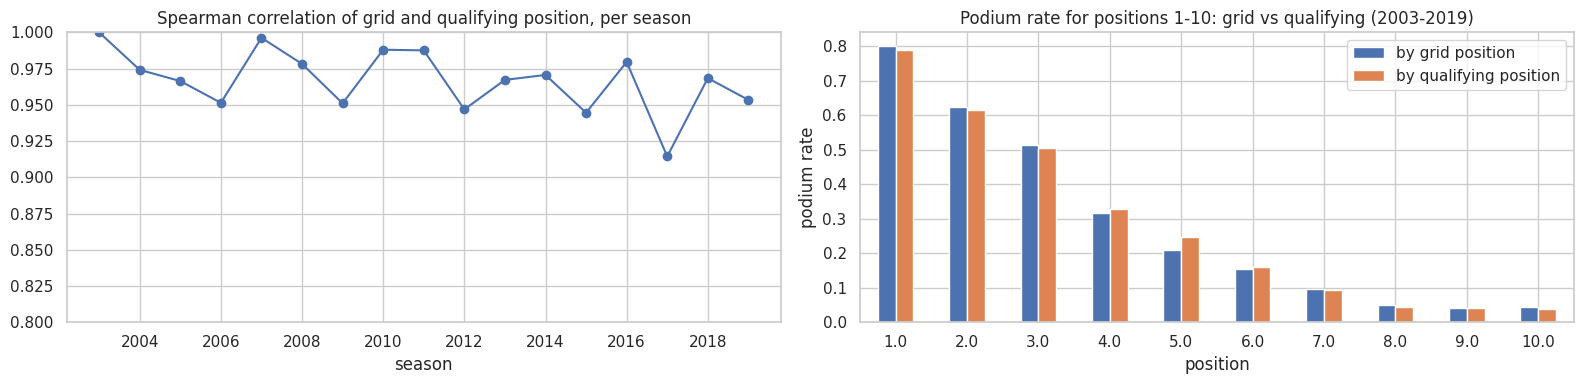

Lowest per-season Spearman correlation: 0.914 (2017)


In [42]:
gq = feat_all[feat_all.year.between(2003, TRAIN_END)][['raceId', 'driverId', 'year', 'grid_pos', 'podium']] \
        .merge(clean['qualifying'][['raceId', 'driverId', 'position']].rename(columns={'position': 'quali_pos'}),
               on=['raceId', 'driverId'], how='left')
print(f'Starts 2003-{TRAIN_END}: {len(gq)} | with a qualifying position: {gq.quali_pos.notna().sum()}')
gq = gq.dropna(subset=['quali_pos']).astype({'quali_pos': float})

gap = (gq.grid_pos - gq.quali_pos).abs()
print(f'Pearson correlation  grid vs qualifying: {gq.grid_pos.corr(gq.quali_pos):.3f}')
print(f'Spearman correlation grid vs qualifying: {gq.grid_pos.corr(gq.quali_pos, method="spearman"):.3f}')
print(f'Grid identical to qualifying position: {(gap == 0).mean():.1%} | within 1 place: {(gap <= 1).mean():.1%} | within 3 places: {(gap <= 3).mean():.1%}')

power = pd.DataFrame({name: {'PR-AUC': average_precision_score(gq.podium, 1 / gq[col]), 'ROC-AUC': roc_auc_score(gq.podium, 1 / gq[col])}
                      for name, col in [('grid position', 'grid_pos'), ('qualifying position', 'quali_pos')]}).T
lo, hi = race_bootstrap_diff(gq.podium, 1 / gq.grid_pos, 1 / gq.quali_pos, gq.raceId)
print(f'PR-AUC difference grid minus qualifying: {power.iloc[0, 0] - power.iloc[1, 0]:+.3f}, 95% range [{lo:+.3f}, {hi:+.3f}]')
display(power.round(4))

per_season = gq.groupby('year').apply(lambda d: d.grid_pos.corr(d.quali_pos, method='spearman'))
by_pos = pd.DataFrame({'by grid position': gq[gq.grid_pos <= 10].groupby('grid_pos').podium.mean(),
                       'by qualifying position': gq[gq.quali_pos <= 10].groupby('quali_pos').podium.mean()})
fig, axes = plt.subplots(1, 2, figsize=(16, 4))
per_season.plot(ax=axes[0], marker='o'); axes[0].set_ylim(0.8, 1.0)
axes[0].set_title('Spearman correlation of grid and qualifying position, per season'); axes[0].set_xlabel('season')
by_pos.plot.bar(ax=axes[1], rot=0); axes[1].set_title('Podium rate for positions 1-10: grid vs qualifying (2003-2019)')
axes[1].set_xlabel('position'); axes[1].set_ylabel('podium rate')
plt.tight_layout(); plt.show()
print('Lowest per-season Spearman correlation:', round(per_season.min(), 3), f'({int(per_season.idxmin())})')


**What the output shows (2003–2019, 6,804 starts with both values):**
* **Correlation:** Pearson **0.968**, Spearman **0.969**. Every single season is above 0.91 (lowest: 2017, 0.914, a season with many engine-penalty grid drops).
* **Agreement:** the grid slot equals the qualifying position for **72.8%** of starts, is within 1 place for 90.9% and within 3 places for 96.2%.
* **Predictive power on its own:** grid PR-AUC **0.626** vs qualifying 0.618 (ROC-AUC 0.908 vs 0.910). The difference, +0.007 for grid, has a 95% range of [−0.000, +0.015]: the two are practically equal, with the grid if anything very slightly better, because it already includes the penalties that really decide where a car starts.
* **Podium rate per position (plot):** almost identical bars for P1–P10 under both definitions.

**Conclusion:** in the seasons where both exist, the grid carries essentially the same podium information as the qualifying position. Using the grid therefore loses almost nothing, and it is available for **every** season since 1950, which is what allows training on the full history. (Qualifying *pace*, the gap in seconds to pole, is not tested here: it does not exist before 1994 at all.)


#### 7.1.2 Experiment: does training from 1950 hurt?

**Hypothesis:** with grid instead of qualifying, every season from 1950 has complete inputs, so the model gets 3× more training rows. The risk is that old eras are different (bigger fields, more breakdowns), which could teach the model patterns that do not hold today.

**Experiment:** train the *same* two simple models (logistic regression, and default gradient boosting) on three windows (1950, 1994, 2003 → 2019) with the same features and preprocessing, and evaluate on the **validation** seasons only.

In [43]:
window_rows, window_preds = [], {}
for start in [1950, 1994, 2003]:
    tr, va, _ = split(feat_all, start)
    for mname, model in [('LogReg', LogisticRegression(max_iter=2000)),
                         ('HistGB (default)', HistGradientBoostingClassifier(random_state=SEED))]:
        pipe = Pipeline([('prep', make_preprocessor()), ('model', model)]).fit(tr[FEATURES], tr.podium)
        p = pipe.predict_proba(va[FEATURES])[:, 1]
        window_preds[(start, mname)] = p
        window_rows.append({'train window': f'{start}-2019', 'model': mname, 'train rows': len(tr),
                            'podium rate in train': round(tr.podium.mean(), 3),
                            'val PR-AUC': average_precision_score(va.podium, p), 'val ROC-AUC': roc_auc_score(va.podium, p)})
window_res = pd.DataFrame(window_rows)
window_res['PR-AUC diff (1950 minus this), 95% range'] = ''
for mname in ['LogReg', 'HistGB (default)']:
    for start in [1994, 2003]:
        lo, hi = race_bootstrap_diff(val_df.podium, window_preds[(1950, mname)], window_preds[(start, mname)], val_df.raceId)
        window_res.loc[(window_res.model == mname) & (window_res['train window'] == f'{start}-2019'),
                       'PR-AUC diff (1950 minus this), 95% range'] = f'[{lo:+.3f}, {hi:+.3f}]'
window_res.round(4)

,train window,model,train rows,podium rate in train,val PR-AUC,val ROC-AUC,"PR-AUC diff (1950 minus this), 95% range"
0,1950-2019,LogReg,22782,0.133,0.7206,0.9260,
1,1950-2019,HistGB (default),22782,0.133,0.6993,0.9243,
2,1994-2019,LogReg,10165,0.139,0.7158,0.9260,"[-0.003, +0.015]"
3,1994-2019,HistGB (default),10165,0.139,0.6582,0.9236,"[+0.014, +0.063]"
4,2003-2019,LogReg,6827,0.141,0.7278,0.9261,"[-0.024, +0.013]"
5,2003-2019,HistGB (default),6827,0.141,0.6367,0.9216,"[+0.030, +0.086]"



**What the output shows:** with the same 17 grid-based features:

| Train window | rows | LogReg val PR-AUC | HistGB val PR-AUC |
|---|---|---|---|
| **1950–2019** | 22,782 | 0.721 | **0.699** |
| 1994–2019 | 10,165 | 0.716 | 0.658 |
| 2003–2019 | 6,827 | 0.728 | 0.637 |

* **Logistic regression:** all three windows are tied (both 95% ranges of the difference contain 0).
* **Gradient boosting:** the full history is **significantly better** than both shorter windows (1950 minus 1994: [+0.014, +0.063]; 1950 minus 2003: [+0.030, +0.086]). A flexible model needs more data, and the old seasons provide it.

**Interpretation:** the old seasons do **not** hurt performance on modern races; for the more flexible model they clearly help. The model sees 3× more podiums (3,021 vs ~960 for 2003–2019) and every era of F1.

**Decision: train on 1950–2019.**


In [44]:
TRAIN_START = 1950
train_df, val_df, test_df = split(feat_all, TRAIN_START)
model_table = pd.concat([train_df, val_df, test_df])
assert not model_table.duplicated(['raceId', 'driverId']).any()
assert set(train_df.raceId).isdisjoint(val_df.raceId) and set(val_df.raceId).isdisjoint(test_df.raceId)
split_summary = pd.DataFrame({
    'seasons': [f'{TRAIN_START}-{TRAIN_END}', f'{VAL_YEARS[0]}-{VAL_YEARS[1]}', f'{TEST_START}-{feat_all.year.max()}'],
    'races': [d.raceId.nunique() for d in (train_df, val_df, test_df)],
    'rows': [len(d) for d in (train_df, val_df, test_df)],
    'podiums': [int(d.podium.sum()) for d in (train_df, val_df, test_df)],
    'podium rate': [round(d.podium.mean(), 4) for d in (train_df, val_df, test_df)]}, index=['train', 'validation', 'test'])
model_table.to_csv('f1_modeling_table.csv', index=False)
print('Final modeling table:', model_table.shape, '-> saved to f1_modeling_table.csv; (raceId, driverId) unique:',
      not model_table.duplicated(['raceId', 'driverId']).any())
split_summary

Final modeling table: (24921, 24) -> saved to f1_modeling_table.csv; (raceId, driverId) unique: True


,seasons,races,rows,podiums,podium rate
train,1950-2019,1007,22782,3021,0.1326
validation,2020-2021,39,780,117,0.1500
test,2022-2024,68,1359,204,0.1501



**What the output shows:** the final modeling table has **24,921 rows** (one per driver–race, 1950–2024), saved as `f1_modeling_table.csv`. Train: 1,007 races / 22,782 rows / 3,021 podiums; validation: 39 races / 780 rows; test: 68 races / 1,359 rows. The training podium rate is lower (13.3% vs 15.0%) because early seasons had larger fields; `field_size` is a feature so the model can account for it.


### 7.2 Plotting the effect of each feature on the podium rate (training seasons only)

**What:** for each feature, the podium rate as a function of the feature's value (binned).
**Why:** this is the *hypothesis-driven* evidence the brief asks for. A feature is worth including if the podium rate clearly changes along its range. **Only training rows (1950–2019) are used**, so the validation and test seasons stay unseen. Each x-axis label shows the bin and its number of rows `n`: a rate based on few rows is unreliable.

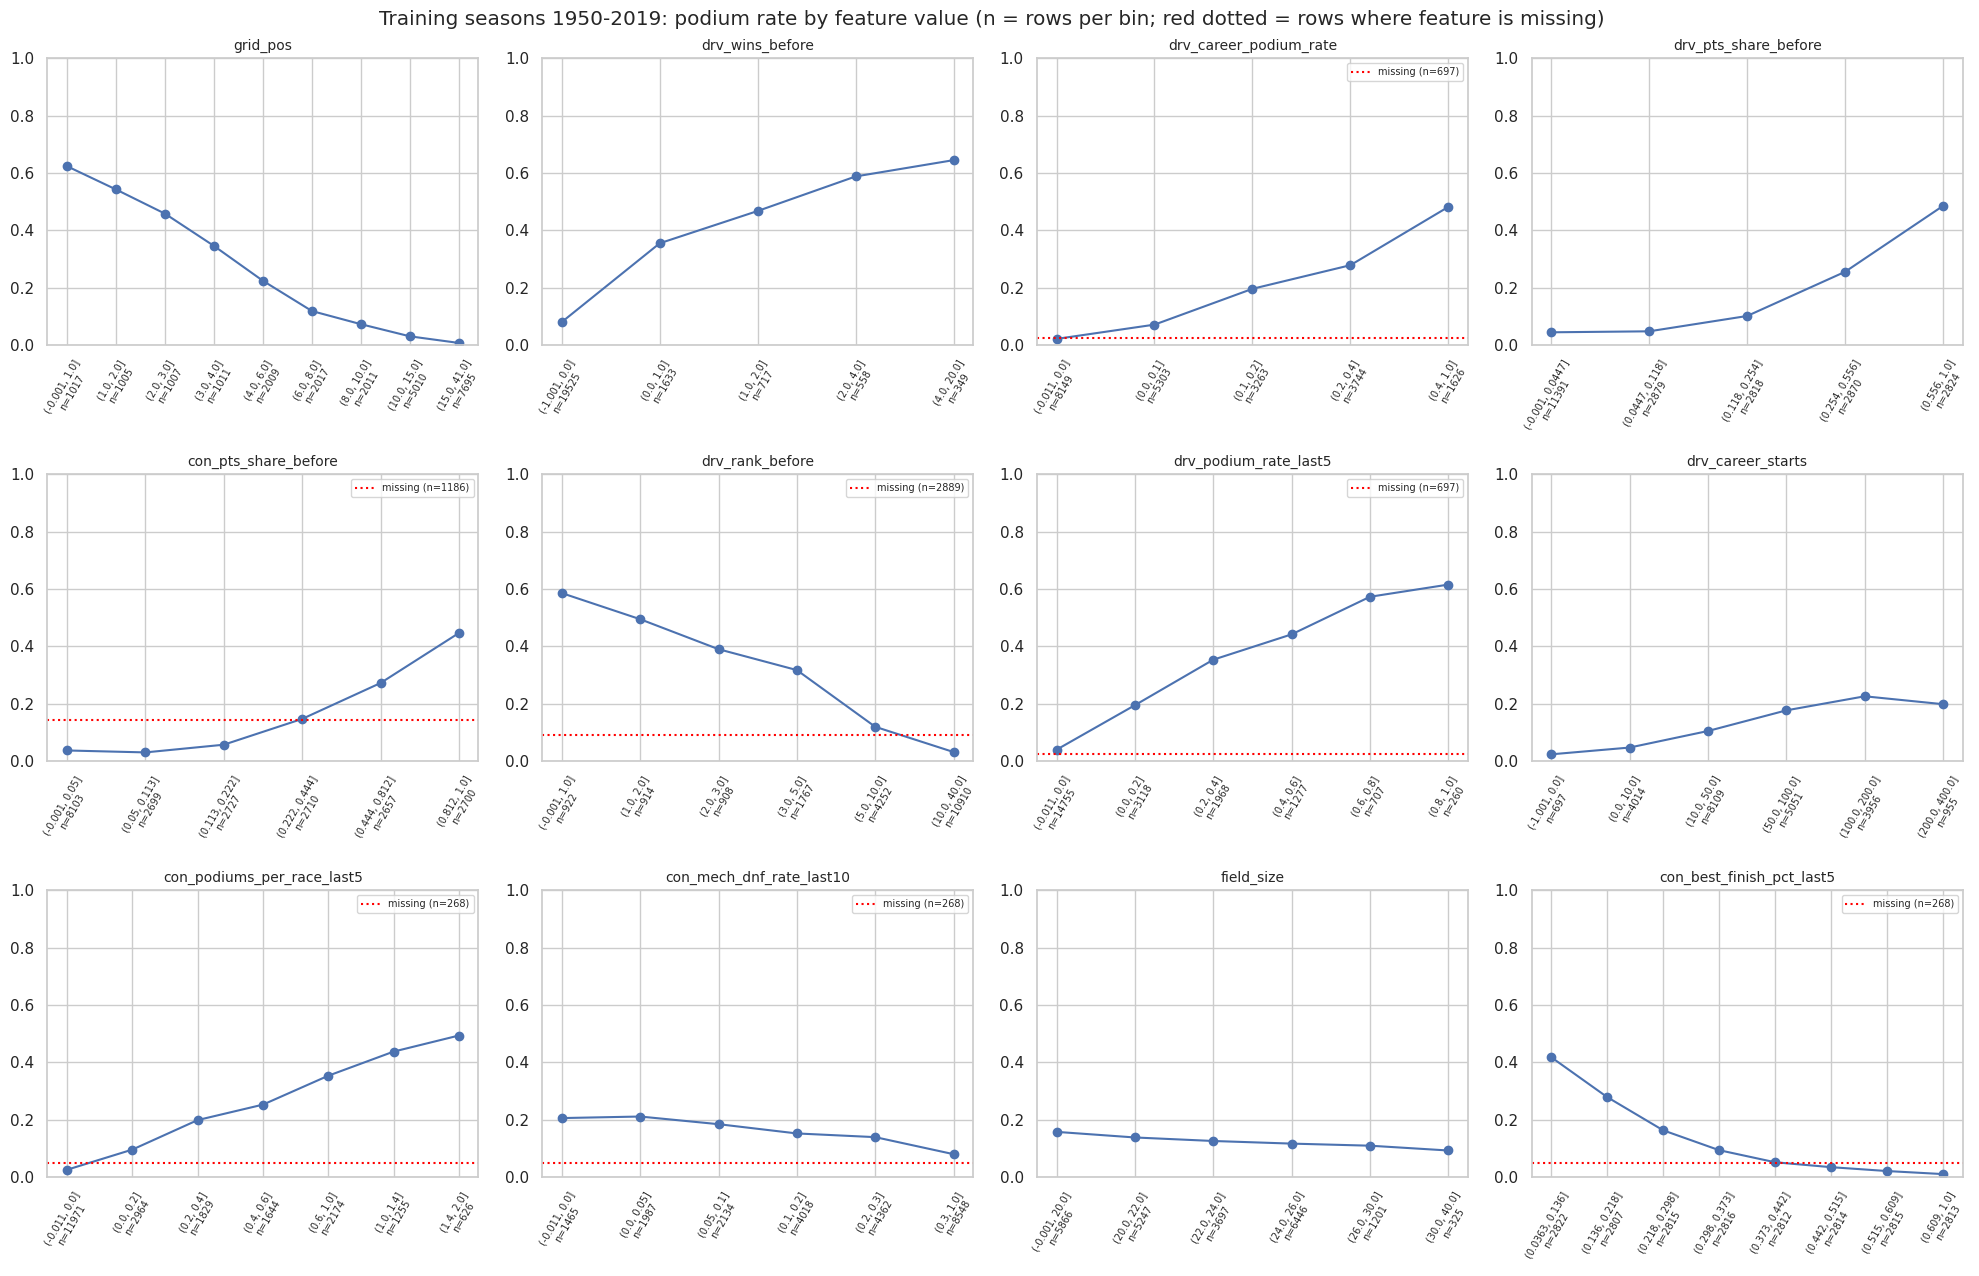

In [45]:
def binned_rate(ax, df, col, bins=None, q=None, title=None):
    x = df[col]
    if q: cats = pd.qcut(x, q=q, duplicates='drop')
    else: cats = pd.cut(x, bins=bins, include_lowest=True)
    t = df.groupby(cats, observed=True).podium.agg(['mean', 'size'])
    ax.plot(range(len(t)), t['mean'], marker='o')
    ax.set_xticks(range(len(t))); ax.set_xticklabels([f'{i}\nn={n}' for i, n in zip(t.index, t['size'])], rotation=60, fontsize=7)
    ax.set_title(title or col, fontsize=10); ax.set_ylim(0, 1)
    if x.isna().any():
        ax.axhline(df[x.isna()].podium.mean(), ls=':', c='red', label=f'missing (n={x.isna().sum()})'); ax.legend(fontsize=7)

fig, axes = plt.subplots(3, 4, figsize=(20, 13))
specs = [('grid_pos', [0, 1, 2, 3, 4, 6, 8, 10, 15, 41], None), ('drv_wins_before', [-1, 0, 1, 2, 4, 20], None), ('drv_career_podium_rate', [-.01, 0, .1, .2, .4, 1], None),
         ('drv_pts_share_before', None, 8), ('con_pts_share_before', None, 8), ('drv_rank_before', [0, 1, 2, 3, 5, 10, 40], None),
         ('drv_podium_rate_last5', [-.01, 0, .2, .4, .6, .8, 1], None), ('drv_career_starts', [-1, 0, 10, 50, 100, 200, 400], None),
         ('con_podiums_per_race_last5', [-.01, 0, .2, .4, .6, 1, 1.4, 2], None), ('con_mech_dnf_rate_last10', [-.01, 0, .05, .1, .2, .3, 1], None),
         ('field_size', [0, 20, 22, 24, 26, 30, 40], None), ('con_best_finish_pct_last5', None, 8)]
for ax, (col, b, q) in zip(axes.ravel(), specs):
    binned_rate(ax, train_df, col, bins=b, q=q)
plt.suptitle('Training seasons 1950-2019: podium rate by feature value (n = rows per bin; red dotted = rows where feature is missing)')
plt.tight_layout(); plt.show()


**What the plots show (training seasons 1950–2019):**
* **grid_pos:** the strongest and most non-linear pattern: **62% podium rate from pole, 54% from P2, 46% from P3, 35% from P4**, then 12% from P7–8 and under 1% from P16 back (including grid 0 → field size + 1). The drop is steep at the front and flat at the back, so a linear model will struggle with it (§9).
* **Standings:** podium rate rises steadily with points share (4% in the lowest bins → 49% in the top bin) and with wins before the race (8% with none → 65% with 5 or more).
* **Driver form:** 3.9% with no podium in the last 5 races → 62% with 5 of 5; career podium rate shows the same pattern (2% → 48%).
* **Constructor form:** podium rate falls as the team's recent best finishing position gets worse; for reliability, about 21% podium rate when the team had at most 5% mechanical failures in its last 10 races, falling to 8% when more than 30% of recent starts failed.
* **Experience:** debutants rarely podium (2.3%); 100–200 previous starts is the peak (23%).
* **Context:** larger fields lower the podium rate (16% with ≤20 cars → 9% with 31+).
* **Missing values (red line):** pre-1958 constructor standings (missing by design, §5.2) have a 14% podium rate, close to average; drivers without form history (debutants) 2.3%.
* **Grid 0:** the 232 training rows with `pitlane_start = 1` never finished on the podium.

**Decision:** every group shows a clear, monotone relationship with the podium rate.


### 7.3 Correlations: strength and redundancy

**What:** (a) Spearman correlation of every feature with the target; (b) the feature–feature correlation heatmap.
**Why:** (a) gives a one-number ranking of univariate strength; Spearman is used because most relationships are monotone but not linear (see grid above). (b) shows **redundancy**. Strongly correlated features (e.g. points share and championship rank) carry overlapping information. This matters for interpreting the ablation (§10) and the explanations (§11).

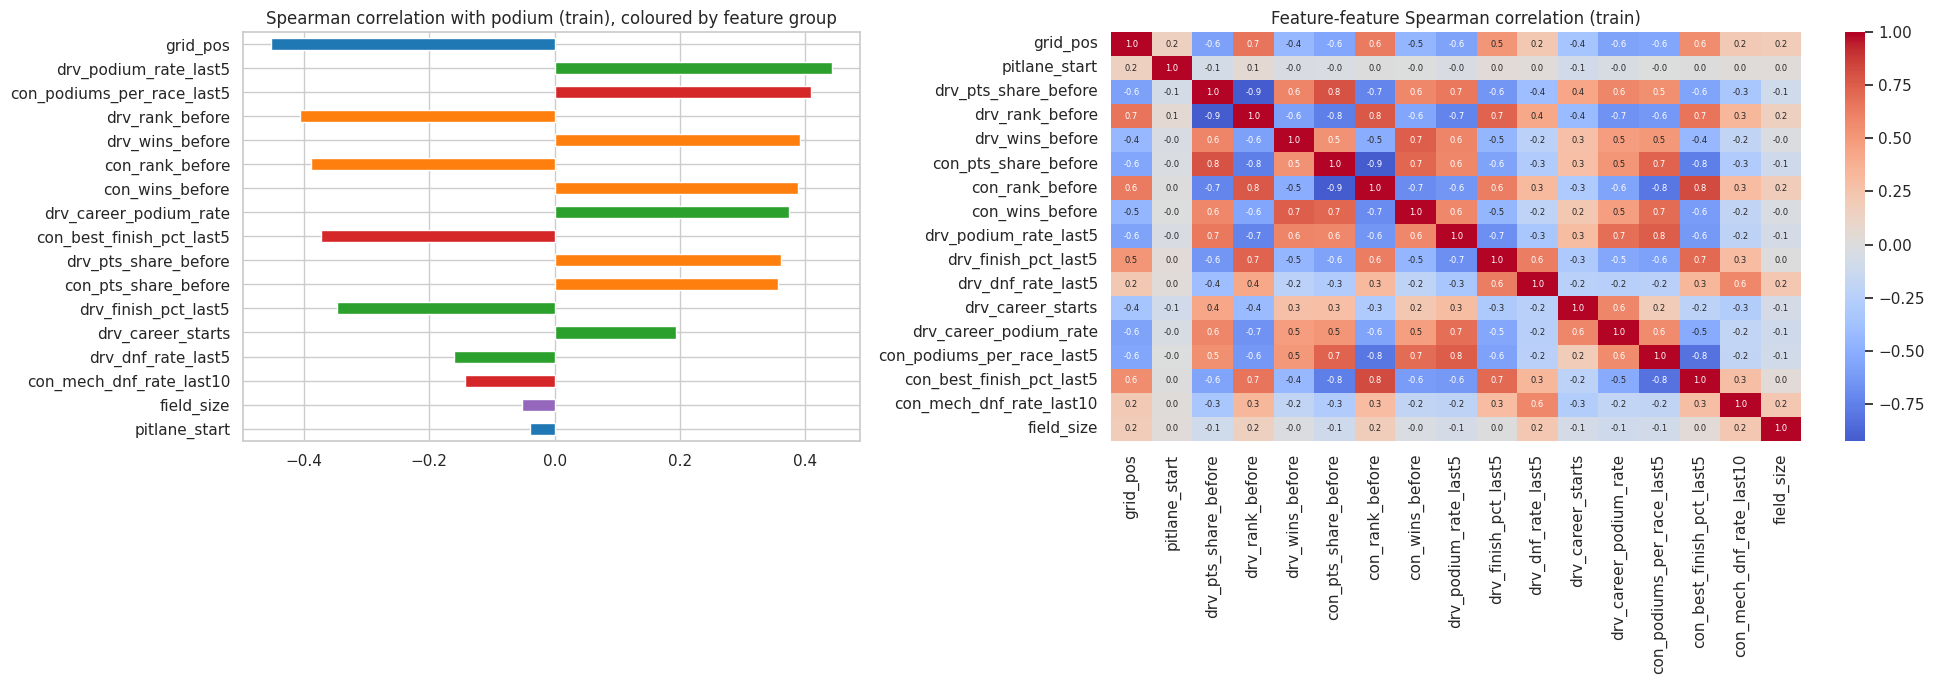

Spearman with podium: {'grid_pos': -0.452, 'drv_podium_rate_last5': 0.442, 'con_podiums_per_race_last5': 0.41, 'drv_rank_before': -0.406, 'drv_wins_before': 0.392, 'con_rank_before': -0.389, 'con_wins_before': 0.388, 'drv_career_podium_rate': 0.374, 'con_best_finish_pct_last5': -0.372, 'drv_pts_share_before': 0.36, 'con_pts_share_before': 0.356, 'drv_finish_pct_last5': -0.348, 'drv_career_starts': 0.194, 'drv_dnf_rate_last5': -0.16, 'con_mech_dnf_rate_last10': -0.142, 'field_size': -0.052, 'pitlane_start': -0.04}
Strongly redundant pairs (|rho| > 0.8):
   ('drv_pts_share_before', 'drv_rank_before', np.float64(-0.92))
   ('drv_pts_share_before', 'con_pts_share_before', np.float64(0.8))
   ('con_pts_share_before', 'con_rank_before', np.float64(-0.92))
   ('con_rank_before', 'con_best_finish_pct_last5', np.float64(0.82))
   ('con_podiums_per_race_last5', 'con_best_finish_pct_last5', np.float64(-0.83))


In [46]:
spear = train_df[FEATURES + ['podium']].astype(float).corr(method='spearman')
target_corr = spear['podium'].drop('podium').sort_values(key=np.abs, ascending=False)
group_of = {f: g for g, fs in FEATURE_GROUPS.items() for f in fs}
fig, axes = plt.subplots(1, 2, figsize=(20, 7), gridspec_kw={'width_ratios': [1, 1.4]})
target_corr.plot.barh(ax=axes[0], color=[sns.color_palette('tab10')[list(FEATURE_GROUPS).index(group_of[f])] for f in target_corr.index])
axes[0].invert_yaxis(); axes[0].set_title('Spearman correlation with podium (train), coloured by feature group')
sns.heatmap(spear.loc[FEATURES, FEATURES], cmap='coolwarm', center=0, ax=axes[1], annot=True, fmt='.1f', annot_kws={'size': 6})
axes[1].set_title('Feature-feature Spearman correlation (train)')
plt.tight_layout(); plt.show()
print('Spearman with podium:', target_corr.round(3).to_dict())
print('Strongly redundant pairs (|rho| > 0.8):')
pairs = [(a, b, round(spear.loc[a, b], 2)) for i, a in enumerate(FEATURES) for b in FEATURES[i + 1:] if abs(spear.loc[a, b]) > .8]
for p in pairs: print('  ', p)


**What the output shows:**
* **Univariate strength (|Spearman ρ|):** grid position (−0.45), recent podium rate (0.44), constructor podiums (0.41), driver rank before the race (−0.41), driver and constructor wins (0.39) lead. `field_size` and `pitlane_start` are near 0 on their own.
* **Redundancy:** 5 pairs exceed |ρ| = 0.8, all inside the season-strength block: driver points share ↔ rank (−0.92), constructor points share ↔ rank (−0.92), driver ↔ constructor points share (0.80), and two constructor form/standings pairs.

**Consequences:** (1) removing standings or form alone should cost little, because the other substitutes for it; §10 therefore also removes them together. (2) Permutation/SHAP importance can be split arbitrarily between correlated features, so §11 also reports importance **per group**. (3) Linear-model coefficients for individual features in this block are unstable and are not interpreted.


### 7.4 Empirical evidence: adding feature groups step by step

**Hypothesis:** grid alone is a strong baseline (guide + §7.2). Standings and form should add information about car/driver strength that one grid slot does not fully capture (e.g. a fast car starting further back after a bad qualifying or a penalty).

**Experiment (kept visible, as the brief requires):** the same logistic regression and preprocessing, adding one group at a time. Evaluated on **validation** only.

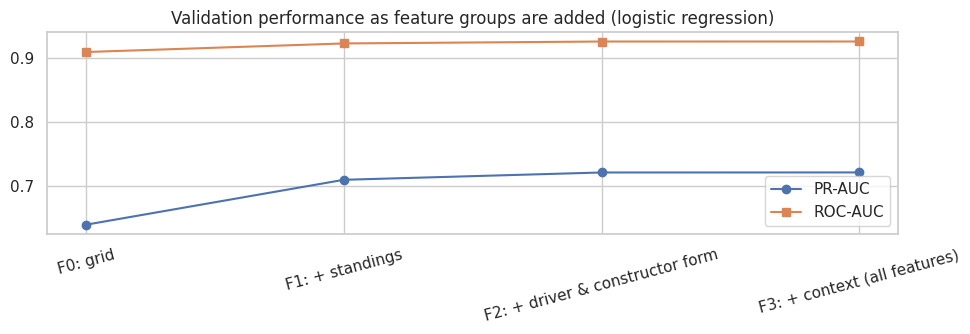

,feature set,n features,val PR-AUC,val ROC-AUC,"PR-AUC gain vs previous, 95% CI"
0,F0: grid,2,0.6386,0.9095,
1,F1: + standings,8,0.7090,0.9229,"[+0.022, +0.121]"
2,F2: + driver & constructor form,16,0.7205,0.9259,"[-0.024, +0.054]"
3,F3: + context (all features),17,0.7206,0.9260,"[-0.001, +0.001]"


In [47]:
steps = [('F0: grid', ['grid']), ('F1: + standings', ['grid', 'standings']),
         ('F2: + driver & constructor form', ['grid', 'standings', 'driver_form', 'constructor_form']),
         ('F3: + context (all features)', list(FEATURE_GROUPS))]
fs_rows, fs_preds = [], {}
for name, groups in steps:
    cols = [f for g in groups for f in FEATURE_GROUPS[g]]
    pipe = Pipeline([('prep', make_preprocessor()), ('model', LogisticRegression(max_iter=2000))]).fit(train_df[cols], train_df.podium)
    p = pipe.predict_proba(val_df[cols])[:, 1]; fs_preds[name] = p
    fs_rows.append({'feature set': name, 'n features': len(cols), 'val PR-AUC': average_precision_score(val_df.podium, p),
                    'val ROC-AUC': roc_auc_score(val_df.podium, p)})
fs_res = pd.DataFrame(fs_rows)
names = [s[0] for s in steps]
fs_res['PR-AUC gain vs previous, 95% CI'] = [''] + [
    '[{:+.3f}, {:+.3f}]'.format(*race_bootstrap_diff(val_df.podium, fs_preds[b], fs_preds[a], val_df.raceId))
    for a, b in zip(names[:-1], names[1:])]
fig, ax = plt.subplots(figsize=(10, 3.5))
ax.plot(fs_res['feature set'], fs_res['val PR-AUC'], marker='o', label='PR-AUC')
ax.plot(fs_res['feature set'], fs_res['val ROC-AUC'], marker='s', label='ROC-AUC')
ax.set_title('Validation performance as feature groups are added (logistic regression)'); ax.legend(); plt.xticks(rotation=15)
plt.tight_layout(); plt.show()
fs_res.round(4)


**What the output shows (validation PR-AUC, logistic regression):** grid alone **0.639** → **+ standings 0.709** (gain range [+0.022, +0.121], significant) → + form 0.721 (range [−0.024, +0.054]) → + context 0.721 (range [−0.001, +0.001]).

**Interpretation:** season standings add real information beyond the grid order. Form adds a little that the data cannot confirm *for a linear model* on top of standings, which is expected from the redundancy in §7.3; it may still help non-linear models (tested by ablation in §10). Field size adds nothing for the linear model.

**Decision:** keep all 17 features for the model comparison. The brief asks for form features, the non-linear models may use them, and §10 measures each group's contribution inside the final model. ROC-AUC barely moves (0.910 → 0.926) while PR-AUC moves by +0.08, which illustrates why PR-AUC is our primary metric (§9.1).


---
## 8. Pre-processing

### 8.1 The pipeline and why each step exists

| Step | What it does | Why needed | Affects | Fitted on |
|---|---|---|---|---|
| `SimpleImputer(strategy='median')` | fills NaN with the **training** median | sklearn models and Keras cannot take NaN. The median is robust to skewed columns such as `drv_career_starts` (Lab 1 chose the median for the same reason) | qualifying features (missing when no qualifying record), standings rank (round 1), form features (debutants) | train only |
| `add_indicator=True` | adds a 0/1 column "this value was missing" for every feature that had NaN in train | missingness is **informative** here: a missing `drv_rank_before` means round 1, missing form means a debutant. The indicator lets the model treat "imputed" differently from "really median" | same columns | train only |
| `StandardScaler` | (x − mean) / std per column | logistic regression (regularisation) and the neural network (gradient descent) are sensitive to feature scale (Lab 3: carat vs price). Trees are unaffected but receive the same matrix so all models see identical inputs | all columns | train only |

No categorical encoding is needed: every selected feature is numeric or binary. We deliberately did **not** one-hot encode `constructorId`. Team identities change across eras (renames), and team strength is already captured by constructor form and standings.

**Leakage risk:** fitting the imputer/scaler on validation or test rows would let their medians/means influence the training inputs. Experiment E2 below measures this.

In [48]:
prep = make_preprocessor().fit(train_df[FEATURES])
FEAT_OUT = list(prep.get_feature_names_out(FEATURES))
X_tr, X_va, X_te = (prep.transform(d[FEATURES]) for d in (train_df, val_df, test_df))
y_tr, y_va, y_te = (d.podium.values.astype(int) for d in (train_df, val_df, test_df))
print('Input features:', len(FEATURES), '-> after preprocessing:', len(FEAT_OUT), 'columns')
print('Added missing-indicator columns:', [f for f in FEAT_OUT if f.startswith('missingindicator')])
print('NaN remaining after preprocessing (train/val/test):', int(np.isnan(X_tr).sum()), int(np.isnan(X_va).sum()), int(np.isnan(X_te).sum()))

before = train_df[FEATURES].describe().T[['mean', 'std', 'min', 'max']]
after = pd.DataFrame(X_tr, columns=FEAT_OUT)[FEATURES].describe().T[['mean', 'std', 'min', 'max']]
eff = pd.concat({'before (train, raw)': before, 'after (train, transformed)': after}, axis=1)
eff['missing in train'] = train_df[FEATURES].isna().sum()
eff.round(3)

Input features: 17 -> after preprocessing: 28 columns
Added missing-indicator columns: ['missingindicator_drv_rank_before', 'missingindicator_con_pts_share_before', 'missingindicator_con_rank_before', 'missingindicator_con_wins_before', 'missingindicator_drv_podium_rate_last5', 'missingindicator_drv_finish_pct_last5', 'missingindicator_drv_dnf_rate_last5', 'missingindicator_drv_career_podium_rate', 'missingindicator_con_podiums_per_race_last5', 'missingindicator_con_best_finish_pct_last5', 'missingindicator_con_mech_dnf_rate_last10']
NaN remaining after preprocessing (train/val/test): 0 0 0


before (train, raw)                          after (train, transformed)                     missing in train
                                          mean     std     min      max                       mean  std    min     max                 
grid_pos                                12.046   6.928   1.000   39.000                       -0.0  1.0 -1.594   3.891                0
pitlane_start                            0.010   0.100   0.000    1.000                       -0.0  1.0 -0.101   9.859                0
drv_pts_share_before                     0.185   0.279   0.000    1.000                       -0.0  1.0 -0.664   2.919                0
drv_rank_before                         13.059   9.107   1.000  102.000                        0.0  1.0 -1.400  10.458             2889
drv_wins_before                          0.316   1.031   0.000   13.000                       -0.0  1.0 -0.307  12.307                0
con_pts_share_before                     0.271   0.333   0.000    1.000                        0.0  1.0 -0.808   2.262             1186
con_rank_before                          6.165   3.701   1.000   20.000                       -0.0  1.0 -1.487   4.005             2876
con_wins_before                          0.704   1.739   0.000   18.000                        0.0  1.0 -0.392  10.191             1186
drv_podium_rate_last5                    0.135   0.233   0.000    1.000                       -0.0  1.0 -0.570   3.771              697
drv_finish_pct_last5                     0.517   0.185   0.032    1.042                       -0.0  1.0 -2.670   2.886              697
drv_dnf_rate_last5                       0.421   0.287   0.000    1.000                       -0.0  1.0 -1.489   2.050              697
drv_career_starts                       61.520  61.881   0.000  324.000                        0.0  1.0 -0.994   4.242                0
drv_career_podium_rate                   0.120   0.155   0.000    1.000                        0.0  1.0 -0.768   5.745              697
con_podiums_per_race_last5               0.314   0.464   0.000    3.000                       -0.0  1.0 -0.672   5.818              268
con_best_finish_pct_last5                0.375   0.192   0.037    1.000                       -0.0  1.0 -1.773   3.277              268
con_mech_dnf_rate_last10                 0.267   0.180   0.000    1.000                       -0.0  1.0 -1.491   4.098              268
field_size                              23.054   3.073  10.000   38.000                       -0.0  1.0 -4.248   4.864                0

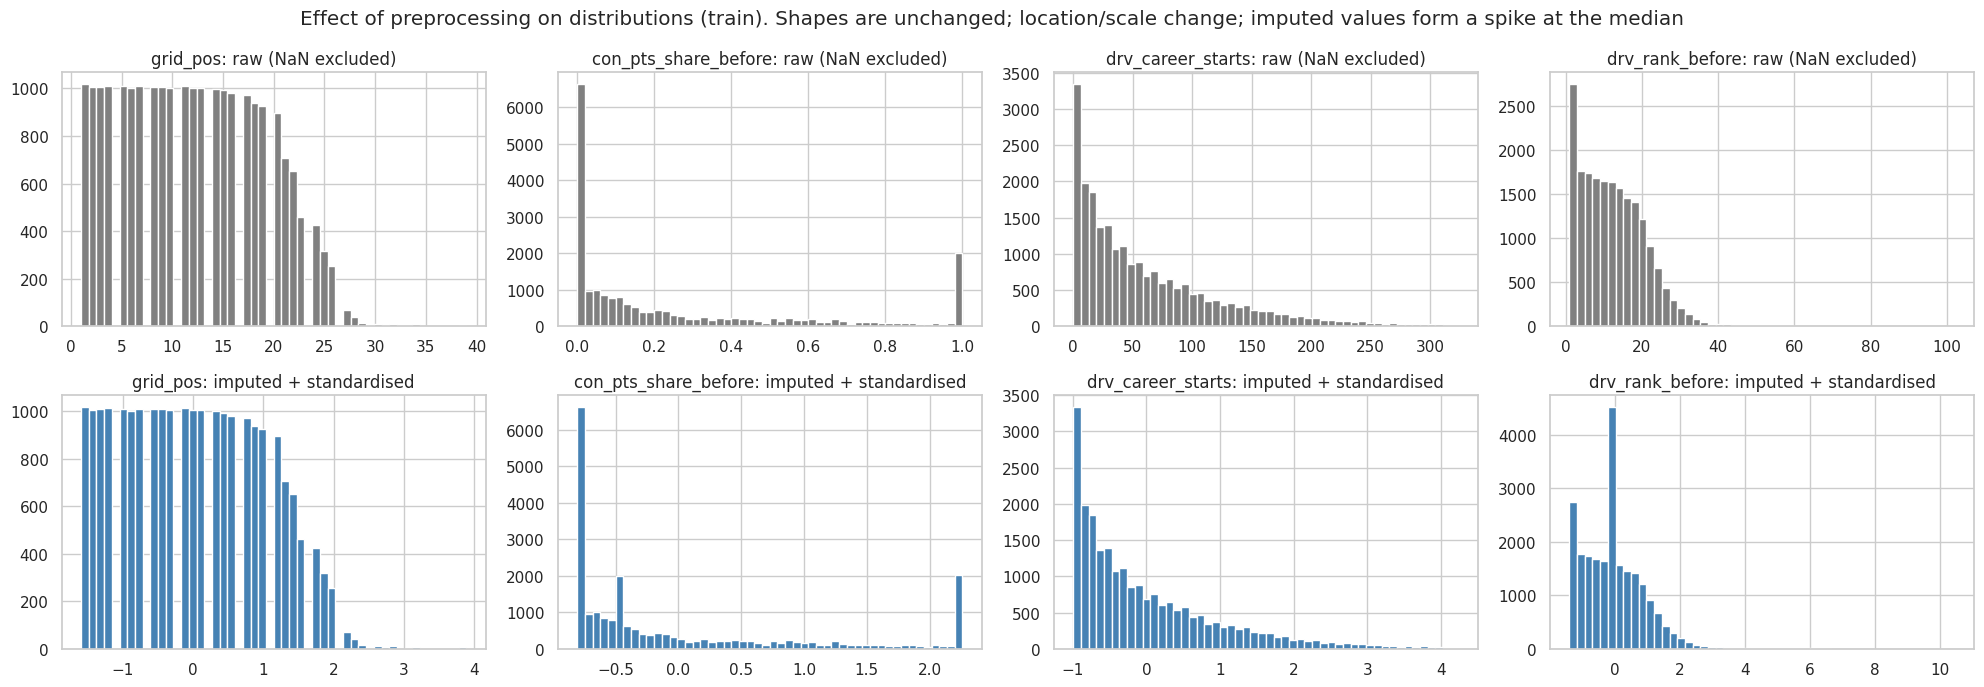

In [49]:
fig, axes = plt.subplots(2, 4, figsize=(20, 7))
X_tr_df = pd.DataFrame(X_tr, columns=FEAT_OUT)
for j, col in enumerate(['grid_pos', 'con_pts_share_before', 'drv_career_starts', 'drv_rank_before']):
    axes[0, j].hist(train_df[col].dropna(), bins=50, color='gray'); axes[0, j].set_title(f'{col}: raw (NaN excluded)')
    axes[1, j].hist(X_tr_df[col], bins=50, color='steelblue'); axes[1, j].set_title(f'{col}: imputed + standardised')
plt.suptitle('Effect of preprocessing on distributions (train). Shapes are unchanged; location/scale change; imputed values form a spike at the median')
plt.tight_layout(); plt.show()


**What the output shows:** 17 input features become **28 columns**: the 17 scaled features plus 11 missing-indicator columns (driver and constructor rank before the race, the three pre-1958 constructor-standings features, driver form ×4, constructor form ×3). No NaN remains in train, validation or test.

After scaling, every training column has mean 0 and std 1, but the shapes are unchanged (histograms): skewed columns stay skewed, e.g. `drv_wins_before` reaches 12.3 standard deviations and the rare `pitlane_start` flag 9.9. Missing values sit at the median (the spike in the `drv_rank_before` histogram: 2,889 rows, mainly first rounds of a season).


### 8.2 Pre-processing-order experiments

Each experiment changes **only the order or scope** of preprocessing. Everything else is the same: logistic regression (C=1), the same features, train → validation. The test set is not involved.

* **E1: impute → scale vs scale → impute.** Scaling first computes the mean/std on observed values only; imputing first includes the imputed medians, which shrinks the std. Does the order matter?
* **E2: fit preprocessing *before* splitting (on train+val+test) vs on train only.** This is the classic leakage-by-ordering mistake. The leaky version uses statistics of future seasons.

In [50]:
def eval_lr(Xtr, Xva, label):
    m = LogisticRegression(max_iter=2000).fit(Xtr, y_tr); p = m.predict_proba(Xva)[:, 1]
    return {'experiment': label, 'val PR-AUC': average_precision_score(y_va, p), 'val ROC-AUC': roc_auc_score(y_va, p)}, p

exp_rows, exp_p = [], {}
# --- reference: impute -> scale, fitted on train
r, exp_p['ref'] = eval_lr(X_tr, X_va, 'REF: impute -> scale (fit on train)'); exp_rows.append(r)
# --- E1: scale -> impute
e1 = Pipeline([('scale', StandardScaler()), ('impute', SimpleImputer(strategy='median', add_indicator=True))]).fit(train_df[FEATURES])
r, exp_p['E1'] = eval_lr(e1.transform(train_df[FEATURES]), e1.transform(val_df[FEATURES]), 'E1: scale -> impute (fit on train)'); exp_rows.append(r)
# --- E2: preprocessing fitted on ALL rows before splitting (leaky order)
e2 = make_preprocessor().fit(pd.concat([train_df, val_df, test_df])[FEATURES])
r, exp_p['E2'] = eval_lr(e2.transform(train_df[FEATURES]), e2.transform(val_df[FEATURES]), 'E2: impute -> scale fitted on train+val+test (LEAKY)'); exp_rows.append(r)
exp_res = pd.DataFrame(exp_rows)
exp_res['PR-AUC diff vs REF, 95% CI'] = ''
for k, lab in zip(['E1', 'E2'], exp_res.experiment[1:]):
    lo, hi = race_bootstrap_diff(y_va, exp_p[k], exp_p['ref'], val_df.raceId)
    exp_res.loc[exp_res.experiment == lab, 'PR-AUC diff vs REF, 95% CI'] = f'[{lo:+.4f}, {hi:+.4f}]'
print('Scaler mean of drv_career_starts - train-only fit:', round(prep.named_steps['scale'].mean_[FEATURES.index('drv_career_starts')], 3),
      '| fit on all rows:', round(e2.named_steps['scale'].mean_[FEATURES.index('drv_career_starts')], 3))
exp_res.round(4)

Scaler mean of drv_career_starts - train-only fit: 61.52 | fit on all rows: 68.009


,experiment,val PR-AUC,val ROC-AUC,"PR-AUC diff vs REF, 95% CI"
0,REF: impute -> scale (fit on train),0.7206,0.926,
1,E1: scale -> impute (fit on train),0.7212,0.926,"[-0.0006, +0.0021]"
2,E2: impute -> scale fitted on train+val+test (...,0.7208,0.926,"[-0.0005, +0.0012]"



**What the output shows (validation, logistic regression):**
* **E1 scale → impute:** PR-AUC 0.7212 vs 0.7206 (range [−0.001, +0.002]): no effect here.
* **E2 fit on all rows (leaky):** PR-AUC 0.7208 vs 0.7206 (range [−0.001, +0.001]). The leaky statistics do shift (e.g. the mean of `drv_career_starts` 61.5 → 68.0, because modern drivers have longer careers), but with linear scaling the effect on the ranking is negligible. **This does not make it acceptable**: the effect is small only for this model and these features, and it would be a methodological error in any report.

**Decision:** final pipeline = **impute (median + indicator) → scale, fitted on training rows only**.


In [51]:
# Final preprocessing (decision recorded in the markdown above): impute(+indicator) -> scale, fitted on train only
def final_prep_fit(train_part, cols):
    p = make_preprocessor().fit(train_part[cols])
    return (lambda d: p.transform(d[cols])), list(p.get_feature_names_out(cols)), p

transform, FEAT_OUT, prep = final_prep_fit(train_df, FEATURES)
X_tr, X_va, X_te = transform(train_df), transform(val_df), transform(test_df)
print('Final design matrices:', X_tr.shape, X_va.shape, X_te.shape)

Final design matrices: (22782, 28) (780, 28) (1359, 28)


---
## 9. Predictive modeling

### 9.1 Metrics, primary/secondary choice, and threshold policy

| Metric | What it measures | Threshold? |
|---|---|---|
| **ROC-AUC** | probability that a random podium row is scored above a random non-podium row | no |
| **PR-AUC** (average precision) | quality of the ranking *among the top of the list*. It ignores the many easy true negatives, so it reacts to the rare positive class | no |
| **F1** | harmonic mean of precision and recall of the yes/no calls | yes |
| **Precision / Recall** | of the predicted podiums, how many were right / of the real podiums, how many we found | yes |

* **Primary metric: PR-AUC.** Podiums are a small minority of rows (about 13–15%, §7). ROC-AUC is dominated by easy negatives (back-markers who obviously will not podium), so it looks excellent even for weak models; §7.4 already shows a very high ROC-AUC for grid alone. PR-AUC asks the harder question: *are the true podium finishers at the top of the ranking?*
* **Secondary metric: F1.** The companion must eventually give a yes/no call per driver. F1 measures how good those calls are at the operating threshold, balancing false alarms against missed podiums.
* **Accuracy is reported but not used:** a model that always says "no podium" already reaches ≈ 85% accuracy.

**Threshold policy:** for each model, the probability threshold that maximises **F1 on the validation set** is chosen once and then frozen for the test set. (Consequence: validation F1 is slightly optimistic; the test F1 is the honest number.)

**Comparability:** every model is trained on the **same rows** (`X_tr`, 1950–2019) and the **same preprocessed columns**, and is evaluated on the same validation/test rows.

In [52]:
def metrics_at(y, p, thr):
    yhat = (p >= thr).astype(int)
    return {'ROC-AUC': roc_auc_score(y, p), 'PR-AUC': average_precision_score(y, p), 'F1': f1_score(y, yhat),
            'Precision': precision_score(y, yhat, zero_division=0), 'Recall': recall_score(y, yhat), 'Accuracy': accuracy_score(y, yhat)}

def best_f1_threshold(y, p):
    grid = np.unique(np.round(p, 4)) if len(np.unique(p)) < 200 else np.linspace(0.02, 0.98, 97)
    f1s = [f1_score(y, (p >= t).astype(int)) for t in grid]
    return float(grid[int(np.argmax(f1s))])

RESULTS = {}      # name -> dict(model, p_tr, p_va, thr, info)
def register(name, model, p_tr, p_va, info=''):
    thr = best_f1_threshold(y_va, p_va)
    RESULTS[name] = dict(model=model, p_tr=p_tr, p_va=p_va, thr=thr, info=info)
    m_tr, m_va = metrics_at(y_tr, p_tr, thr), metrics_at(y_va, p_va, thr)
    print(f"{name:<36} thr={thr:.3f} | train PR-AUC {m_tr['PR-AUC']:.4f} ROC {m_tr['ROC-AUC']:.4f} F1 {m_tr['F1']:.4f}"
          f" | val PR-AUC {m_va['PR-AUC']:.4f} ROC {m_va['ROC-AUC']:.4f} F1 {m_va['F1']:.4f}")

print('Design matrix columns:', X_tr.shape[1])
print('Validation accuracy of "always predict no podium":', round(1 - y_va.mean(), 4))

Design matrix columns: 28
Validation accuracy of "always predict no podium": 0.85


### 9.2 Reference point: the grid-order rule (no learning)

**What:** score = 1 / grid position ("the closer to pole, the likelier the podium"). This is not a trained model. It is the "common sense" rule a fan would use, and every learned model must beat it to earn its complexity.

In [53]:
grid_score = lambda d: 1.0 / d.grid_pos.values
register('R0: grid-order rule (no learning)', None, grid_score(train_df), grid_score(val_df), 'score = 1/grid')

R0: grid-order rule (no learning)    thr=0.333 | train PR-AUC 0.4949 ROC 0.8842 F1 0.5421 | val PR-AUC 0.6386 ROC 0.9095 F1 0.6923


### 9.3 Attempt 1: baseline statistical model — Logistic Regression

**What it is:** a linear model of the **log-odds** of a podium: log(p/(1−p)) = β₀ + Σ βᵢxᵢ, squashed by the sigmoid into a probability (Lab 4: "linear regression plus a sigmoid").
**How it learns:** it finds the β that maximise the likelihood of the observed podiums, with an L2 penalty (strength 1/C) that shrinks coefficients to avoid overfitting.
**Why it is the baseline:** it is the simplest reasonable *learned* model, fast, stable, and intrinsically interpretable (Lab 4). The brief requires the baseline to be a statistical model or shallow FFNN.
**Strengths:** little overfitting, calibrated-ish probabilities, coefficients readable. **Limitations:** it assumes each feature moves the log-odds **linearly and additively**. It cannot natively model the strongly non-linear grid effect seen in §7.2 (a big drop from P1 to P4, then flat), nor interactions (e.g. "front row **and** reliable car"). Correlated features (§7.3) make individual coefficients unstable.
**Hyperparameters:** default `C=1.0` (no tuning), `max_iter=2000` so the solver converges.

In [54]:
lr_base = LogisticRegression(max_iter=2000).fit(X_tr, y_tr)
register('A1: LogReg baseline (C=1)', lr_base, lr_base.predict_proba(X_tr)[:, 1], lr_base.predict_proba(X_va)[:, 1], 'C=1')

A1: LogReg baseline (C=1)            thr=0.250 | train PR-AUC 0.5695 ROC 0.9016 F1 0.5833 | val PR-AUC 0.7206 ROC 0.9260 F1 0.6984


### 9.4 Attempt 2: Logistic Regression — hyperparameter variants

**Hypothesis:** with many correlated columns, a stronger penalty (smaller C) may generalise better. `class_weight='balanced'` re-weights the rare podium class; it usually changes the *threshold* more than the *ranking*, so we expect little PR-AUC change.
**Selection rule:** the highest **validation PR-AUC**.

In [55]:
lr_grid = []
for C in [0.01, 0.03, 0.1, 0.3, 1, 3, 10]:
    for cw in [None, 'balanced']:
        m = LogisticRegression(C=C, class_weight=cw, max_iter=2000).fit(X_tr, y_tr)
        lr_grid.append({'C': C, 'class_weight': str(cw), 'val PR-AUC': average_precision_score(y_va, m.predict_proba(X_va)[:, 1]),
                        'val ROC-AUC': roc_auc_score(y_va, m.predict_proba(X_va)[:, 1])})
lr_grid = pd.DataFrame(lr_grid).sort_values('val PR-AUC', ascending=False)
best = lr_grid.iloc[0]
lr_tuned = LogisticRegression(C=best.C, class_weight=None if best.class_weight == 'None' else 'balanced', max_iter=2000).fit(X_tr, y_tr)
register('A2: LogReg tuned', lr_tuned, lr_tuned.predict_proba(X_tr)[:, 1], lr_tuned.predict_proba(X_va)[:, 1],
         f'C={best.C}, class_weight={best.class_weight}')
lr_grid.head(6).round(4)

A2: LogReg tuned                     thr=0.740 | train PR-AUC 0.5636 ROC 0.9018 F1 0.5810 | val PR-AUC 0.7215 ROC 0.9257 F1 0.6917


,C,class_weight,val PR-AUC,val ROC-AUC
5,0.10,balanced,0.7215,0.9257
4,0.10,None,0.7212,0.9260
2,0.03,None,0.7212,0.9260
7,0.30,balanced,0.7211,0.9257
13,10.00,balanced,0.7210,0.9257
11,3.00,balanced,0.7210,0.9257



**Logistic regression results.** The baseline (C = 1) reaches validation PR-AUC **0.721** (ROC-AUC 0.926), clearly above the grid rule (0.639). Validation scores are *higher* than training scores (0.570). This is not a bug: the training seasons include the 1950s–1980s, when races were far less predictable (many breakdowns, large fields), so the same model scores lower on them. Tuning changes almost nothing: the best setting, C = 0.1 with balanced class weights, gives 0.7215 vs 0.7206.


### 9.5 Attempts 3–4: Random Forest (default, then tuned)

**What it is:** an ensemble of many decision trees, each trained on a bootstrap sample of rows and a random subset of features at every split ("bagging", Lab 4). The predicted probability is the average vote of the trees.
**Why it might help here:** trees split on thresholds, so they capture the non-linear grid effect and interactions without us engineering them.
**Strengths:** robust, little tuning, handles correlated features. **Limitations:** it is a black box (Lab 4), so we need SHAP/permutation importance to explain it. Fully grown trees overfit (train scores near perfect). Its probabilities are averages of votes, often not well calibrated. And it cannot extrapolate beyond the training ranges, which matters for a new era.
**Hyperparameters:** default first (`n_estimators=300`, unlimited depth). Then a small grid over `max_depth` (how deep each tree may grow), `min_samples_leaf` (minimum rows per leaf; larger = smoother) and `max_features` (features considered per split), selected on validation PR-AUC.

In [56]:
rf_def = RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1).fit(X_tr, y_tr)
register('A3: RandomForest default', rf_def, rf_def.predict_proba(X_tr)[:, 1], rf_def.predict_proba(X_va)[:, 1], 'n=300, depth=None')

rf_grid = []
for depth in [6, 10, None]:
    for leaf in [5, 20, 50]:
        for mf in ['sqrt', 0.5]:
            m = RandomForestClassifier(n_estimators=300, max_depth=depth, min_samples_leaf=leaf, max_features=mf,
                                       random_state=SEED, n_jobs=-1).fit(X_tr, y_tr)
            pv = m.predict_proba(X_va)[:, 1]
            rf_grid.append({'max_depth': depth, 'min_samples_leaf': leaf, 'max_features': mf,
                            'val PR-AUC': average_precision_score(y_va, pv), 'val ROC-AUC': roc_auc_score(y_va, pv)})
rf_grid = pd.DataFrame(rf_grid).sort_values('val PR-AUC', ascending=False)
b = rf_grid.iloc[0]
RF_PARAMS = dict(n_estimators=300, max_depth=None if pd.isna(b.max_depth) else int(b.max_depth),
                 min_samples_leaf=int(b.min_samples_leaf), max_features=b.max_features, random_state=SEED, n_jobs=-1)
rf_tuned = RandomForestClassifier(**RF_PARAMS).fit(X_tr, y_tr)
register('A4: RandomForest tuned', rf_tuned, rf_tuned.predict_proba(X_tr)[:, 1], rf_tuned.predict_proba(X_va)[:, 1],
         str({k: RF_PARAMS[k] for k in ['max_depth', 'min_samples_leaf', 'max_features']}))
rf_grid.head(6).round(4)

A3: RandomForest default             thr=0.340 | train PR-AUC 1.0000 ROC 1.0000 F1 0.9988 | val PR-AUC 0.6532 ROC 0.9188 F1 0.6939


A4: RandomForest tuned               thr=0.280 | train PR-AUC 0.6407 ROC 0.9228 F1 0.6106 | val PR-AUC 0.7307 ROC 0.9286 F1 0.6980


,max_depth,min_samples_leaf,max_features,val PR-AUC,val ROC-AUC
11,10.0,50,0.5,0.7307,0.9286
5,6.0,50,0.5,0.7298,0.9287
17,NaN,50,0.5,0.7284,0.9282
8,10.0,20,sqrt,0.7277,0.9275
1,6.0,5,0.5,0.7275,0.9290
3,6.0,20,0.5,0.7273,0.9287



**Random forest results.** The default forest **memorises the training set** (train PR-AUC 1.000) and generalises worse (validation 0.653), a textbook case of overfitting fully-grown trees. Limiting depth to 10, requiring at least 50 rows per leaf and considering half of the features at each split closes the gap: train 0.641, validation **0.731**. All of the best settings use large leaves (20–50 rows) or shallow trees, i.e. strong smoothing helps.


### 9.6 Attempts 5–6: Gradient Boosting (default, then tuned)

**What it is:** `HistGradientBoostingClassifier` builds trees **sequentially**. Each new shallow tree fits the errors (gradients of the log-loss) left by the trees before it, and its contribution is scaled by a learning rate. "Hist" means feature values are binned into histograms for speed.
**Why it might help:** boosting is often the strongest model family on tabular data, because it fits non-linearities and interactions step by step.
**Strengths:** high accuracy on tabular data, built-in regularisation. **Limitations:** more hyperparameters, and with ~3,000 training podiums it can still overfit easily. It is also a black box.
**Hyperparameters:** default first, then a grid over `learning_rate` (step size), `max_leaf_nodes` (tree complexity), `min_samples_leaf` and `l2_regularization`, selected on validation PR-AUC. `max_iter=300` trees.

In [57]:
hgb_def = HistGradientBoostingClassifier(random_state=SEED).fit(X_tr, y_tr)
register('A5: GradientBoosting default', hgb_def, hgb_def.predict_proba(X_tr)[:, 1], hgb_def.predict_proba(X_va)[:, 1], 'sklearn defaults')

hgb_grid = []
for lr_ in [0.03, 0.1]:
    for leaves in [7, 15, 31]:
        for leaf in [20, 80]:
            for l2 in [0.0, 1.0]:
                m = HistGradientBoostingClassifier(learning_rate=lr_, max_leaf_nodes=leaves, min_samples_leaf=leaf,
                                                   l2_regularization=l2, max_iter=300, early_stopping=False, random_state=SEED).fit(X_tr, y_tr)
                pv = m.predict_proba(X_va)[:, 1]
                hgb_grid.append({'learning_rate': lr_, 'max_leaf_nodes': leaves, 'min_samples_leaf': leaf, 'l2': l2,
                                 'val PR-AUC': average_precision_score(y_va, pv), 'val ROC-AUC': roc_auc_score(y_va, pv)})
hgb_grid = pd.DataFrame(hgb_grid).sort_values('val PR-AUC', ascending=False)
b = hgb_grid.iloc[0]
HGB_PARAMS = dict(learning_rate=b.learning_rate, max_leaf_nodes=int(b.max_leaf_nodes), min_samples_leaf=int(b.min_samples_leaf),
                  l2_regularization=b.l2, max_iter=300, early_stopping=False, random_state=SEED)
hgb_tuned = HistGradientBoostingClassifier(**HGB_PARAMS).fit(X_tr, y_tr)
register('A6: GradientBoosting tuned', hgb_tuned, hgb_tuned.predict_proba(X_tr)[:, 1], hgb_tuned.predict_proba(X_va)[:, 1],
         str({k: HGB_PARAMS[k] for k in ['learning_rate', 'max_leaf_nodes', 'min_samples_leaf', 'l2_regularization']}))
hgb_grid.head(6).round(4)

A5: GradientBoosting default         thr=0.250 | train PR-AUC 0.6780 ROC 0.9372 F1 0.6404 | val PR-AUC 0.6993 ROC 0.9243 F1 0.7045


A6: GradientBoosting tuned           thr=0.280 | train PR-AUC 0.7133 ROC 0.9445 F1 0.6610 | val PR-AUC 0.6990 ROC 0.9249 F1 0.7000


,learning_rate,max_leaf_nodes,min_samples_leaf,l2,val PR-AUC,val ROC-AUC
11,0.03,31,80,1.0,0.6990,0.9249
15,0.10,7,80,1.0,0.6941,0.9220
7,0.03,15,80,1.0,0.6916,0.9237
10,0.03,31,80,0.0,0.6914,0.9253
23,0.10,31,80,1.0,0.6896,0.9173
6,0.03,15,80,0.0,0.6879,0.9250



**Gradient boosting results.** The default model reaches validation PR-AUC 0.699 (train 0.678). Tuning does not improve it: the best grid setting (learning rate 0.03, 31 leaves per tree, 80 rows per leaf, L2 = 1) gives 0.699 as well, with a higher training score (0.713). Its ranking quality stays below logistic regression and the tuned forest on validation.


### 9.7 Attempts 7–9: shallow feed-forward neural network (Lab 3 workflow)

**What it is (Lab 3):** an input layer (one neuron per preprocessed column) → hidden `Dense` layers with **ReLU** activation (ReLU adds the non-linearity; without it, stacked layers collapse into one linear model) → **one output neuron with sigmoid** (binary problem, so sigmoid rather than softmax).
**How it learns:** forward pass → **binary cross-entropy** loss → backpropagation → **Adam** optimizer updates the weights, batch by batch (batch size 32), epoch after epoch.

**Architectures ("shallow" = 1–2 hidden layers, as the brief asks):**
* **NN-A:** 1 hidden layer (32 ReLU) + Dropout 0.2.
* **NN-B:** 2 hidden layers (64 → 32 ReLU) + Dropout 0.3. Dropout randomly switches off neurons during training, a regulariser against memorising the small training set.
* **NN-B without early stopping:** trained for a fixed 150 epochs, to show *why* early stopping is needed (Lab 3 compared exactly this).

**Adaptations from Lab 3, with reasons:**
* Lab 3 used `validation_split=0.3` (a random slice). We pass our **temporal** validation seasons via `validation_data` (§6).
* Lab 3 monitored `val_accuracy`. With a ~15% positive class, accuracy barely moves, so we monitor **validation PR-AUC** (our primary metric) with `patience=15` and `restore_best_weights=True`.

**Strengths:** flexible non-linear function. **Limitations:** needs scaled inputs (done in §8), is sensitive to random initialisation (seeds fixed), is a black box, and on tabular data of this size it often has little advantage over tree ensembles.

In [58]:
def build_nn(hidden=(32,), dropout=0.2, lr=1e-3, n_in=None):
    keras.utils.set_random_seed(SEED)
    model = keras.Sequential([layers.Input(shape=(n_in or X_tr.shape[1],))] +
                             [l for h in hidden for l in (layers.Dense(h, activation='relu'), layers.Dropout(dropout))] +
                             [layers.Dense(1, activation='sigmoid')])
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr), loss='binary_crossentropy',
                  metrics=[keras.metrics.AUC(curve='PR', name='pr_auc'), keras.metrics.AUC(name='roc_auc')])
    return model

def fit_nn(model, epochs=200, early=True, data=None):
    Xa, ya, Xb, yb = data if data is not None else (X_tr, y_tr, X_va, y_va)
    cb = [EarlyStopping(monitor='val_pr_auc', mode='max', patience=15, restore_best_weights=True)] if early else []
    h = model.fit(np.asarray(Xa, 'float32'), ya, validation_data=(np.asarray(Xb, 'float32'), yb), epochs=epochs,
                  batch_size=32, verbose=0, callbacks=cb, shuffle=True)
    return h

class KerasProba:
    # Small wrapper so the Keras model exposes predict_proba like the sklearn models.
    def __init__(self, m): self.m = m
    def predict_proba(self, X):
        p = self.m.predict(np.asarray(X, dtype='float32'), verbose=0, batch_size=4096).ravel()
        return np.column_stack([1 - p, p])

t0 = time.time()
NN_CONFIGS = {'A7: NN-A 1x32 (early stopping)': ((32,), 0.2), 'A8: NN-B 64-32 (early stopping)': ((64, 32), 0.3),
              'A9: NN-B 64-32 (NO early stopping)': ((64, 32), 0.3)}
nn_a = build_nn((32,), 0.2);      hist_a = fit_nn(nn_a)
nn_b = build_nn((64, 32), 0.3);   hist_b = fit_nn(nn_b)
nn_b_noes = build_nn((64, 32), 0.3); hist_b_noes = fit_nn(nn_b_noes, epochs=150, early=False)
for name, m, h, info in [('A7: NN-A 1x32 (early stopping)', nn_a, hist_a, '1 hidden: 32 relu, dropout .2'),
                         ('A8: NN-B 64-32 (early stopping)', nn_b, hist_b, '2 hidden: 64-32 relu, dropout .3'),
                         ('A9: NN-B 64-32 (NO early stopping)', nn_b_noes, hist_b_noes, '150 epochs fixed')]:
    w = KerasProba(m)
    register(name, w, w.predict_proba(X_tr)[:, 1], w.predict_proba(X_va)[:, 1], info + f', epochs run={len(h.history["loss"])}')
print(f'NN training time: {time.time() - t0:.0f}s')
for h, n in [(hist_a, 'NN-A'), (hist_b, 'NN-B')]:
    print(f"{n}: best epoch {int(np.argmax(h.history['val_pr_auc'])) + 1} of {len(h.history['loss'])}")

A7: NN-A 1x32 (early stopping)       thr=0.280 | train PR-AUC 0.5861 ROC 0.9061 F1 0.5878 | val PR-AUC 0.7477 ROC 0.9286 F1 0.7012


A8: NN-B 64-32 (early stopping)      thr=0.230 | train PR-AUC 0.5811 ROC 0.9069 F1 0.5808 | val PR-AUC 0.7372 ROC 0.9279 F1 0.7041


A9: NN-B 64-32 (NO early stopping)   thr=0.270 | train PR-AUC 0.6591 ROC 0.9232 F1 0.6178 | val PR-AUC 0.7310 ROC 0.9311 F1 0.6957
NN training time: 268s
NN-A: best epoch 12 of 27
NN-B: best epoch 9 of 24


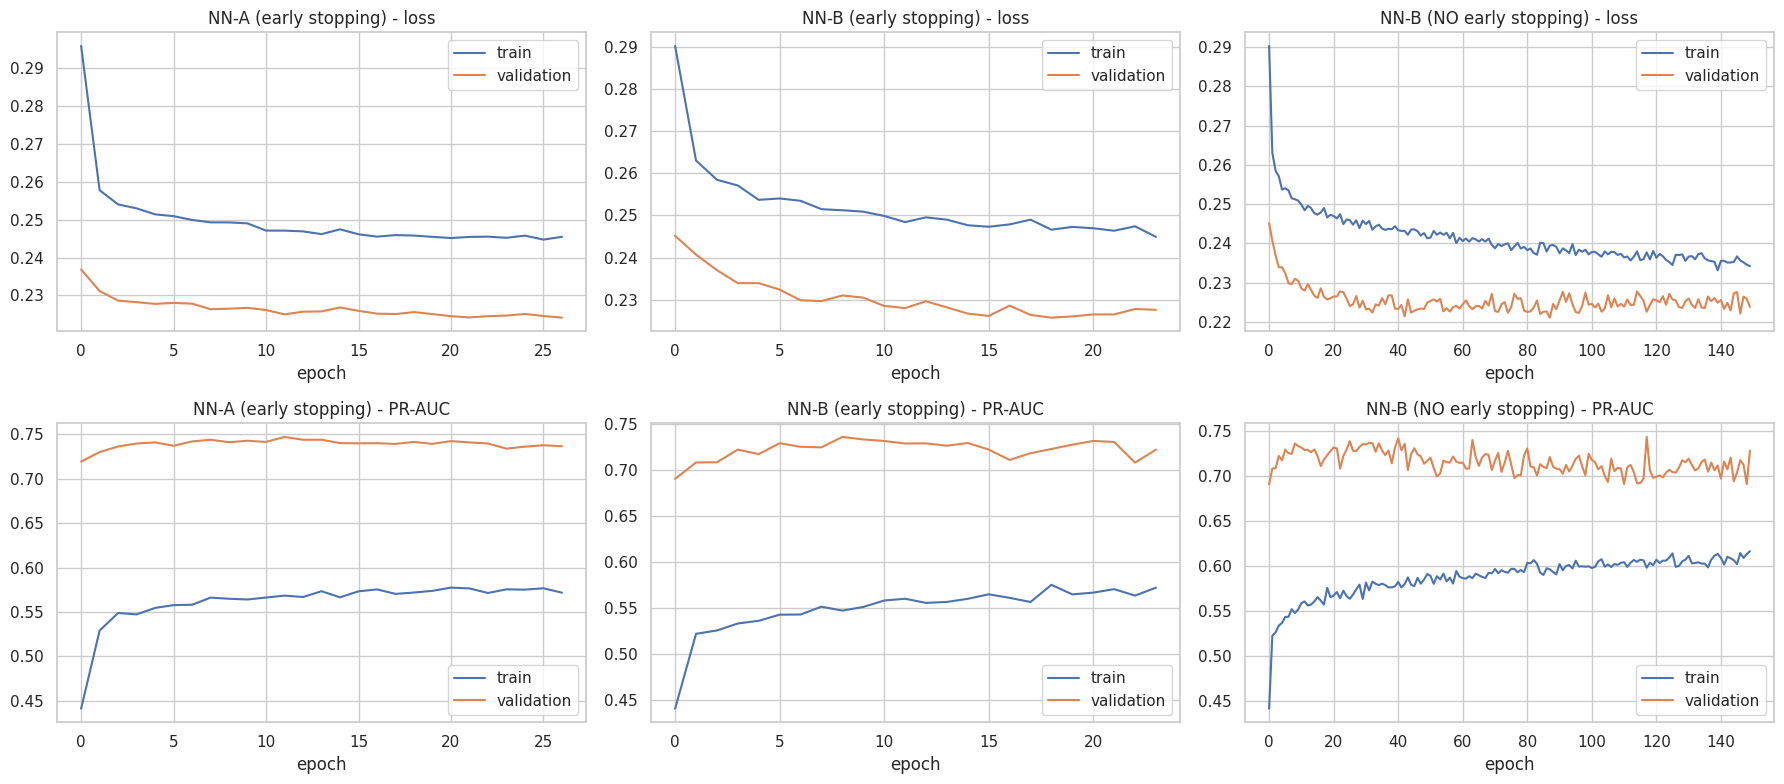

NN-B without early stopping: min val loss at epoch 88 | final train loss 0.2342 | final val loss 0.2238 | min val loss 0.2211


In [59]:
fig, axes = plt.subplots(2, 3, figsize=(18, 8))
for j, (h, title) in enumerate([(hist_a, 'NN-A (early stopping)'), (hist_b, 'NN-B (early stopping)'), (hist_b_noes, 'NN-B (NO early stopping)')]):
    axes[0, j].plot(h.history['loss'], label='train'); axes[0, j].plot(h.history['val_loss'], label='validation')
    axes[0, j].set_title(f'{title} - loss'); axes[0, j].set_xlabel('epoch'); axes[0, j].legend()
    axes[1, j].plot(h.history['pr_auc'], label='train'); axes[1, j].plot(h.history['val_pr_auc'], label='validation')
    axes[1, j].set_title(f'{title} - PR-AUC'); axes[1, j].set_xlabel('epoch'); axes[1, j].legend()
plt.tight_layout(); plt.show()
print('NN-B without early stopping: min val loss at epoch', int(np.argmin(hist_b_noes.history['val_loss'])) + 1,
      '| final train loss', round(hist_b_noes.history['loss'][-1], 4), '| final val loss', round(hist_b_noes.history['val_loss'][-1], 4),
      '| min val loss', round(min(hist_b_noes.history['val_loss']), 4))


**Neural-network results and training curves.**
* **NN-A (1×32):** early stopping restored epoch 12 (training ran 27 epochs). Validation PR-AUC **0.748**, the highest of all attempts.
* **NN-B (64–32):** best epoch 9 of 24; validation PR-AUC 0.737. The deeper network does not help.
* **NN-B without early stopping (150 epochs):** with 22,782 training rows the network does **not** overfit within 150 epochs: training loss falls slowly (to 0.234) and validation loss stays low (minimum 0.221 at epoch 88, 0.224 at the end). Validation PR-AUC ends at 0.731, slightly below the early-stopped networks.

**What this means for early stopping:** with 22,782 training rows the network shows no overfitting within 150 epochs; the large training set acts as a regulariser. Early stopping is kept because it reaches equal or better validation performance in about 1/5 of the epochs, and because restoring the best weights protects against ending on a noisy low epoch.

The training curves lie *below* the validation curves for the same reason as for logistic regression: training PR-AUC is measured on 1950–2019 (with dropout active), which is a harder prediction problem than 2020–2021.


### 9.8 Model selection on validation (test still unseen)

**What:** compare all attempts on validation, check whether differences are larger than the noise (race bootstrap), and pick **one** model for ablation, explanation and inference.
**Rule (fixed in advance):** the highest validation PR-AUC among learned models. If its advantage over the baseline is not significant, we say so.

In [60]:
val_table = pd.DataFrame({n: metrics_at(y_va, r['p_va'], r['thr']) for n, r in RESULTS.items()}).T
val_table['threshold'] = [r['thr'] for r in RESULTS.values()]
val_table['settings'] = [r['info'] for r in RESULTS.values()]
val_table = val_table.sort_values('PR-AUC', ascending=False)
learned = [n for n in val_table.index if not n.startswith('R0')]
SELECTED = learned[0]
print('Selected model (highest validation PR-AUC):', SELECTED)
for other in ['A1: LogReg baseline (C=1)', 'R0: grid-order rule (no learning)']:
    if other != SELECTED:
        lo, hi = race_bootstrap_diff(y_va, RESULTS[SELECTED]['p_va'], RESULTS[other]['p_va'], val_df.raceId)
        print(f'  PR-AUC difference vs {other}: 95% CI [{lo:+.4f}, {hi:+.4f}]')
val_table.round(4)

Selected model (highest validation PR-AUC): A7: NN-A 1x32 (early stopping)


  PR-AUC difference vs A1: LogReg baseline (C=1): 95% CI [-0.0095, +0.0611]


  PR-AUC difference vs R0: grid-order rule (no learning): 95% CI [+0.0635, +0.1508]


,ROC-AUC,PR-AUC,F1,Precision,Recall,Accuracy,threshold,settings
A7: NN-A 1x32 (early stopping),0.9286,0.7477,0.7012,0.6567,0.7521,0.9038,0.2800,"1 hidden: 32 relu, dropout .2, epochs run=27"
A8: NN-B 64-32 (early stopping),0.9279,0.7372,0.7041,0.6267,0.8034,0.8987,0.2300,"2 hidden: 64-32 relu, dropout .3, epochs run=24"
A9: NN-B 64-32 (NO early stopping),0.9311,0.7310,0.6957,0.6471,0.7521,0.9013,0.2700,"150 epochs fixed, epochs run=150"
A4: RandomForest tuned,0.9286,0.7307,0.6980,0.6449,0.7607,0.9013,0.2800,"{'max_depth': 10, 'min_samples_leaf': 50, 'max..."
A2: LogReg tuned,0.9257,0.7215,0.6917,0.6748,0.7094,0.9051,0.7400,"C=0.1, class_weight=balanced"
A1: LogReg baseline (C=1),0.9260,0.7206,0.6984,0.6519,0.7521,0.9026,0.2500,C=1
A5: GradientBoosting default,0.9243,0.6993,0.7045,0.6692,0.7436,0.9064,0.2500,sklearn defaults
A6: GradientBoosting tuned,0.9249,0.6990,0.7000,0.6829,0.7179,0.9077,0.2800,"{'learning_rate': np.float64(0.03), 'max_leaf_..."
A3: RandomForest default,0.9188,0.6532,0.6939,0.6641,0.7265,0.9038,0.3400,"n=300, depth=None"
R0: grid-order rule (no learning),0.9095,0.6386,0.6923,0.6923,0.6923,0.9077,0.3333,score = 1/grid


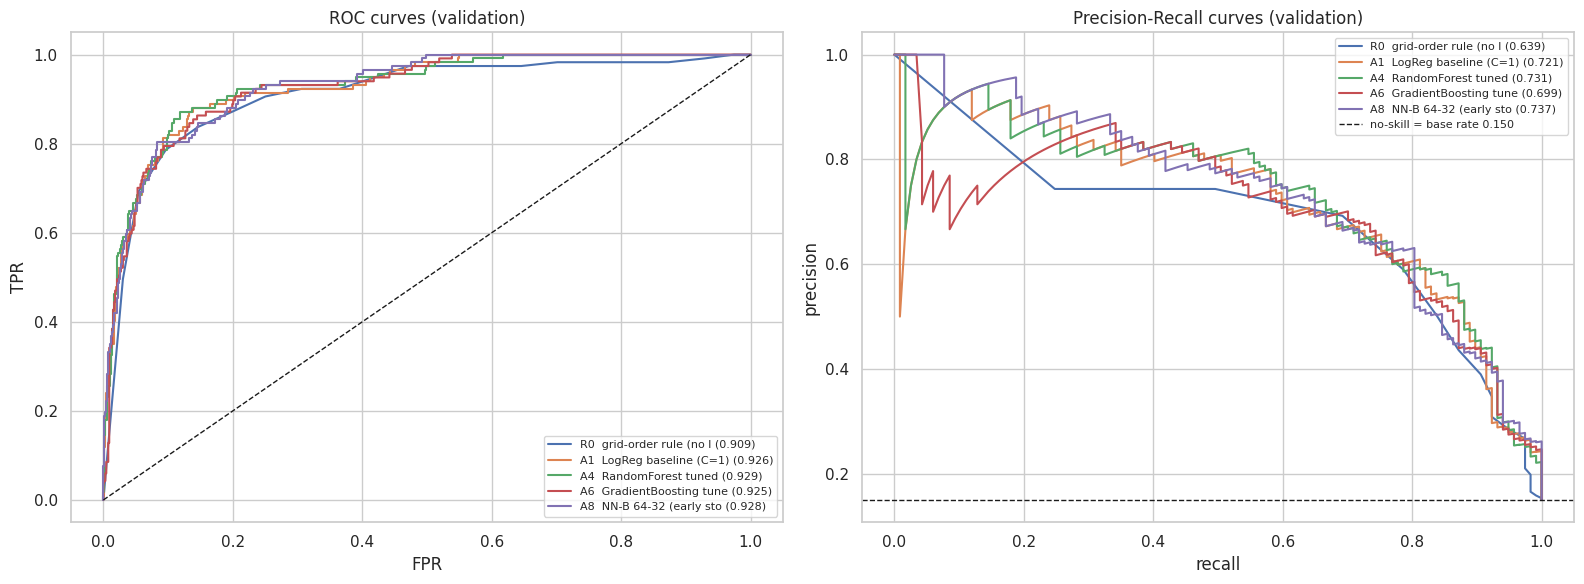

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
show = ['R0: grid-order rule (no learning)', 'A1: LogReg baseline (C=1)', 'A4: RandomForest tuned',
        'A6: GradientBoosting tuned', 'A8: NN-B 64-32 (early stopping)']
for n in show:
    p = RESULTS[n]['p_va']
    fpr, tpr, _ = roc_curve(y_va, p); prec, rec, _ = precision_recall_curve(y_va, p)
    axes[0].plot(fpr, tpr, label=f"{n.split(':')[0]} {n.split(':')[1][:22]} ({roc_auc_score(y_va, p):.3f})")
    axes[1].plot(rec, prec, label=f"{n.split(':')[0]} {n.split(':')[1][:22]} ({average_precision_score(y_va, p):.3f})")
axes[0].plot([0, 1], [0, 1], 'k--', lw=1); axes[0].set_title('ROC curves (validation)'); axes[0].set_xlabel('FPR'); axes[0].set_ylabel('TPR')
axes[1].axhline(y_va.mean(), c='k', ls='--', lw=1, label=f'no-skill = base rate {y_va.mean():.3f}')
axes[1].set_title('Precision-Recall curves (validation)'); axes[1].set_xlabel('recall'); axes[1].set_ylabel('precision')
for a in axes: a.legend(fontsize=8)
plt.tight_layout(); plt.show()


**Selection.** By the rule fixed in advance, **A7: NN-A (1×32, early stopping)** is selected (validation PR-AUC 0.748).

**But the advantage is not significant.** Its PR-AUC difference to the logistic-regression baseline has a 95% race-bootstrap range of **[−0.010, +0.061]**: the learned models between 0.72 and 0.75 cannot be told apart on two validation seasons. Only the improvement over the grid rule is clearly real (range [+0.064, +0.151]).

**What the curves show:** all learned models are above the grid rule along most of the precision–recall curve, especially at low recall (the most confident podium calls), while their ROC curves are almost indistinguishable, again showing why ROC-AUC is not a useful selector here.


### 9.9 Decision-rule experiment: global threshold vs "top-3 per race"

**Hypothesis:** every race has exactly 3 podium places, and that number is known before the race. Instead of one global probability threshold, the companion could flag the **3 drivers with the highest predicted probability in each race**. This uses only pre-race information (the entry list). Does it give a better F1 than the validation-tuned threshold? The decision is made on **validation** only.

In [62]:
def top3_rule(df_part, p):
    r = pd.Series(p, index=df_part.index).groupby(df_part.raceId.values).rank(ascending=False, method='first')
    return (r.values <= 3).astype(int)
p_sel_va = RESULTS[SELECTED]['p_va']
yhat_thr = (p_sel_va >= RESULTS[SELECTED]['thr']).astype(int); yhat_top3 = top3_rule(val_df, p_sel_va)
rule_cmp = pd.DataFrame({
    'global threshold (val-tuned)': {'F1': f1_score(y_va, yhat_thr), 'Precision': precision_score(y_va, yhat_thr), 'Recall': recall_score(y_va, yhat_thr), 'predicted podiums': int(yhat_thr.sum())},
    'top-3 per race': {'F1': f1_score(y_va, yhat_top3), 'Precision': precision_score(y_va, yhat_top3), 'Recall': recall_score(y_va, yhat_top3), 'predicted podiums': int(yhat_top3.sum())}}).T
print('Selected model:', SELECTED, '| real podiums in validation:', int(y_va.sum()))
rule_cmp.round(4)

Selected model: A7: NN-A 1x32 (early stopping) | real podiums in validation: 117


,F1,Precision,Recall,predicted podiums
global threshold (val-tuned),0.7012,0.6567,0.7521,134.0
top-3 per race,0.6838,0.6838,0.6838,117.0



**Result:** on validation, the global threshold (0.28) gives F1 **0.701** (precision 0.657, recall 0.752, 134 podium calls) while "top 3 per race" gives F1 0.684 (precision = recall = 0.684, exactly 117 calls). The global threshold is slightly better on validation, so it stays the main decision rule. The top-3 rule remains attractive for a user-facing companion, because it always names exactly three drivers per race; we report its test F1 as well.


### 9.10 Final evaluation on the unseen test set (2022–2024)

**Only now** is the test set used. Every model keeps the hyperparameters and threshold chosen on validation. Nothing below feeds back into any choice.

In [63]:
rows = []
for n, r in RESULTS.items():
    p_te = grid_score(test_df) if n.startswith('R0') else r['model'].predict_proba(X_te)[:, 1]
    RESULTS[n]['p_te'] = p_te
    for split_name, y, p in [('train', y_tr, r['p_tr']), ('validation', y_va, r['p_va']), ('test', y_te, p_te)]:
        rows.append({'model': n, 'split': split_name, **metrics_at(y, p, r['thr'])})
comparison = pd.DataFrame(rows).pivot(index='model', columns='split', values=['PR-AUC', 'ROC-AUC', 'F1', 'Precision', 'Recall'])
comparison = comparison.reindex(columns=['train', 'validation', 'test'], level=1).sort_values(('PR-AUC', 'validation'), ascending=False)
if SELECTED != 'A1: LogReg baseline (C=1)':
    lo, hi = race_bootstrap_diff(y_te, RESULTS[SELECTED]['p_te'], RESULTS['A1: LogReg baseline (C=1)']['p_te'], test_df.raceId)
    print(f'Test PR-AUC difference, {SELECTED} minus baseline LogReg: 95% CI [{lo:+.4f}, {hi:+.4f}]')
lo, hi = race_bootstrap_diff(y_te, RESULTS[SELECTED]['p_te'], RESULTS['R0: grid-order rule (no learning)']['p_te'], test_df.raceId)
print(f'Test PR-AUC difference, {SELECTED} minus grid-order rule: 95% CI [{lo:+.4f}, {hi:+.4f}]')
print('Test top-3-per-race F1 of the selected model:', round(f1_score(y_te, top3_rule(test_df, RESULTS[SELECTED]['p_te'])), 4))
comparison.round(3)

Test PR-AUC difference, A7: NN-A 1x32 (early stopping) minus baseline LogReg: 95% CI [-0.0422, -0.0023]


Test PR-AUC difference, A7: NN-A 1x32 (early stopping) minus grid-order rule: 95% CI [-0.0070, +0.0935]
Test top-3-per-race F1 of the selected model: 0.6176


PR-AUC                   ROC-AUC                       F1                   Precision                   Recall                  
split                               train validation   test   train validation   test  train validation   test     train validation   test  train validation   test
model                                                                                                                                                              
A7: NN-A 1x32 (early stopping)      0.586      0.748  0.695   0.906      0.929  0.935  0.588      0.701  0.652     0.488      0.657  0.553  0.738      0.752  0.794
A8: NN-B 64-32 (early stopping)     0.581      0.737  0.692   0.907      0.928  0.934  0.581      0.704  0.656     0.457      0.627  0.550  0.797      0.803  0.814
A9: NN-B 64-32 (NO early stopping)  0.659      0.731  0.687   0.923      0.931  0.933  0.618      0.696  0.651     0.519      0.647  0.584  0.762      0.752  0.735
A4: RandomForest tuned              0.641      0.731  0.728   0.923      0.929  0.942  0.611      0.698  0.679     0.519      0.645  0.582  0.742      0.761  0.814
A2: LogReg tuned                    0.564      0.722  0.708   0.902      0.926  0.936  0.581      0.692  0.670     0.515      0.675  0.611  0.666      0.709  0.740
A1: LogReg baseline (C=1)           0.570      0.721  0.716   0.902      0.926  0.936  0.583      0.698  0.664     0.485      0.652  0.548  0.732      0.752  0.843
A5: GradientBoosting default        0.678      0.699  0.722   0.937      0.924  0.936  0.640      0.704  0.676     0.526      0.669  0.586  0.819      0.744  0.799
A6: GradientBoosting tuned          0.713      0.699  0.719   0.944      0.925  0.938  0.661      0.700  0.670     0.558      0.683  0.598  0.811      0.718  0.760
A3: RandomForest default            1.000      0.653  0.712   1.000      0.919  0.934  0.999      0.694  0.659     0.998      0.664  0.588  1.000      0.726  0.750
R0: grid-order rule (no learning)   0.495      0.639  0.647   0.884      0.909  0.914  0.542      0.692  0.649     0.541      0.692  0.650  0.543      0.692  0.647

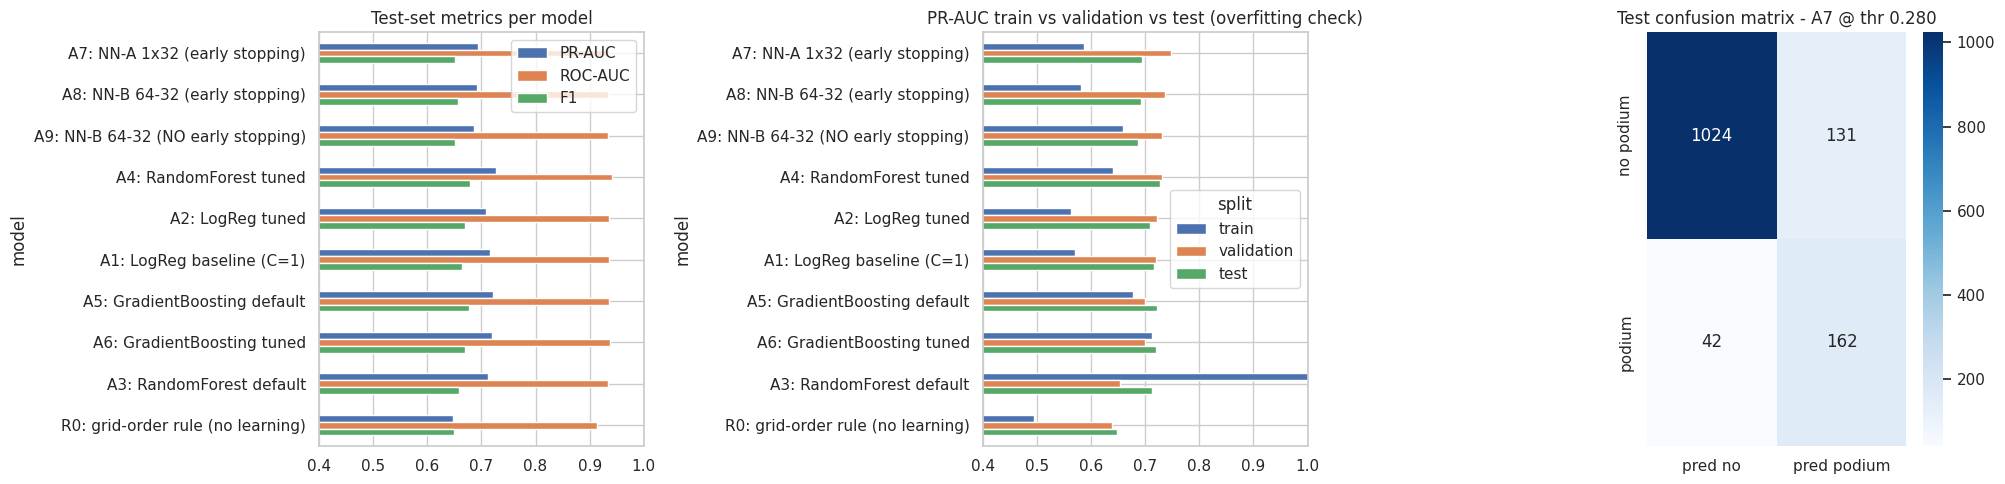

Confusion matrix (rows = actual no/yes, cols = predicted no/yes): [[1024, 131], [42, 162]]


In [64]:
fig, axes = plt.subplots(1, 3, figsize=(20, 5))
test_tab = comparison.xs('test', axis=1, level=1)[['PR-AUC', 'ROC-AUC', 'F1']].loc[comparison.index]
test_tab.plot.barh(ax=axes[0]); axes[0].set_xlim(0.4, 1); axes[0].set_title('Test-set metrics per model'); axes[0].invert_yaxis()
pr = comparison['PR-AUC'][['train', 'validation', 'test']]
pr.plot.barh(ax=axes[1]); axes[1].set_xlim(0.4, 1.0); axes[1].set_title('PR-AUC train vs validation vs test (overfitting check)'); axes[1].invert_yaxis()
cm = confusion_matrix(y_te, (RESULTS[SELECTED]['p_te'] >= RESULTS[SELECTED]['thr']).astype(int))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[2], xticklabels=['pred no', 'pred podium'], yticklabels=['no podium', 'podium'])
axes[2].set_title(f'Test confusion matrix - {SELECTED.split(":")[0]} @ thr {RESULTS[SELECTED]["thr"]:.3f}')
plt.tight_layout(); plt.show()
print('Confusion matrix (rows = actual no/yes, cols = predicted no/yes):', cm.tolist())


**Final test results (2022–2024, never used before).**

| | PR-AUC | ROC-AUC | F1 | Precision | Recall |
|---|---|---|---|---|---|
| **Selected: NN-A** | **0.695** | 0.935 | 0.652 | 0.553 | 0.794 |
| Baseline LogReg (C=1) | 0.716 | 0.936 | 0.664 | 0.548 | 0.843 |
| Tuned random forest | 0.728 | 0.942 | 0.679 | 0.582 | 0.814 |
| Tuned gradient boosting | 0.719 | 0.938 | 0.670 | 0.598 | 0.760 |
| Grid-order rule | 0.647 | 0.914 | 0.649 | 0.650 | 0.647 |

* **The selected model generalises, but less well than the simpler models.** NN-A drops from 0.748 (validation) to 0.695 (test). The baseline logistic regression is significantly better on test: PR-AUC difference NN-A − LogReg range **[−0.042, −0.002]**. The validation "win" of the network was noise on a 39-race validation set. We report this rather than re-selecting, because choosing the model after looking at the test set would turn the test set into a second validation set.
* **Against the grid rule**, NN-A is better by ~0.05 PR-AUC, but the range [−0.007, +0.094] includes 0. The tuned forest gains the most (+0.08).
* **Overfitting check:** the untuned forest (train PR-AUC 1.00) is the only clearly overfit model. The other models score *lower* on train than on validation/test, because the training seasons (1950–2019) include eras that are much harder to predict.
* **Confusion matrix (NN-A, threshold 0.28):** 162 of 204 podiums found (recall 79.4%), 131 false alarms, 42 missed podiums. The top-3-per-race rule gives a test F1 of 0.618.

**Practical recommendation:** for deployment we would prefer logistic regression (equal or better on every split, cheaper, interpretable) or the tuned random forest (best test PR-AUC and ROC-AUC). The remaining sections analyse the model the protocol selected (NN-A) to stay faithful to the pre-registered rule; §13 discusses this.


---
## 10. Feature-group ablation

**What:** remove **one feature group at a time** (§5.2 groups), refit the preprocessing on the remaining columns (train only), retrain the **selected model with exactly the same hyperparameters**, and measure validation performance. Everything else is held constant: same rows, same split, same threshold policy.

**Why:** §7 justified each group *before* training (EDA, correlations). Ablation measures each group's contribution *after* training, inside the chosen model.

**How to read it:** a large drop means the model has **no substitute** for that group. A drop near 0 means either the group is not useful **or** another group carries the same information. §7.3 showed strong redundancy between standings, driver form and constructor form (all measure season strength), so we also remove **those three groups together**. Ablation measures *predictive contribution*, not causation.

**Which split:** validation, the set used for decisions. The test set stays reserved for the single final evaluation in §9.10.

In [65]:
from sklearn.base import clone
def fit_like_selected(cols):
    # Refit preprocessing on `cols` (train only) and retrain the selected model family with the selected settings.
    tf_, _, _ = final_prep_fit(train_df, cols)
    Xa, Xb = tf_(train_df), tf_(val_df)
    if SELECTED.startswith(('A7', 'A8', 'A9')):
        hidden, drop = NN_CONFIGS[SELECTED]
        m = build_nn(hidden, drop, n_in=Xa.shape[1])
        fit_nn(m, epochs=150 if SELECTED.startswith('A9') else 200, early=not SELECTED.startswith('A9'), data=(Xa, y_tr, Xb, y_va))
        m = KerasProba(m)
    else:
        m = clone(RESULTS[SELECTED]['model']).fit(Xa, y_tr)
    return m.predict_proba(Xb)[:, 1]

full_p = RESULTS[SELECTED]['p_va']
ablations = {f'− {g}': [f for f in FEATURES if f not in fs] for g, fs in FEATURE_GROUPS.items()}
SEASON_STRENGTH = FEATURE_GROUPS['standings'] + FEATURE_GROUPS['driver_form'] + FEATURE_GROUPS['constructor_form']
ablations['− standings & driver/constructor form (together)'] = [f for f in FEATURES if f not in SEASON_STRENGTH]
abl_rows = [{'model': 'FULL (all groups)', 'n features': len(FEATURES), **metrics_at(y_va, full_p, best_f1_threshold(y_va, full_p)),
             'ΔPR-AUC 95% CI': ''}]
abl_p = {}
for name, cols in ablations.items():
    p = fit_like_selected(cols); abl_p[name] = p
    lo, hi = race_bootstrap_diff(y_va, p, full_p, val_df.raceId)
    abl_rows.append({'model': name, 'n features': len(cols), **metrics_at(y_va, p, best_f1_threshold(y_va, p)),
                     'ΔPR-AUC 95% CI': f'[{lo:+.4f}, {hi:+.4f}]'})
abl = pd.DataFrame(abl_rows).set_index('model')
abl['ΔPR-AUC vs full'] = abl['PR-AUC'] - abl.loc['FULL (all groups)', 'PR-AUC']
abl['ΔROC-AUC vs full'] = abl['ROC-AUC'] - abl.loc['FULL (all groups)', 'ROC-AUC']
print('Ablated model family:', SELECTED)
abl[['n features', 'PR-AUC', 'ΔPR-AUC vs full', 'ΔPR-AUC 95% CI', 'ROC-AUC', 'ΔROC-AUC vs full', 'F1']].round(4)

Ablated model family: A7: NN-A 1x32 (early stopping)


,n features,PR-AUC,ΔPR-AUC vs full,ΔPR-AUC 95% CI,ROC-AUC,ΔROC-AUC vs full,F1
model,,,,,,,
FULL (all groups),17,0.7477,0.0000,,0.9286,0.0000,0.7012
− grid,15,0.6658,-0.0819,"[-0.1189, -0.0457]",0.8943,-0.0343,0.6857
− standings,11,0.7264,-0.0213,"[-0.0534, +0.0186]",0.9270,-0.0016,0.7029
− driver_form,12,0.7310,-0.0167,"[-0.0323, +0.0012]",0.9293,0.0006,0.7004
− constructor_form,14,0.7412,-0.0065,"[-0.0234, +0.0112]",0.9280,-0.0006,0.6971
− context,16,0.7443,-0.0034,"[-0.0149, +0.0115]",0.9287,0.0001,0.6964
− standings & driver/constructor form (together),3,0.6386,-0.1091,"[-0.1508, -0.0635]",0.9095,-0.0192,0.6740


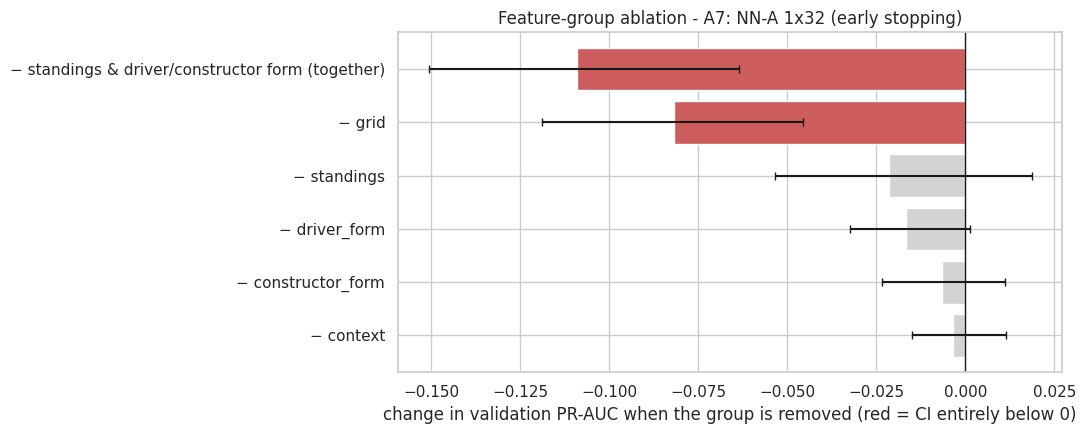

In [66]:
d = abl.drop('FULL (all groups)').sort_values('ΔPR-AUC vs full')
ci = np.array([[float(x) for x in s.strip('[]').split(',')] for s in d['ΔPR-AUC 95% CI']])
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.barh(d.index, d['ΔPR-AUC vs full'], xerr=[d['ΔPR-AUC vs full'] - ci[:, 0], ci[:, 1] - d['ΔPR-AUC vs full']],
        color=np.where(ci[:, 1] < 0, 'indianred', 'lightgray'), capsize=3)
ax.axvline(0, c='k', lw=1); ax.invert_yaxis()
ax.set_xlabel('change in validation PR-AUC when the group is removed (red = CI entirely below 0)')
ax.set_title(f'Feature-group ablation - {SELECTED}')
plt.tight_layout(); plt.show()


**What the output shows (validation, NN-A retrained without each group):**
* **Grid is the only group the model cannot do without:** removing it drops PR-AUC **0.748 → 0.666 (−0.082, range [−0.119, −0.046])** and ROC-AUC by 0.034. No other feature tells the model where the car starts.
* **Removing one season-strength group** (standings, driver form or constructor form) lowers PR-AUC by 0.007–0.021, and all ranges include 0: each can be replaced by the other two (§7.3).
* **Removing all three together** is the largest loss: **0.748 → 0.639 (−0.109, range [−0.151, −0.064])**. Season strength as a whole is essential, even though no single group of it is.
* Removing `context` (field size) changes PR-AUC by only −0.003 (not significant).

**Interpretation:** the model needs two kinds of information: where the car starts (grid) and how strong the car/driver is this season (any of standings or form). An ablation drop near zero therefore means "replaceable here", not "useless".


---
## 11. Explainability (XAI)

Following Lab 4: **global** explanations show how the model behaves overall; **local** explanations show why it made one specific prediction. All explanations are of the **selected model** on the **test set** (Lab 4 also explains `X_test`). No decision is made from them, so using the test set here does not leak into model building.

> **Not causal.** An "important" feature is one the **model relies on** to make its predictions. It is *not* evidence that the feature *causes* podiums. For example, a high constructor points share does not make a car faster; it records that the car *was* fast in earlier races, and the model uses that record as a signal. Correlated features (§7.3) can also share or swap importance between them.

### 11.1 Global: permutation importance

**What it does:** shuffle one feature's values across the test rows (breaking its link to the outcome while keeping its distribution), re-predict, and measure how much **PR-AUC drops**. A bigger drop means the model relies on that feature more. It is model-agnostic.
**Implementation detail:** we permute the **raw feature** *before* preprocessing, so the feature and its missing-indicator column move together. We repeat 10 times and report mean ± std. Because correlated features can stand in for each other, we also permute **whole groups**.

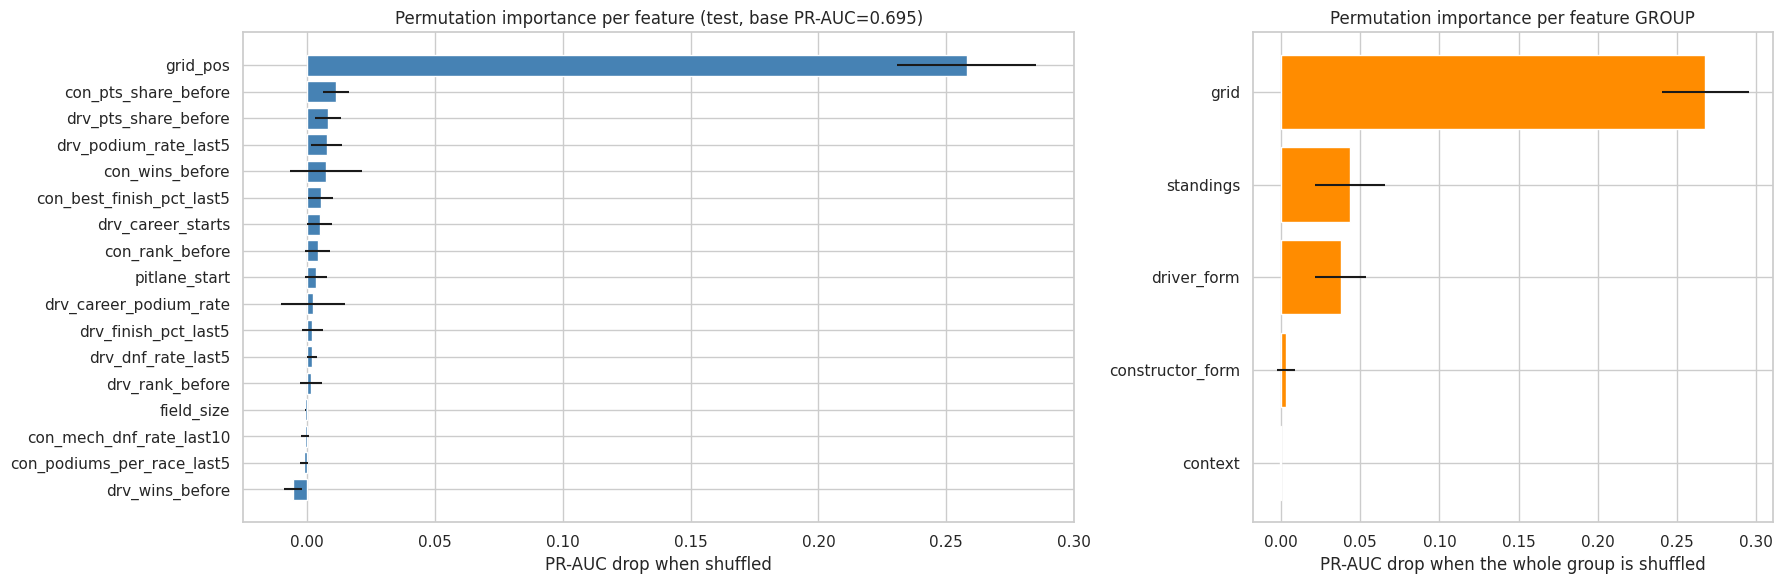

,mean PR-AUC drop,std
grid,0.2680,0.0275
standings,0.0434,0.0222
driver_form,0.0377,0.0160
constructor_form,0.0032,0.0059
context,-0.0008,0.0001


,mean PR-AUC drop,std
grid_pos,0.2580,0.0273
con_pts_share_before,0.0113,0.0052
drv_pts_share_before,0.0081,0.0049
drv_podium_rate_last5,0.0075,0.0060
con_wins_before,0.0072,0.0140
con_best_finish_pct_last5,0.0052,0.0048
drv_career_starts,0.0049,0.0048
con_rank_before,0.0041,0.0050
pitlane_start,0.0034,0.0043
drv_career_podium_rate,0.0024,0.0126


In [67]:
SEL_MODEL, SEL_THR = RESULTS[SELECTED]['model'], RESULTS[SELECTED]['thr']
predict_fn = lambda df_: SEL_MODEL.predict_proba(transform(df_))[:, 1]
base_ap = average_precision_score(y_te, predict_fn(test_df))

def perm_importance(cols_list, n_repeats=10, seed=SEED):
    rng = np.random.default_rng(seed); out = {}
    for name, cols in cols_list.items():
        drops = []
        for _ in range(n_repeats):
            d = test_df.copy(); perm = rng.permutation(len(d))
            d[cols] = d[cols].values[perm]                      # permute jointly (same shuffle for the group)
            drops.append(base_ap - average_precision_score(y_te, predict_fn(d)))
        out[name] = (np.mean(drops), np.std(drops))
    return pd.DataFrame(out, index=['mean PR-AUC drop', 'std']).T.sort_values('mean PR-AUC drop', ascending=False)

pi_feat = perm_importance({f: [f] for f in FEATURES})
pi_group = perm_importance(FEATURE_GROUPS)
fig, axes = plt.subplots(1, 2, figsize=(18, 6), gridspec_kw={'width_ratios': [1.6, 1]})
axes[0].barh(pi_feat.index, pi_feat['mean PR-AUC drop'], xerr=pi_feat['std'], color='steelblue'); axes[0].invert_yaxis()
axes[0].set_title(f'Permutation importance per feature (test, base PR-AUC={base_ap:.3f})'); axes[0].set_xlabel('PR-AUC drop when shuffled')
axes[1].barh(pi_group.index, pi_group['mean PR-AUC drop'], xerr=pi_group['std'], color='darkorange'); axes[1].invert_yaxis()
axes[1].set_title('Permutation importance per feature GROUP'); axes[1].set_xlabel('PR-AUC drop when the whole group is shuffled')
plt.tight_layout(); plt.show()
display(pi_group.round(4)); pi_feat.head(10).round(4)


**What the output shows (test set, base PR-AUC 0.695):**
* **By group:** shuffling **grid** costs 0.268 PR-AUC, **standings** 0.043, driver form 0.038; constructor form (0.003) and context (−0.001) are within noise.
* **By feature:** `grid_pos` (0.258) dominates by far; every other single feature costs 0.011 or less (constructor points share 0.011, driver points share 0.008).

**Why single features look so small:** shuffling one standings or form feature leaves its correlated partners intact, so the model loses little. Shuffling the whole group removes the information, which is why standings and driver form matter as groups although no single feature of them does. This agrees with the ablation: grid is irreplaceable, season strength matters as a block.


### 11.2 Global: SHAP

**What SHAP does (Lab 4's "cash prize" analogy):** the prediction is the prize and the features are the players. SHAP splits the difference between this row's prediction and the **baseline** (average) prediction fairly among the features, by considering every combination of features with and without each one. Every row gets one SHAP value per feature; averaging their absolute values gives a global ranking.

**Explainer choice by model type** (Lab 4: "there are more optimized versions of SHAP depending on the use case"): `TreeExplainer` for tree ensembles, `LinearExplainer` for logistic regression, and the model-agnostic `KernelExplainer` for the neural network. SHAP values are in the model's **output space**: log-odds for logistic regression and gradient boosting, probability for random forest and the network.

**Beeswarm plot:** one dot per test row per feature. x = SHAP value (right pushes towards podium), colour = feature value (red high, blue low).

Explainer: KernelExplainer | rows explained: 300 | output space baseline: 0.1209


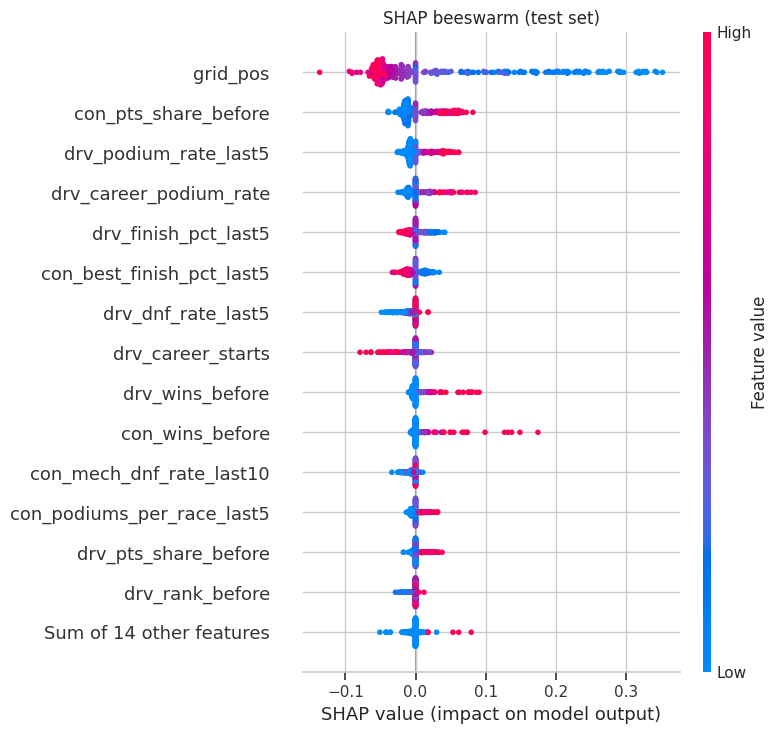

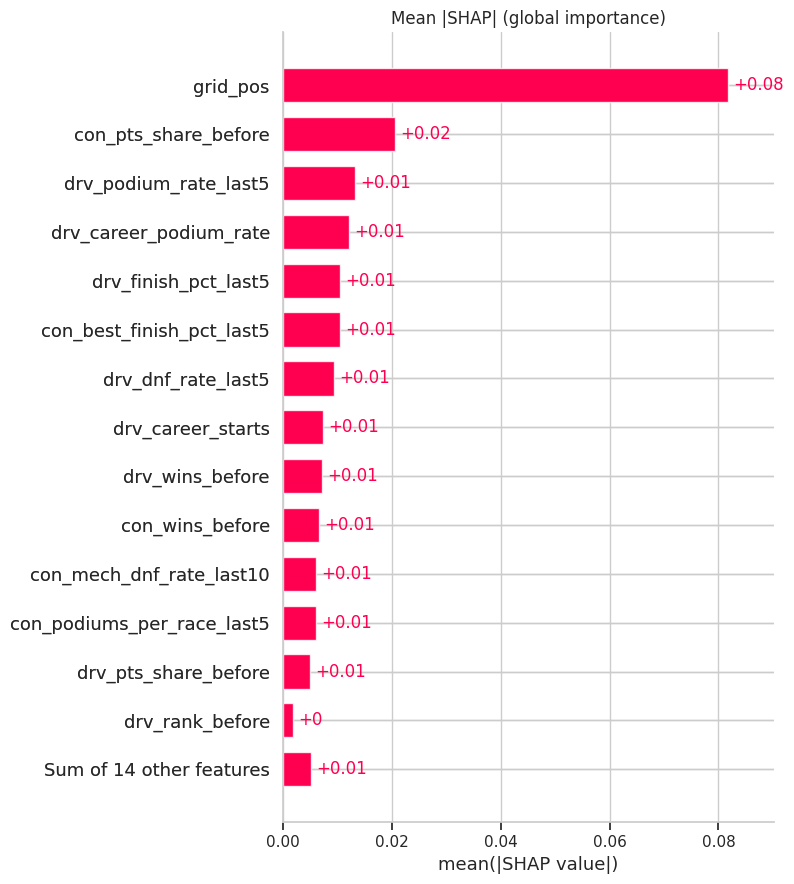

grid_pos                     0.0818
con_pts_share_before         0.0206
drv_podium_rate_last5        0.0132
drv_career_podium_rate       0.0121
drv_finish_pct_last5         0.0105
con_best_finish_pct_last5    0.0104
drv_dnf_rate_last5           0.0094
drv_career_starts            0.0073
drv_wins_before              0.0072
con_wins_before              0.0066
dtype: float64

In [68]:
X_te_df = pd.DataFrame(X_te, columns=FEAT_OUT)
if SELECTED.startswith(('A3', 'A4', 'A5', 'A6')):
    explainer = shap.TreeExplainer(SEL_MODEL); shap_rows = X_te_df
    sv = explainer(shap_rows)
elif SELECTED.startswith(('A1', 'A2')):
    explainer = shap.LinearExplainer(SEL_MODEL, pd.DataFrame(X_tr, columns=FEAT_OUT)); shap_rows = X_te_df
    sv = explainer(shap_rows)
else:
    bg = shap.kmeans(X_tr, 30)
    explainer = shap.KernelExplainer(lambda a: SEL_MODEL.predict_proba(a)[:, 1], bg)
    shap_rows = X_te_df.sample(300, random_state=SEED)
    sv = shap.Explanation(explainer.shap_values(shap_rows, nsamples=300, silent=True),
                          base_values=np.full(len(shap_rows), float(explainer.expected_value)),
                          data=shap_rows.values, feature_names=FEAT_OUT)
if sv.values.ndim == 3: sv = sv[..., 1]            # random forest returns both classes -> keep "podium"
print('Explainer:', type(explainer).__name__, '| rows explained:', sv.values.shape[0], '| output space baseline:', np.round(np.ravel(sv.base_values)[0], 4))
plt.figure(); shap.plots.beeswarm(sv, max_display=15, show=False); plt.title('SHAP beeswarm (test set)'); plt.tight_layout(); plt.show()
plt.figure(); shap.plots.bar(sv, max_display=15, show=False); plt.title('Mean |SHAP| (global importance)'); plt.tight_layout(); plt.show()
mean_abs = pd.Series(np.abs(sv.values).mean(0), index=FEAT_OUT).sort_values(ascending=False)
mean_abs.head(10).round(4)


**What the output shows (KernelExplainer, 300 test rows, probability space, baseline 0.121 ≈ the podium base rate):**
* **`grid_pos` dominates** (mean |SHAP| 0.082), about four times the next feature. Then constructor points share (0.021), recent podium rate (0.013), career podium rate (0.012) and several form features (~0.010 each).
* **Direction (beeswarm):** low (blue) grid positions push strongly towards a podium, high values push away; high points shares, podium rates and wins push towards a podium. Every direction matches the EDA in §7.2, so the model has learned plausible relationships, not artefacts.
* The long right tail for `grid_pos` and the short left tail show the non-linearity: a front-row start adds a lot, while starting 12th vs 18th makes almost no difference (both already near zero).

**Reminder:** this describes what the model uses, not what causes podiums (see the note at the top of §11).


### 11.3 Local: one prediction explained with SHAP (waterfall) and LIME

**Which row and why:** an interesting real case from the test seasons, chosen programmatically (not hand-picked): the **true podium finisher who started furthest back but was still flagged by the model** (probability ≥ threshold). This shows what made the model see a podium chance beyond the grid order. As a contrast, we also explain the **most confident false alarm** (highest probability among drivers who did not podium).

**Waterfall plot:** starts at the baseline E[f(x)] and adds each feature's SHAP value until it reaches this row's prediction f(x).
**LIME (Lab 4):** perturbs this one row many times, asks the model for predictions on the perturbed copies, and fits a small **linear surrogate** that mimics the model *around this row only*. Its weights are a local approximation, so they need not match SHAP exactly, but broad agreement increases trust in the explanation.

Row A (flagged podium from furthest back): 2022 Belgian Grand Prix (round 14) - Max Verstappen: grid 14, predicted p=0.362, actual podium=1
Row B (most confident false alarm): 2022 São Paulo Grand Prix (round 21) - Max Verstappen: grid 3, predicted p=0.863, actual podium=0


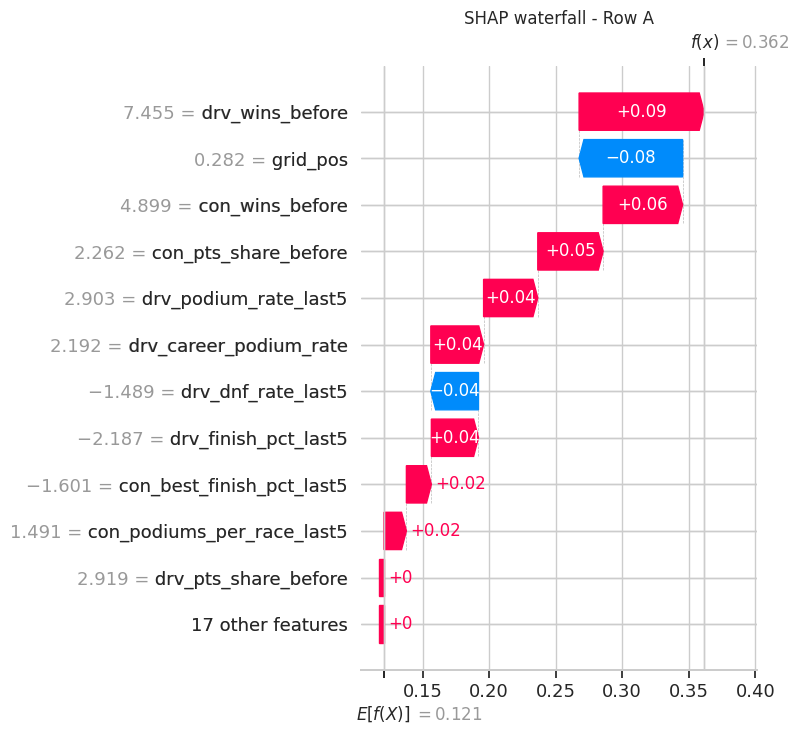

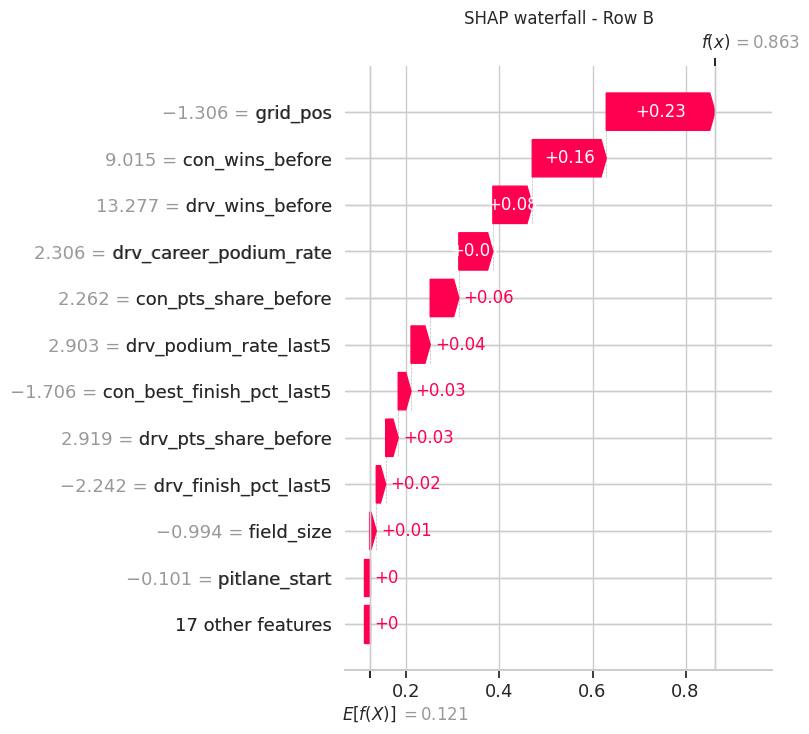

Row A                           Row B        
                  feature    SHAP                 feature    SHAP
0         drv_wins_before  0.0939                grid_pos  0.2338
1                grid_pos -0.0778         con_wins_before  0.1591
2         con_wins_before  0.0597         drv_wins_before  0.0846
3    con_pts_share_before  0.0491  drv_career_podium_rate  0.0732
4   drv_podium_rate_last5  0.0407    con_pts_share_before  0.0616
5  drv_career_podium_rate  0.0397   drv_podium_rate_last5  0.0412

In [69]:
p_te_sel = RESULTS[SELECTED]['p_te']
info = test_df[['raceId', 'driverId', 'year', 'round', 'grid_pos']].copy()
info['p'] = p_te_sel; info['podium'] = y_te
info = info.merge(clean['drivers'][['driverId', 'forename', 'surname']].astype({'driverId': 'int64'}), on='driverId', how='left') \
           .merge(clean['races'][['raceId', 'name']].astype({'raceId': 'int64'}), on='raceId', how='left')
info.index = test_df.index
cand = info[(info.podium == 1) & (info.p >= SEL_THR)]
row_A = cand.sort_values(['grid_pos', 'p'], ascending=[False, False]).index[0] if len(cand) else info.p.idxmax()
row_B = info[info.podium == 0].p.idxmax()
for tag_, r in [('A (flagged podium from furthest back)', row_A), ('B (most confident false alarm)', row_B)]:
    x = info.loc[r]
    print(f"Row {tag_}: {x.year} {x['name']} (round {x['round']}) - {x.forename} {x.surname}: grid {x.grid_pos:.0f}, "
          f"predicted p={x.p:.3f}, actual podium={x.podium}")

pos = {r: list(test_df.index).index(r) for r in (row_A, row_B)}
def local_expl(r):
    if SELECTED.startswith(('A7', 'A8', 'A9')):
        xr = X_te_df.iloc[[pos[r]]]
        return shap.Explanation(explainer.shap_values(xr, nsamples=500, silent=True)[0], base_values=float(explainer.expected_value),
                                data=xr.values[0], feature_names=FEAT_OUT)
    e = explainer(X_te_df.iloc[[pos[r]]])
    return (e[..., 1] if e.values.ndim == 3 else e)[0]
local_tables = {}
for r, title in [(row_A, 'Row A'), (row_B, 'Row B')]:
    e = local_expl(r)
    local_tables[title] = pd.Series(e.values, index=FEAT_OUT).sort_values(key=np.abs, ascending=False).head(6).round(4)
    plt.figure(); shap.plots.waterfall(e, max_display=12, show=False); plt.title(f'SHAP waterfall - {title}'); plt.tight_layout(); plt.show()
display(pd.concat({k: v.reset_index().rename(columns={"index": "feature", 0: "SHAP"}) for k, v in local_tables.items()}, axis=1))

LIME local surrogate for Row A | model p = 0.3615 | LIME local prediction = [0.1471] | surrogate R^2 = 0.215


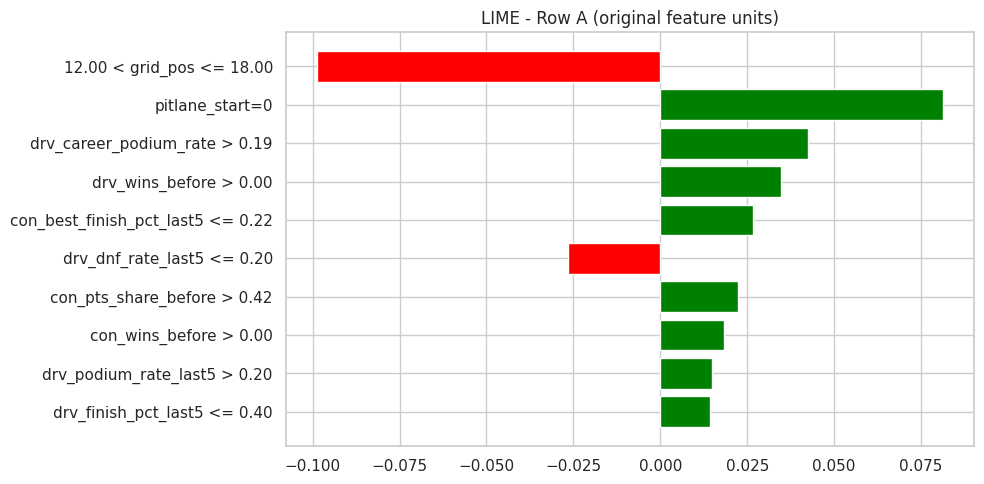

,grid_pos,pitlane_start,drv_pts_share_before,drv_rank_before,drv_wins_before,con_pts_share_before,con_rank_before,con_wins_before,drv_podium_rate_last5,drv_finish_pct_last5,drv_dnf_rate_last5,drv_career_starts,drv_career_podium_rate,con_podiums_per_race_last5,con_best_finish_pct_last5,con_mech_dnf_rate_last10,field_size
Row A value,14.0,0.0,1.0,1.0,8.0,1.0,1.0,9.0,0.8,0.12,0.0,154.0,0.455,1.0,0.07,0.05,20.0


,condition (original units),LIME weight
0,12.00 < grid_pos <= 18.00,-0.098652
1,pitlane_start=0,0.081249
2,drv_career_podium_rate > 0.19,0.042500
3,drv_wins_before > 0.00,0.034727
4,con_best_finish_pct_last5 <= 0.22,0.026757
5,drv_dnf_rate_last5 <= 0.20,-0.026611
6,con_pts_share_before > 0.42,0.022477
7,con_wins_before > 0.00,0.018406
8,drv_podium_rate_last5 > 0.20,0.014784
9,drv_finish_pct_last5 <= 0.40,0.014399


In [70]:
# LIME is run on the ORIGINAL features, with the fitted preprocessing inside the prediction function. Two reasons:
# (1) the explanation is in real units (e.g. "grid_pos <= 3"), not standardised ones;
# (2) LIME perturbs each column independently: on the 33-column matrix it would switch missing-indicator columns on
#     for drivers who have a value, creating impossible rows that dominate the surrogate.
lime_train = train_df[FEATURES].fillna(train_df[FEATURES].median())
predict_raw = lambda A: SEL_MODEL.predict_proba(transform(pd.DataFrame(A, columns=FEATURES)))
lime_explainer = lime.lime_tabular.LimeTabularExplainer(lime_train.values, feature_names=FEATURES, class_names=['no podium', 'podium'],
                                                        categorical_features=[FEATURES.index('pitlane_start')],
                                                        discretize_continuous=True, random_state=SEED, mode='classification')
x_A = test_df.loc[row_A, FEATURES].astype(float).fillna(train_df[FEATURES].median())
lime_exp = lime_explainer.explain_instance(x_A.values, predict_raw, num_features=10, num_samples=3000)
print('LIME local surrogate for Row A | model p =', round(float(p_te_sel[pos[row_A]]), 4),
      '| LIME local prediction =', np.round(lime_exp.local_pred, 4), '| surrogate R^2 =', round(lime_exp.score, 3))
fig = lime_exp.as_pyplot_figure(); fig.set_size_inches(10, 5); plt.title('LIME - Row A (original feature units)'); plt.tight_layout(); plt.show()
display(x_A.round(3).to_frame('Row A value').T)
pd.DataFrame(lime_exp.as_list(), columns=['condition (original units)', 'LIME weight'])


**Row A: Max Verstappen, 2022 Belgian GP. Started P14 (after a grid penalty), predicted p = 0.36, actually finished on the podium.** From P14 the grid rule gives ~3%, yet the model flags him (threshold 0.28). The waterfall shows why:
* **Pushing up:** 8 wins before this race (+0.09), his team's wins (+0.06) and points share (+0.05), his recent podium rate (+0.04) and career podium rate (+0.04). Together they say "this is the strongest car and driver of the season".
* **Pushing down:** the P14 grid slot (−0.08). The model treats starting far back as a real handicap even for a dominant car.
* The prediction is a balance between season strength and starting position, exactly the two kinds of information the ablation (§10) found essential.

**Row B: Max Verstappen, 2022 São Paulo GP. Started P3, predicted p = 0.86, no podium.** Every pre-race signal points to a podium (grid +0.23, team and driver wins +0.24 together, career podium rate +0.07); he finished outside the top three in the race itself. Nothing known at the cutoff could have predicted that, so this false alarm shows the limit of a pre-race model rather than a modelling error.

**LIME (Row A)** agrees with SHAP in direction: its largest negative weight is the grid slot between 12 and 18, and its positive weights are career podium rate, wins before the race, constructor form and points share. However, LIME's local linear fit is poor here (R² = 0.22; its local prediction 0.15 vs the model's 0.36), so its exact weights should not be over-read; only the agreement in *direction* with SHAP adds confidence.


---
## 12. Inference function

**Inputs:** a dictionary with any subset of the 18 pre-race features (§5.2). Every value is something a user can know after the starting grid is set: grid slot, standings before the race, and recent form computed from finished races.
**Steps:** (1) put the values into the training column order; any feature not supplied becomes NaN; (2) apply the **same fitted preprocessing** as training (impute with training medians + missing indicators → standardise with the training mean/std); nothing is refitted at inference time; (3) the selected model returns a podium probability; (4) the decision uses the threshold frozen on validation.
**Output:** probability, yes/no decision, threshold, and the list of features that were **imputed**, so the user can see how much of the prediction rests on filled-in values.
**Missing values:** handled exactly as in training. The imputer fills the training median, and the indicator columns tell the model the value was missing. A key that is not a known feature raises an error instead of being silently ignored.

In [71]:
def predict_podium(record: dict, model=SEL_MODEL, threshold=SEL_THR):
    # Predict the podium probability for one driver-race from pre-race features (missing keys allowed).
    unknown = set(record) - set(FEATURES)
    if unknown: raise KeyError(f'Unknown feature(s): {sorted(unknown)}. Allowed: {FEATURES}')
    row = pd.DataFrame([{f: record.get(f, np.nan) for f in FEATURES}], dtype=float)
    imputed = [f for f in FEATURES if pd.isna(row.at[0, f])]
    p = float(model.predict_proba(transform(row))[:, 1][0])
    return {'podium_probability': round(p, 4), 'predicted_podium': bool(p >= threshold),
            'threshold': round(threshold, 4), 'imputed_by_training_median': imputed}

def record_from_table(race_id, driver_id):
    # Pull the pre-race feature values of an existing row (features only - never the target).
    return model_table.loc[(model_table.raceId == race_id) & (model_table.driverId == driver_id), FEATURES].iloc[0].to_dict()

# --- choose a real, complete record: pole-sitter of the last race in the data (test season, no missing feature) ---
last_race = test_df.loc[test_df.date == test_df.date.max(), 'raceId'].iloc[0]
pole = test_df[(test_df.raceId == last_race) & (test_df.grid_pos == 1)].iloc[0]
rec_complete = record_from_table(pole.raceId, pole.driverId)
who = clean['drivers'].set_index('driverId').loc[int(pole.driverId)]
print('Race:', clean['races'].set_index('raceId').loc[int(last_race), 'name'], int(pole.year), '| driver:', who.forename, who.surname)
print('Complete record has missing values:', any(pd.isna(v) for v in rec_complete.values()))
display(pd.Series(rec_complete).round(3).to_frame('value').T)
out_complete = predict_podium(rec_complete)
print('Prediction (complete record):', out_complete)

Race: Abu Dhabi Grand Prix 2024 | driver: Lando Norris
Complete record has missing values: False


,grid_pos,pitlane_start,drv_pts_share_before,drv_rank_before,drv_wins_before,con_pts_share_before,con_rank_before,con_wins_before,drv_podium_rate_last5,drv_finish_pct_last5,drv_dnf_rate_last5,drv_career_starts,drv_career_podium_rate,con_podiums_per_race_last5,con_best_finish_pct_last5,con_mech_dnf_rate_last10,field_size
value,1.0,0.0,0.814,2.0,3.0,1.0,1.0,5.0,0.2,0.28,0.0,127.0,0.197,0.4,0.21,0.0,20.0


Prediction (complete record): {'podium_probability': 0.6285, 'predicted_podium': True, 'threshold': 0.28, 'imputed_by_training_median': []}


In [72]:
# --- partially-missing record A: standings ranks and recent driver form unknown ---
dropped = ['drv_rank_before', 'con_rank_before', 'drv_podium_rate_last5', 'drv_finish_pct_last5', 'drv_dnf_rate_last5']
print('Partial record A, removed keys:', dropped)
print('Prediction:', predict_podium({k: v for k, v in rec_complete.items() if k not in dropped}))

# --- partially-missing record B: all constructor information unknown ---
dropped_b = ['con_pts_share_before', 'con_rank_before', 'con_wins_before',
             'con_podiums_per_race_last5', 'con_best_finish_pct_last5', 'con_mech_dnf_rate_last10']
print('\nPartial record B, removed keys:', dropped_b)
print('Prediction:', predict_podium({k: v for k, v in rec_complete.items() if k not in dropped_b}))
print('\nOutcome known only AFTER the race (for reference, never an input): podium =', int(pole.podium))

# --- the guard against misspelled / non-pre-race inputs ---
try:
    predict_podium({**rec_complete, 'positionOrder': 1})
except KeyError as e:
    print('\nPassing a post-race field is rejected:', str(e)[:90], '...')

Partial record A, removed keys: ['drv_rank_before', 'con_rank_before', 'drv_podium_rate_last5', 'drv_finish_pct_last5', 'drv_dnf_rate_last5']
Prediction: {'podium_probability': 0.5342, 'predicted_podium': True, 'threshold': 0.28, 'imputed_by_training_median': ['drv_rank_before', 'con_rank_before', 'drv_podium_rate_last5', 'drv_finish_pct_last5', 'drv_dnf_rate_last5']}

Partial record B, removed keys: ['con_pts_share_before', 'con_rank_before', 'con_wins_before', 'con_podiums_per_race_last5', 'con_best_finish_pct_last5', 'con_mech_dnf_rate_last10']


Prediction: {'podium_probability': 0.6841, 'predicted_podium': True, 'threshold': 0.28, 'imputed_by_training_median': ['con_pts_share_before', 'con_rank_before', 'con_wins_before', 'con_podiums_per_race_last5', 'con_best_finish_pct_last5', 'con_mech_dnf_rate_last10']}

Outcome known only AFTER the race (for reference, never an input): podium = 1

Passing a post-race field is rejected: "Unknown feature(s): ['positionOrder']. Allowed: ['grid_pos', 'pitlane_start', 'drv_pts_sh ...



**What the output shows.**
* **Complete record** (Lando Norris, pole position, 2024 Abu Dhabi GP, the last race in the data): probability **0.63 → podium predicted** (threshold 0.28). He did finish on the podium (shown only for reference; it is never an input).
* **Partial record A** (both standings ranks and the three recent-form features removed): probability **0.53**, still a podium call.
* **Partial record B** (all six constructor features removed): probability **0.68**, still a podium call.
* Passing a post-race field (`positionOrder`) raises an error instead of being silently ignored.

**How the missing values were handled:** each missing feature is filled with its **training median** (a "typical" value, e.g. constructor points share 0.11, rank 6) and its missing-indicator column is set to 1, exactly as in training. Because the remaining features overlap with the removed ones (§7.3) and the grid slot (pole) is still known, the prediction stays a podium call in both cases; the probability moves by 0.05–0.10 in either direction because typical values replace the real ones.

**Take-away:** the function reproduces the training pipeline exactly and reports which values were filled, so the user can judge how much a prediction rests on filled-in data.


---
## 13. Selected features, limitations and requirement audit

### 13.1 Final feature set and the evidence behind each group

All 17 features (5 groups) are used by the final model. The table summarises, per group, the evidence gathered *before* training (EDA, §7) and *after* training (ablation §10, permutation importance §11).

In [73]:
group_summary = pd.DataFrame({
    'features': {g: ', '.join(fs) for g, fs in FEATURE_GROUPS.items()},
    'max |Spearman| with podium (train)': {g: round(target_corr[fs].abs().max(), 3) for g, fs in FEATURE_GROUPS.items()},
    'ΔPR-AUC when removed (val, §10)': {g: round(abl.loc[f'− {g}', 'ΔPR-AUC vs full'], 4) for g in FEATURE_GROUPS},
    'permutation PR-AUC drop (test, §11)': {g: round(pi_group.loc[g, 'mean PR-AUC drop'], 4) for g in FEATURE_GROUPS},
})
group_summary

,features,max |Spearman| with podium (train),"ΔPR-AUC when removed (val, §10)","permutation PR-AUC drop (test, §11)"
grid,"grid_pos, pitlane_start",0.452,-0.0819,0.2680
standings,"drv_pts_share_before, drv_rank_before, drv_win...",0.406,-0.0213,0.0434
driver_form,"drv_podium_rate_last5, drv_finish_pct_last5, d...",0.442,-0.0167,0.0377
constructor_form,"con_podiums_per_race_last5, con_best_finish_pc...",0.410,-0.0065,0.0032
context,field_size,0.052,-0.0034,-0.0008



**Reading the table:** every group except `context` has a clear univariate relationship (|ρ| ≥ 0.41; field size 0.05). Inside the final model, grid carries most of the signal (largest permutation drop; the only group whose single removal is significant), standings and driver form add the next largest shares, and constructor form and context add little on their own.

**Why all 17 are still kept:** (1) standings, driver form and constructor form substitute for each other: removing them *together* is the largest loss of all (§10), so the block is essential even though each member looks small alone; (2) the redundancy makes the model robust when some values are missing at inference (§12); (3) `field_size` adjusts for the much larger fields of early seasons in the 1950–2019 training data. `is_home` was already removed after Q2 showed no home advantage.


### 13.2 Limitations


1. **Model selection was not robust to the small validation set.** Two seasons (39 races, 117 podiums) cannot separate models whose PR-AUC differs by a few hundredths. The pre-registered rule picked the neural network, but on the test set the simpler logistic regression is significantly better (§9.10). For a real deployment we would choose the simplest model in the statistical tie, or use rolling-origin validation over several seasons.
2. **Era drift.** Training spans 1950–2019 and the test seasons are a new technical era (2022 ground-effect rules). §7.1.2 found no harm from the old seasons on 2020–2021, but the network's validation-to-test drop (0.748 → 0.695) shows that what works on one era does not fully transfer to the next.
3. **No qualifying pace.** Using the grid instead of qualifying loses almost nothing in *position* information (§7.1.1), but the grid cannot express *how much* faster a car was (the gap to pole in seconds), which only exists from 1994.
4. **Median imputation.** A missing value is replaced by a typical value, which can be wrong for exceptional teams or drivers (§12). Constructor standings are missing by design for 1950–1957, before the constructors' championship existed.
5. **Data limitations:** no information about weather, tyre strategy or safety cars; team identity changes (renames) are not linked; the shared-drive rule A uses the lowest grid as a proxy for "the car he started in"; standings after 1950–1960 Indianapolis 500 races still contain Indianapolis points (§2.9).
6. **Status taxonomy judgement calls.** The `ambiguous` class (punctures, *Retired*, *Withdrew*, …) is excluded from mechanical retirements; Q3's sensitivity check shows this matters little for 2014–21 but moves mid-table ranks in 2022–24.
7. **Small samples in Q1–Q3:** per-circuit and per-team samples are small; we show sample sizes, only rank groups with enough cases, and only claim patterns that are large and consistent.
8. **Explanations are not causal**, and correlated features share importance arbitrarily; KernelSHAP for the network is approximate (300 rows, sampled coalitions) and LIME's local surrogate fits the network poorly for the explained row (R² = 0.22).
9. **Probability calibration was not tuned.** The threshold is chosen on validation F1; the raw probabilities of the network and the forests may not be well calibrated.
10. **Withdrawn, excluded and disqualified entries are kept.** Only failed-to-qualify rows (`F`) are removed, because only they are known before the race. The remaining `W`/`E`/`D` rows (216 with grid 0) count as entries that did not podium; they are flagged by `pitlane_start` and placed behind the last grid slot.


### 13.3 Requirement audit (milestone brief → where it is answered)

In [74]:
audit = pd.DataFrame([
    ('Raw CSVs immutable; cleaning on copies', '§1.1, §2', 'raw dict never modified; `clean` built from copies'),
    ('All tables cleaned before analysis', '§2.1–2.9', 'all 14 tables typed + checked; row decisions applied to every table; keys re-asserted'),
    ('Sentinel discovery and handling (\\N)', '§1.3, §2.1–2.2', '160k cells found; NaN after = sentinel before for every column'),
    ('Semantic typing (IDs, dates, times, durations)', '§2.1–2.2', 'explicit type map; durations verified against milliseconds'),
    ('PK / FK checks before and after cleaning', '§1.4–1.5, §2.4', 'all PKs unique, all 23 FKs reconcile (asserted)'),
    ('One row per (raceId, driverId)', '§1.7, §2.6, §2.9', 'shared-drive rule A, compared with rule B; asserted unique'),
    ('Status taxonomy (mechanical vs other)', '§2.7', '5 classes incl. explicit ambiguous; coverage asserted'),
    ('Data accuracy (beyond format checks)', '§2.8', 'final standings vs results (points, wins) + finishing-order check'),
    ('EDA before and after cleaning (programmatic)', '§1, §3', 'tables/plots computed, no manual inspection'),
    ('Q1 front-row conversion, grid vs qualifying, pre/post 2014', '§4 Q1', 'both definitions, n shown, rank change per circuit'),
    ('Q2 home advantage controlled for grid', '§4 Q2', 'home vs away compared inside the same grid group'),
    ('Q3 mechanical-retirement rate 2014–21 vs 2022–24', '§4 Q3', 'explicit numerator/denominator + sensitivity'),
    ('Leakage-safe features (form, standings, grid)', '§5', 'cutoff audit table; shift-before-roll; merge_asof'),
    ('Grid used instead of qualifying; training from 1950', '§7.1', 'grid-qualifying correlation 2003–19 + training-window experiment'),
    ('Automated leakage tests', '§5.4', 'perturbation test + negative control + 2 recomputation tests'),
    ('Feature justification with evidence and plots', '§7.2–7.4', 'effect plots, correlations, incremental feature sets'),
    ('Proper (temporal) train/val/test split', '§6, §7.1', 'train 1950–2019 / val 2020–21 / test 2022–24; test used once'),
    ('Preprocessing explained + ≥2 order experiments', '§8', 'E1 order, E2 fit scope (leakage)'),
    ('Baseline: statistical model or shallow FFNN', '§9.3', 'logistic regression (A1)'),
    ('≥3 modeling attempts incl. shallow FFNN', '§9.4–9.7', '9 attempts: LR ×2, RF ×2, GB ×2, NN ×3 (+ grid rule)'),
    ('Metrics on train / val / test, primary + secondary', '§9.1, §9.10', 'PR-AUC (primary), F1 (secondary), ROC-AUC, precision, recall'),
    ('Comparison table', '§9.8, §9.10', 'validation table + full train/val/test table'),
    ('Feature-group ablation', '§10', '6 single-group + 1 joint ablation, bootstrap CIs'),
    ('Global XAI', '§11.1–11.2', 'permutation importance (feature + group), SHAP beeswarm/bar'),
    ('Local XAI', '§11.3', 'SHAP waterfall ×2 + LIME'),
    ('Inference function: complete + partially missing record', '§12', 'same fitted preprocessing; input guard'),
    ('Run-all readiness', '§0', 'auto data path; seeds; executed top-to-bottom'),
], columns=['requirement', 'where', 'evidence'])
audit

,requirement,where,evidence
0,Raw CSVs immutable; cleaning on copies,"§1.1, §2",raw dict never modified; `clean` built from co...
1,All tables cleaned before analysis,§2.1–2.9,all 14 tables typed + checked; row decisions a...
2,Sentinel discovery and handling (\N),"§1.3, §2.1–2.2",160k cells found; NaN after = sentinel before ...
3,"Semantic typing (IDs, dates, times, durations)",§2.1–2.2,explicit type map; durations verified against ...
4,PK / FK checks before and after cleaning,"§1.4–1.5, §2.4","all PKs unique, all 23 FKs reconcile (asserted)"
5,"One row per (raceId, driverId)","§1.7, §2.6, §2.9","shared-drive rule A, compared with rule B; ass..."
6,Status taxonomy (mechanical vs other),§2.7,5 classes incl. explicit ambiguous; coverage a...
7,Data accuracy (beyond format checks),§2.8,"final standings vs results (points, wins) + fi..."
8,EDA before and after cleaning (programmatic),"§1, §3","tables/plots computed, no manual inspection"
9,"Q1 front-row conversion, grid vs qualifying, p...",§4 Q1,"both definitions, n shown, rank change per cir..."
